# Senior design: physics-constrained neural selection of Li conductors

**Objective.** Develop a small neural model for room-temperature Li-ion conductivity and use it to propose three to five material-design cards grounded in experimentally reported parent phases, computed stability evidence, and realistic synthesis checks. The present four-week phase is entirely ML and data analysis; DFT, MD, and phase-field work comes later.

**Current evidence for a design decision**

- The validated structural cohort has 202 exact conductivity labels, but only 159 training records in 68 connected families. The official test set has been inspected and is not a source for further tuning.
- A neural physical transport layer explicitly includes Li-site density. On training-only grouped folds, its error (1.86 dex) is essentially tied with the direct neural head (1.85 dex); physical form alone has not improved prediction.
- Vacancy fraction is associated with conductivity between families (Spearman 0.51) but shows little within-family association (0.05). It is a design hypothesis, not an instruction to maximize vacancies.
- MP supplies a **115-phase metadata review pool**, not 115 verified new conductors. Exact phase, synthesis route, handling, and electrode compatibility still require checks. No conductivity ranking is released.

**Read next:** Sections 21–23 list the MP input variables, present training-only exploratory analysis and underlying equations, compare the neural physical layer, and define a feasible senior-design output. Earlier sections document the data and validation decisions behind this result.

## 1. Modeling decisions

| Decision | Current specification |
|---|---|
| Mobile ion | Li$^+$ only for model v1 |
| Working material scope | Inorganic solid-state lithium-ion conductors |
| Predicted property | Ionic conductivity, excluding electronic and total conductivity |
| Canonical unit | S/cm |
| Model target | $\log_{10}(\sigma_{\mathrm{ion}}/\mathrm{S\,cm^{-1}})$ |
| Temperature strategy | Phase 1 predicts nominal room-temperature conductivity; a temperature-conditioned Arrhenius model requires multi-temperature labels |
| Unit of observation | One conductivity value for one resolved material phase at one documented condition |
| Primary benchmark | Official OBELiX train/test split, which groups common compositions and publications |
| Cross-validation group | Connected records sharing a material identity or source DOI |
| Strong generalization test | Complete chemical systems excluded from training as a secondary stress test |
| Intended use | Group-aware neural screening and three to five literature-verified design hypotheses; no autonomous materials decision |

**Scope rule:** polymers, liquids, composites, and non-lithium conductors remain outside model v1. Censored conductivity values are preserved for auditing but are not treated as exact regression labels.


## Materials Project initialization

The original Materials Project setup is retained as a **cache-first data source**. With `FORCE_MP_REFRESH = False`, the notebook uses the local insertion-electrode JSON cache and runs without network access. Set the flag to `True` only for an intentional refresh; the notebook then loads `MP_API_KEY` from `.env`, negotiates fields supported by the current insertion-electrode endpoint, records the Materials Project database version, and rewrites the raw JSON and metadata caches.

This original insertion-electrode cache is retained for provenance; the separate MP solid-electrolyte summary cache supports the current feasibility review. Neither source supplies ionic-conductivity labels. The supervised target continues to come from cited experimental conductivity data, while broader Materials Project screening will be treated as an unlabeled inference task.


In [1]:
from __future__ import annotations

import json
import os
from pathlib import Path
from typing import Any

os.environ.setdefault("MPLCONFIGDIR", "/tmp/battery_ml_matplotlib")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from IPython.display import display

ROOT = Path.cwd()
RAW_MP_PATH = ROOT / "data/raw/mp_li_insertion_electrodes.json"
MP_METADATA_PATH = ROOT / "data/raw/download_metadata.json"
MP_FEATURE_PATH = ROOT / "data/processed/li_insertion_electrodes_features.csv"
FIGURE_DIR = ROOT / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
_ = load_dotenv(ROOT / ".env")

# Set True only for an intentional Materials Project refresh.
FORCE_MP_REFRESH = False
MP_INSERTION_FIELDS = [
    "battery_id", "battery_formula", "framework_formula", "formula_charge",
    "formula_discharge", "working_ion", "elements", "nelements", "chemsys",
    "average_voltage", "capacity_grav", "capacity_vol", "energy_grav",
    "energy_vol", "max_delta_volume", "max_voltage_step", "num_steps",
    "fracA_charge", "fracA_discharge", "stability_charge", "stability_discharge",
    "id_charge", "id_discharge", "host_structure", "warnings", "last_updated",
]

# Figure system adapted from the supplied report and the official UIUC palette.
ILLINI_BLUE = "#13294B"
ILLINI_ORANGE = "#FF5F05"
ILLINI_STORM = "#707372"
ILLINI_STORM_LIGHT = "#C6C7C6"


def apply_report_style():
    plt.rcParams.update({
        "figure.dpi": 120,
        "savefig.dpi": 300,
        "font.family": "DejaVu Sans",
        "font.size": 10,
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "axes.labelsize": 10,
        "axes.linewidth": 1.0,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.fontsize": 9,
        "legend.frameon": False,
        "grid.color": ILLINI_STORM_LIGHT,
        "grid.linewidth": 0.7,
        "grid.alpha": 0.85,
        "lines.linewidth": 1.5,
    })


def finish_axis(axis, grid_axis="y"):
    axis.grid(True, axis=grid_axis)
    axis.set_axisbelow(True)
    axis.tick_params(direction="out", length=4, width=0.9)


def save_report_figure(figure, filename):
    output = FIGURE_DIR / filename
    figure.savefig(output, dpi=300, bbox_inches="tight", facecolor="white")
    print("Saved figure:", output)


def json_safe(document: Any) -> dict[str, Any]:
    if hasattr(document, "model_dump"):
        return document.model_dump(mode="json")
    if hasattr(document, "dict"):
        return document.dict()
    return dict(document)


def load_mp_insertion_records(force_refresh: bool = False) -> tuple[pd.DataFrame, dict]:
    """Load the Li insertion-electrode endpoint, preferring the local raw cache."""
    if force_refresh:
        api_key = os.getenv("MP_API_KEY")
        if not api_key:
            raise RuntimeError("Add MP_API_KEY to .env before refreshing Materials Project data.")

        from mp_api.client import MPRester
        from pymatgen.core import Element

        with MPRester(api_key) as mpr:
            endpoint = mpr.materials.insertion_electrodes
            returned_fields = [
                field for field in MP_INSERTION_FIELDS
                if field in endpoint.available_fields
            ]
            documents = endpoint.search(
                working_ion=Element("Li"),
                all_fields=False,
                fields=returned_fields,
                chunk_size=1000,
            )
            database_version = mpr.db_version

        records = [json_safe(document) for document in documents]
        metadata = {
            "source": "Materials Project insertion-electrode API",
            "database_version": database_version,
            "n_records": len(records),
            "requested_fields": MP_INSERTION_FIELDS,
            "returned_fields": returned_fields,
        }
        RAW_MP_PATH.parent.mkdir(parents=True, exist_ok=True)
        RAW_MP_PATH.write_text(
            json.dumps(records, indent=2, default=str), encoding="utf-8"
        )
        MP_METADATA_PATH.write_text(
            json.dumps(metadata, indent=2, default=str), encoding="utf-8"
        )
        return pd.DataFrame(records), metadata

    if RAW_MP_PATH.exists():
        records = json.loads(RAW_MP_PATH.read_text(encoding="utf-8"))
        metadata = (
            json.loads(MP_METADATA_PATH.read_text(encoding="utf-8"))
            if MP_METADATA_PATH.exists()
            else {}
        )
        metadata.setdefault("source", "local Materials Project raw JSON cache")
        return pd.DataFrame(records), metadata

    if MP_FEATURE_PATH.exists():
        frame = pd.read_csv(MP_FEATURE_PATH)
        return frame, {"source": "local processed Materials Project feature cache"}

    return pd.DataFrame(), {"source": "no Materials Project cache available"}


apply_report_style()
mp_records, mp_metadata = load_mp_insertion_records(FORCE_MP_REFRESH)
raw_cache_available = RAW_MP_PATH.exists()
feature_cache_available = MP_FEATURE_PATH.exists()

conductivity_fields = [
    column for column in mp_records.columns
    if "conduct" in column.lower() or "sigma" in column.lower()
]
unique_chemsys = (
    mp_records["chemsys"].nunique()
    if "chemsys" in mp_records.columns
    else 0
)

current_data_audit = pd.Series(
    {
        "cache_source": mp_metadata.get("source"),
        "MP_database_version": mp_metadata.get("database_version", "not recorded"),
        "raw_MP_cache_available": raw_cache_available,
        "processed_MP_cache_available": feature_cache_available,
        "available_MP_records": len(mp_records),
        "unique_MP_chemical_systems": unique_chemsys,
        "conductivity_fields_in_current_MP_cache": len(conductivity_fields),
        "refresh_requested": FORCE_MP_REFRESH,
    },
    name="value",
)
display(current_data_audit.to_frame())
print("Matching conductivity fields:", conductivity_fields or "none")
print(
    "Decision: MP supplies candidate structures and descriptors; "
    "a separate ionic-conductivity label table supplies supervision."
)


,value
cache_source,local Materials Project raw JSON cache
MP_database_version,2026.04.13
raw_MP_cache_available,True
processed_MP_cache_available,True
available_MP_records,2774
unique_MP_chemical_systems,670
conductivity_fields_in_current_MP_cache,0
refresh_requested,False


Matching conductivity fields: none
Decision: MP supplies candidate structures and descriptors; a separate ionic-conductivity label table supplies supervision.


## 2. Target definition

Conductivity usually spans several orders of magnitude, so the regression target is

$$
y_i=\log_{10}\!\left(\frac{\sigma_{\mathrm{ion},i}}{1\ \mathrm{S\,cm^{-1}}}\right).
$$

The prediction is converted back to physical units using

$$
\widehat{\sigma}_{\mathrm{ion},i}=10^{\hat y_i}\ \mathrm{S\,cm^{-1}}.
$$

An MAE of $m$ in log space corresponds approximately to a multiplicative error factor of $10^m$. For example, MAE $=0.5$ means a typical error of roughly a factor of 3.2.

Temperature is retained explicitly:

$$
\hat y=f(\text{composition},\text{structure},T,\text{documented conditions}).
$$

This avoids treating measurements made at different temperatures as if they represented the same target. Predictions will later be compared at 298.15 K, but measured values will not be extrapolated to room temperature unless a documented Arrhenius fit is available.

In [2]:
TARGET_COLUMN = "log10_sigma_S_cm"
REFERENCE_TEMPERATURE_K = 298.15
MOBILE_ION = "Li"
MATERIAL_SCOPE = "inorganic solid-state lithium-ion conductor"

DATA_SCHEMA = [
    ("record_id", "string", "Unique source-record identifier", True),
    ("material_key", "string", "Canonical material/phase identifier", True),
    ("mp_id", "string", "Materials Project ID when a confident match exists", False),
    ("formula", "string", "Reported chemical formula", True),
    ("chemsys", "string", "Hyphen-separated chemical system", True),
    ("structure_id", "string", "Structure or polymorph identifier", False),
    ("phase", "string", "Reported phase or space group", False),
    ("mobile_ion", "string", "Li for model v1", True),
    ("material_class", "string", "Electrolyte/material family", True),
    ("conductivity_value", "float", "Positive value in the reported unit", True),
    ("conductivity_unit", "string", "Unit before normalization", True),
    ("temperature_K", "float", "Measurement or simulation temperature in kelvin", True),
    ("conductivity_type", "string", "Must explicitly identify ionic conductivity", True),
    ("label_origin", "string", "experimental, MD, or other computed source", True),
    ("measurement_method", "string", "Impedance, MD, or other method", False),
    ("uncertainty", "float", "Reported uncertainty when available", False),
    ("reference", "string", "DOI, database record, or source citation", True),
    ("notes", "string", "Processing, density, grain, or quality notes", False),
]

schema_df = pd.DataFrame(
    DATA_SCHEMA,
    columns=["column", "dtype", "definition", "required"],
)
display(schema_df)

,column,dtype,definition,required
0,record_id,string,Unique source-record identifier,True
1,material_key,string,Canonical material/phase identifier,True
2,mp_id,string,Materials Project ID when a confident match ex...,False
3,formula,string,Reported chemical formula,True
4,chemsys,string,Hyphen-separated chemical system,True
5,structure_id,string,Structure or polymorph identifier,False
6,phase,string,Reported phase or space group,False
7,mobile_ion,string,Li for model v1,True
8,material_class,string,Electrolyte/material family,True
9,conductivity_value,float,Positive value in the reported unit,True


## 3. Neural-network model: staged crystal graph learning

### Model in battery language

The long-term algorithm is a **Physics-Informed Arrhenius Crystal Graph Neural Network (PI-ACGNN)**. It reads a periodic crystal structure, learns which local atomic environments support lithium transport, and predicts conductivity with uncertainty. A pretrained encoder such as CHGNet is the initial transfer-learning choice; M3GNet and ALIGNN remain alternatives if they fit the final data more reliably.

Training is staged to match the available evidence. OBELiX supplies room-temperature labels, so Phase 1 trains a composition-only multilayer perceptron (MLP), an unconstrained crystal graph network, and a transfer-learned room-temperature conductivity head. The Arrhenius heads are activated only after a multi-temperature dataset makes activation energy and prefactor identifiable.

### What is a crystal graph layer?

A crystal graph is $\mathcal G=(\mathcal V,\mathcal E)$: each node $v\in\mathcal V$ is an atom and each periodic edge $(u,v)\in\mathcal E$ is a neighboring atomic pair described by distance and, where available, angle information. At layer $\ell$, the network collects messages from each atom's neighbors and updates its hidden state:

$$
\mathbf m_v^{(\ell)}=\sum_{u\in\mathcal N(v)}
\phi_\ell\!\left(\mathbf h_v^{(\ell)},\mathbf h_u^{(\ell)},\mathbf e_{uv}\right),
\qquad
\mathbf h_v^{(\ell+1)}=\psi_\ell\!\left(\mathbf h_v^{(\ell)},\mathbf m_v^{(\ell)}\right).
$$

Here, $\phi_\ell$ and $\psi_\ell$ are small trainable neural networks, $\mathbf e_{uv}$ describes local geometry, and $\mathcal N(v)$ is the periodic neighbor list. Pooling the final atom states gives one material vector,

$$
\mathbf h_{\mathrm{crystal}}=\operatorname{Pool}\!\left(\{\mathbf h_v^{(L)}\}_{v\in\mathcal V}\right).
$$

### Physics-informed prediction head

Once multi-temperature labels are available, two heads estimate a positive activation energy and a conductivity prefactor:

$$
\widehat{E}_a=\operatorname{softplus}\!\left(g_E(\mathbf h_{\mathrm{crystal}})\right)>0,
\qquad
\widehat{\log_{10}\sigma_0}=g_0(\mathbf h_{\mathrm{crystal}}).
$$

The physics layer imposes the Arrhenius relation

$$
\widehat{\log_{10}\sigma(T)}=
\widehat{\log_{10}\sigma_0}
-\frac{\widehat{E}_a}{k_{\mathrm B}T\ln 10}.
$$

If validation reveals systematic non-Arrhenius behavior, a small correction $r_\theta(\mathbf h,T)$ may be added only when it improves unseen-material performance. The full loss is

$$
\mathcal L=\mathcal L_{\mathrm{NLL}}
+\lambda_r\lVert r_\theta\rVert_2^2
+\lambda_T\sum_i\max\!\left(0,-\frac{\partial \hat y_i}{\partial T}\right)^2,
$$

where $\mathcal L_{\mathrm{NLL}}$ is a heteroscedastic Gaussian negative log likelihood. A multi-seed deep ensemble estimates model uncertainty.

### Literature-backed training order

1. Audit the label distribution, censoring, repeated measurements, structure availability, and split integrity.
2. Train a composition-only MLP on the official leakage-controlled OBELiX split.
3. Freeze a pretrained crystal encoder and train a room-temperature conductivity and uncertainty head on structure-matched records.
4. Compare the MLP, unconstrained GNN, and transfer-learned GNN using identical test records where possible.
5. Activate the Arrhenius head only after adding repeated temperatures for the same materials.

This caution is important: the OBELiX paper reports that geometric GNNs overfit its small structure subset, while a simpler model performed better on the held-out test set. Transfer learning, strict grouping, and uncertainty calibration are therefore requirements rather than optional refinements.

Primary references: [OBELiX](https://doi.org/10.1039/d5dd00441a), [CHGNet](https://doi.org/10.1038/s42256-023-00716-3), [M3GNet](https://doi.org/10.1038/s43588-022-00349-3), and [ALIGNN](https://doi.org/10.1038/s41524-021-00650-1).


In [3]:
ADVANCED_MODEL_SPEC = pd.Series(
    {
        "long_term_model": "Physics-Informed Arrhenius Crystal GNN (PI-ACGNN)",
        "current_trainable_model": "room-temperature transfer-learned crystal GNN",
        "structure_encoder": "pretrained CHGNet; evaluate M3GNet/ALIGNN if needed",
        "current_neural_baseline": "composition MLP",
        "uncertainty": "heteroscedastic head plus multi-seed deep ensemble",
        "validation": "official OBELiX split plus linked material/DOI groups",
        "identifiability_gate": "do not fit Ea and sigma0 separately from room-temperature-only labels",
        "selection_rule": "adopt added complexity only if held-out accuracy and calibration improve",
    },
    name="neural-network decision",
)
display(ADVANCED_MODEL_SPEC.to_frame())


,neural-network decision
long_term_model,Physics-Informed Arrhenius Crystal GNN (PI-ACGNN)
current_trainable_model,room-temperature transfer-learned crystal GNN
structure_encoder,pretrained CHGNet; evaluate M3GNet/ALIGNN if n...
current_neural_baseline,composition MLP
uncertainty,heteroscedastic head plus multi-seed deep ense...
validation,official OBELiX split plus linked material/DOI...
identifiability_gate,do not fit Ea and sigma0 separately from room-...
selection_rule,adopt added complexity only if held-out accura...


Saved figure: /Users/zhy/Downloads/battery_ml_starter/figures/figure_01_physics_informed_conductivity_model.png


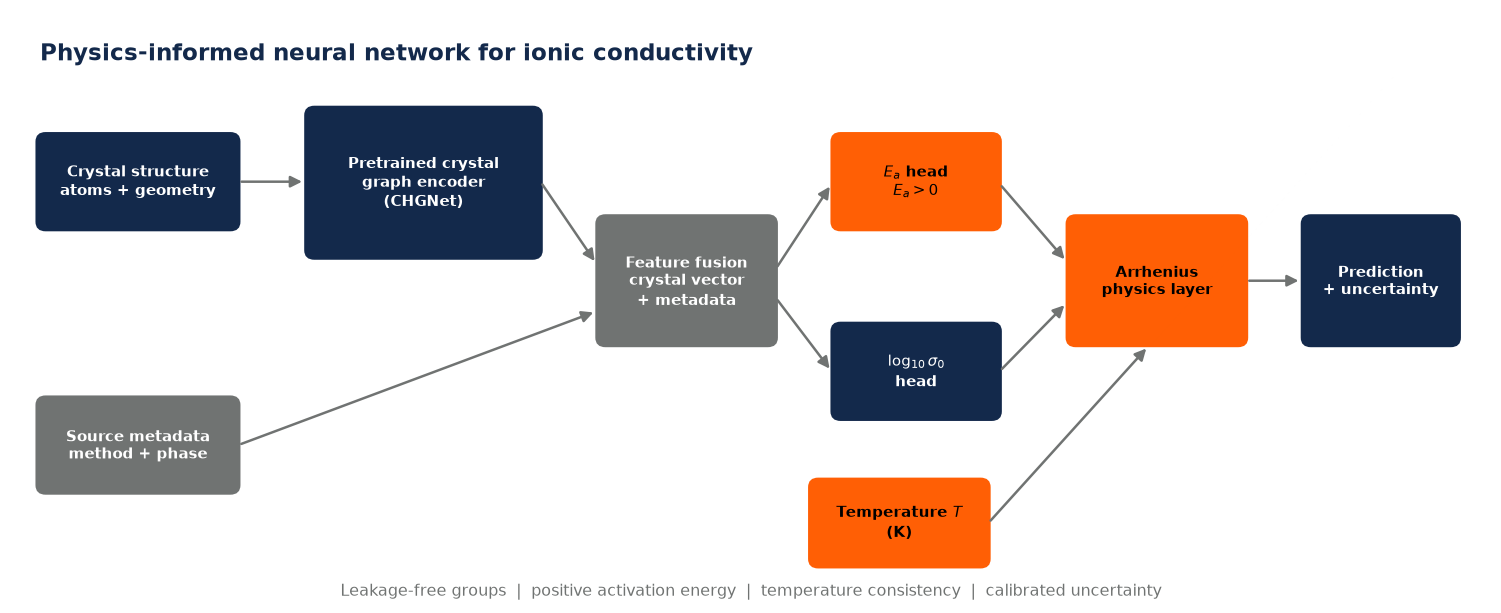

In [4]:
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch


def architecture_box(axis, xy, width, height, text, facecolor, textcolor="white"):
    box = FancyBboxPatch(
        xy, width, height,
        boxstyle="round,pad=0.03,rounding_size=0.08",
        linewidth=1.4, edgecolor=facecolor, facecolor=facecolor,
    )
    axis.add_patch(box)
    axis.text(
        xy[0] + width / 2, xy[1] + height / 2, text,
        ha="center", va="center", color=textcolor,
        fontsize=9.2, fontweight="bold", linespacing=1.22,
    )


def architecture_arrow(axis, start, end):
    axis.add_patch(FancyArrowPatch(
        start, end, arrowstyle="-|>", mutation_scale=14,
        linewidth=1.5, color=ILLINI_STORM,
        connectionstyle="arc3,rad=0.0",
    ))


fig, axis = plt.subplots(figsize=(12.4, 5.0), constrained_layout=True)
axis.set_xlim(0, 13.2)
axis.set_ylim(0, 5.6)
axis.axis("off")

axis.text(
    0.25, 5.3, "Physics-informed neural network for ionic conductivity",
    color=ILLINI_BLUE, fontsize=14, fontweight="bold", va="top",
)

architecture_box(axis, (0.25, 3.55), 1.75, 0.86, "Crystal structure\natoms + geometry", ILLINI_BLUE)
architecture_box(axis, (0.25, 1.05), 1.75, 0.86, "Source metadata\nmethod + phase", ILLINI_STORM)
architecture_box(axis, (7.15, 0.35), 1.55, 0.78, "Temperature $T$\n(K)", ILLINI_ORANGE, "black")

architecture_box(axis, (2.65, 3.28), 2.05, 1.38, "Pretrained crystal\ngraph encoder\n(CHGNet)", ILLINI_BLUE)
architecture_box(axis, (5.25, 2.45), 1.55, 1.18, "Feature fusion\ncrystal vector\n+ metadata", ILLINI_STORM)
architecture_box(axis, (7.35, 3.55), 1.45, 0.86, "$E_a$ head\n$E_a>0$", ILLINI_ORANGE, "black")
architecture_box(axis, (7.35, 1.75), 1.45, 0.86, "$\\log_{10}\\sigma_0$\nhead", ILLINI_BLUE)
architecture_box(axis, (9.45, 2.45), 1.55, 1.18, "Arrhenius\nphysics layer", ILLINI_ORANGE, "black")
architecture_box(axis, (11.55, 2.45), 1.35, 1.18, "Prediction\n+ uncertainty", ILLINI_BLUE)

architecture_arrow(axis, (2.02, 3.98), (2.62, 3.98))
architecture_arrow(axis, (4.72, 3.98), (5.22, 3.20))
architecture_arrow(axis, (2.02, 1.48), (5.22, 2.75))
architecture_arrow(axis, (6.82, 3.15), (7.32, 3.96))
architecture_arrow(axis, (6.82, 2.88), (7.32, 2.18))
architecture_arrow(axis, (8.82, 3.96), (9.42, 3.22))
architecture_arrow(axis, (8.82, 2.18), (9.42, 2.83))
architecture_arrow(axis, (8.72, 0.74), (10.15, 2.42))
architecture_arrow(axis, (11.02, 3.04), (11.52, 3.04))

axis.text(
    6.6, 0.05,
    "Leakage-free groups  |  positive activation energy  |  "
    "temperature consistency  |  calibrated uncertainty",
    color=ILLINI_STORM, fontsize=9.3, ha="center",
)

save_report_figure(fig, "figure_01_physics_informed_conductivity_model.png")
plt.show()


**Figure 1.** Long-term PI-ACGNN workflow. The crystal graph encoder learns a structural representation, which is fused with documented non-outcome metadata. Separate neural heads estimate a positive activation energy and conductivity prefactor; the Arrhenius layer combines them with temperature to predict log conductivity, while the ensemble reports uncertainty. The room-temperature conductivity head can be trained first, but the Arrhenius heads remain gated until multi-temperature measurements make their latent parameters identifiable.


## 4. Label normalization and acceptance checks

Every source value must retain its original value and unit. The normalization step creates new canonical columns rather than overwriting source data.

Accepted conductivity units in the first ingestion pass are S/cm, mS/cm, µS/cm, S/m, and mS/m. Resistivity values must be identified and converted separately using $\sigma=1/\rho$; they must never be passed to the conductivity converter as if they were conductivity.

In [5]:
UNIT_TO_S_CM = {
    "S/cm": 1.0,
    "mS/cm": 1e-3,
    "uS/cm": 1e-6,
    "µS/cm": 1e-6,
    "S/m": 1e-2,
    "mS/m": 1e-5,
}

REQUIRED_COLUMNS = [row[0] for row in DATA_SCHEMA if row[3]]


def conductivity_to_s_cm(value: float, unit: str) -> float:
    # Convert a positive conductivity value to S/cm.
    if unit not in UNIT_TO_S_CM:
        raise ValueError(f"Unsupported conductivity unit: {unit!r}")
    value = float(value)
    if not np.isfinite(value) or value <= 0:
        raise ValueError("Conductivity must be finite and strictly positive.")
    return value * UNIT_TO_S_CM[unit]


def material_group_key(row: pd.Series) -> str:
    # Keep polymorphs and repeated temperatures together during validation.
    for column in ("material_key", "mp_id", "structure_id"):
        value = row.get(column)
        if pd.notna(value) and str(value).strip():
            return str(value).strip()
    return f"{row.get('formula', 'unknown')}|{row.get('phase', 'unknown')}"


def prepare_conductivity_labels(frame: pd.DataFrame) -> pd.DataFrame:
    # Validate source labels and create canonical ML columns.
    missing = sorted(set(REQUIRED_COLUMNS) - set(frame.columns))
    if missing:
        raise KeyError(f"Missing required source columns: {missing}")

    prepared = frame.copy()
    prepared["sigma_S_cm"] = [
        conductivity_to_s_cm(value, unit)
        for value, unit in zip(
            prepared["conductivity_value"],
            prepared["conductivity_unit"],
        )
    ]
    prepared["temperature_K"] = pd.to_numeric(
        prepared["temperature_K"], errors="raise"
    )
    if not prepared["temperature_K"].between(100, 2000).all():
        raise ValueError("Review temperatures outside the broad 100–2000 K audit range.")
    if not prepared["mobile_ion"].eq(MOBILE_ION).all():
        raise ValueError("Model v1 accepts Li-ion records only.")
    if not prepared["conductivity_type"].str.lower().eq("ionic").all():
        raise ValueError("Non-ionic or ambiguous conductivity records must be separated.")

    prepared[TARGET_COLUMN] = np.log10(prepared["sigma_S_cm"])
    prepared["group_material"] = prepared.apply(material_group_key, axis=1)
    return prepared


intake_template = pd.DataFrame(columns=[row[0] for row in DATA_SCHEMA])
INTAKE_TEMPLATE_PATH = ROOT / "data/processed/ionic_conductivity_intake_template.csv"
INTAKE_TEMPLATE_PATH.parent.mkdir(parents=True, exist_ok=True)
intake_template.to_csv(INTAKE_TEMPLATE_PATH, index=False)
display(intake_template)
print("Saved Day 2 intake template:", INTAKE_TEMPLATE_PATH)

,record_id,material_key,mp_id,formula,chemsys,structure_id,phase,mobile_ion,material_class,conductivity_value,conductivity_unit,temperature_K,conductivity_type,label_origin,measurement_method,uncertainty,reference,notes


Saved Day 2 intake template: /Users/zhy/Downloads/battery_ml_starter/data/processed/ionic_conductivity_intake_template.csv


## 5. Leakage-free validation contract

### Required splitting rules

1. All temperatures, repeat measurements, and methods for one resolved material remain in the same fold through `group_material`.
2. The final generalization test holds out complete `chemsys` groups when the dataset is large enough.
3. Imputation, scaling, encoding, feature selection, and tuning are fitted only on training folds.
4. Duplicate literature records are resolved before splitting, not after.

### Variables excluded from the initial feature set

- Conductivity at another temperature for the same material
- Activation energy fitted from the same conductivity measurements
- Arrhenius intercept fitted from the same measurements
- Any manually assigned high/low-conductivity label
- Material identifiers or source identifiers
- Post hoc variables calculated using the target

Migration barriers or defect energies may later be evaluated in a separate enhanced model, but they will not be mixed into the composition-and-structure baseline without a clear availability and cost definition.

### Planned metrics

- MAE and RMSE in $\log_{10}(\mathrm{S/cm})$
- $R^2$
- Multiplicative error factor, $10^{\mathrm{MAE}}$
- Bootstrap confidence intervals grouped by material or chemical system
- Error by temperature range, chemical family, label origin, and applicability domain

In [6]:
PROJECT_CONTRACT = pd.Series(
    {
        "target": TARGET_COLUMN,
        "canonical_unit": "S/cm",
        "reference_temperature_K": REFERENCE_TEMPERATURE_K,
        "mobile_ion": MOBILE_ION,
        "material_scope": MATERIAL_SCOPE,
        "row_definition": "one resolved material-phase/condition record",
        "primary_group": "linked material-or-DOI component",
        "official_holdout": "OBELiX test split",
        "strong_holdout_group": "chemsys",
        "label_source": "OBELiX experimental room-temperature conductivity",
        "next_action": "audit labels and structure coverage before neural-network training",
    },
    name="project decision",
)
display(PROJECT_CONTRACT.to_frame())


,project decision
target,log10_sigma_S_cm
canonical_unit,S/cm
reference_temperature_K,298.15
mobile_ion,Li
material_scope,inorganic solid-state lithium-ion conductor
row_definition,one resolved material-phase/condition record
primary_group,linked material-or-DOI component
official_holdout,OBELiX test split
strong_holdout_group,chemsys
label_source,OBELiX experimental room-temperature conductivity


## 6. Figure standard for the ML project

All analytical figures will follow the supplied report layout and the official UIUC brand palette: Illini Blue (`#13294B`) and Illini Orange (`#FF5F05`) are dominant, with Storm gray used only for neutral baselines. Figures use a white background, bold panel labels, units on every quantitative axis, reference lines where decisions depend on a threshold or ideal value, legends outside dense data regions, and a complete caption stating the comparison and sample context. Figures are saved as 300-dpi PNG files in `figures/` with stable descriptive names.

## 7. Foundation checkpoint

The target, scope, units, staged neural architecture, and leakage rules are fixed. Materials Project remains the candidate-structure source for later screening, while conductivity supervision comes from a separately cited experimental dataset.

The next section imports OBELiX, preserves its official train/test split and DOI provenance, excludes censored values from exact-label regression, quantifies repeated-measurement variability, and determines which neural-network stages are currently supported by the data.


## 8. Literature-backed conductivity dataset

The first supervised dataset is [OBELiX](https://doi.org/10.1039/d5dd00441a), a domain-expert-curated collection of 599 synthesized lithium solid electrolytes with experimental room-temperature ionic conductivity, composition, space group, lattice parameters, source DOI, and 321 associated CIF structures. The official repository distributes the data under CC BY 4.0 and provides a train/test split designed to keep shared compositions and publications together.

This notebook uses the official full, train, and test CSV files from the [NRC-Mila repository](https://github.com/NRC-Mila/OBELiX) at upstream revision `4eaac889809dd489e3bae468c45d5c0e02b9147a`. Source hashes are checked before processing.

### Acceptance rules

- Preserve every original label string and source DOI.
- Treat values reported as “less than” a limit as **censored**, not as exact regression labels.
- Standardize the paper's room-temperature values to a nominal 298.15 K while marking that the exact measurement temperature is unavailable per row.
- Preserve direct, close-match, and unavailable structure categories.
- Keep records linked by composition or DOI in one cross-validation group.
- Retain the authors' official split as the primary held-out benchmark.


In [7]:
from hashlib import sha256

from pymatgen.core import Composition

OBELIX_SOURCE_REVISION = "4eaac889809dd489e3bae468c45d5c0e02b9147a"
OBELIX_PATHS = {
    "all": ROOT / "data/raw/obelix_all.csv",
    "train": ROOT / "data/raw/obelix_train.csv",
    "test": ROOT / "data/raw/obelix_test.csv",
}
OBELIX_SHA256 = {
    "all": "54f6265ef84d16a919d08c6815f14b0fd7465fa00090bee2511c16c042e57f3c",
    "train": "01d87779862807e24bc45bb2c759852f892390b99f9340f13906c54805aa8776",
    "test": "b2c266eb74e22f403743d52959bea7c43b1531a850994870a70dd909200e5297",
}


def file_sha256(path: Path) -> str:
    digest = sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(1 << 20), b""):
            digest.update(block)
    return digest.hexdigest()


source_hashes = {name: file_sha256(path) for name, path in OBELIX_PATHS.items()}
assert source_hashes == OBELIX_SHA256, "OBELiX source file hash mismatch."

obelix = pd.read_csv(OBELIX_PATHS["all"])
train_ids = set(pd.read_csv(OBELIX_PATHS["train"])["ID"])
test_ids = set(pd.read_csv(OBELIX_PATHS["test"])["ID"])
assert train_ids.isdisjoint(test_ids)
assert train_ids | test_ids == set(obelix["ID"])
assert not obelix["ID"].duplicated().any()


def composition_metadata(formula: str) -> tuple[str, str]:
    # OBELiX has one hydrate formula containing an asterisk separator.
    composition = Composition(str(formula).replace("*", ""))
    normalized = composition.alphabetical_formula.replace(" ", "")
    return normalized, composition.chemical_system


composition_info = obelix["Reduced Composition"].map(composition_metadata)
obelix["normalized_formula"] = composition_info.map(lambda item: item[0])
obelix["chemsys"] = composition_info.map(lambda item: item[1])
obelix["material_key"] = (
    obelix["normalized_formula"]
    + "|SG"
    + obelix["Space group #"].astype("Int64").astype(str)
)

source_label = obelix["Ionic conductivity (S cm-1)"].astype("string").str.strip()
is_censored = source_label.str.startswith("<", na=False)
numeric_label = pd.to_numeric(
    source_label.str.replace("<", "", regex=False), errors="coerce"
)
label_status = np.select(
    [is_censored, numeric_label.gt(0)],
    ["censored_upper_bound", "exact"],
    default="missing_or_invalid",
)

has_cif = obelix["Cif ID"].astype("string").str.lower().isin(["done", "available"])
is_close_match = (
    obelix["close match"].astype("string").str.lower().eq("yes").fillna(False)
)
structure_match = np.select(
    [is_close_match.to_numpy(dtype=bool), has_cif.to_numpy(dtype=bool)],
    ["close-match CIF", "matched CIF"],
    default="no CIF",
)
source_split = np.where(obelix["ID"].isin(train_ids), "train", "test")

standardized = pd.DataFrame({
    "record_id": "OBELIX:" + obelix["ID"].astype(str),
    "material_key": obelix["material_key"],
    "mp_id": pd.NA,
    "formula": obelix["Reduced Composition"],
    "chemsys": obelix["chemsys"],
    "structure_id": np.where(has_cif, "OBELIX:" + obelix["ID"].astype(str), pd.NA),
    "phase": obelix["Space group"],
    "mobile_ion": MOBILE_ION,
    "material_class": obelix["Family"].fillna("unclassified solid electrolyte"),
    "conductivity_value": numeric_label,
    "conductivity_unit": "S/cm",
    "temperature_K": REFERENCE_TEMPERATURE_K,
    "conductivity_type": "ionic",
    "label_origin": "experimental",
    "measurement_method": pd.NA,
    "uncertainty": np.nan,
    "reference": obelix["DOI"],
    "notes": obelix["note"],
    "source_dataset": "OBELiX",
    "source_record_id": obelix["ID"],
    "source_split": source_split,
    "source_label_text": source_label,
    "label_status": label_status,
    "temperature_is_nominal": True,
    "space_group_number": obelix["Space group #"],
    "lattice_a_A": obelix["a"],
    "lattice_b_A": obelix["b"],
    "lattice_c_A": obelix["c"],
    "alpha_deg": obelix["alpha"],
    "beta_deg": obelix["beta"],
    "gamma_deg": obelix["gamma"],
    "cif_status": obelix["Cif ID"],
    "structure_match": structure_match,
})

exact_mask = standardized["label_status"].eq("exact")
clean_obelix = prepare_conductivity_labels(standardized.loc[exact_mask].copy())
assert np.isfinite(clean_obelix[TARGET_COLUMN]).all()
assert clean_obelix["record_id"].is_unique


In [8]:
def split_dois(value) -> list[str]:
    if pd.isna(value):
        return []
    return [
        token.strip().lower()
        for token in str(value).split("|")
        if token.strip()
    ]


def build_linked_groups(frame: pd.DataFrame) -> pd.Series:
    # Union-find links rows that share either material identity or source DOI.
    parent = list(range(len(frame)))

    def find(index):
        while parent[index] != index:
            parent[index] = parent[parent[index]]
            index = parent[index]
        return index

    def union(left, right):
        root_left, root_right = find(left), find(right)
        if root_left != root_right:
            parent[root_right] = root_left

    token_owner = {}
    for position, (_, row) in enumerate(frame.iterrows()):
        tokens = [f"material::{row['material_key']}"]
        tokens.extend(f"doi::{doi}" for doi in split_dois(row["reference"]))
        for token in tokens:
            if token in token_owner:
                union(position, token_owner[token])
            else:
                token_owner[token] = position

    roots = [find(position) for position in range(len(frame))]
    labels = {root: f"linked_{number:04d}" for number, root in enumerate(sorted(set(roots)), 1)}
    return pd.Series([labels[root] for root in roots], index=frame.index)


clean_obelix["group_linked"] = build_linked_groups(clean_obelix)
cross_split_groups = (
    clean_obelix.groupby("group_linked")["source_split"].nunique().gt(1).sum()
)
assert cross_split_groups == 0, "Official split leaks a linked composition/DOI group."

material_sizes = clean_obelix.groupby("group_material").size()
repeated_materials = material_sizes[material_sizes.ge(2)].index
repeat_mask = clean_obelix["group_material"].isin(repeated_materials)
repeat_abs_deviation = (
    clean_obelix.loc[repeat_mask, TARGET_COLUMN]
    - clean_obelix.loc[repeat_mask].groupby("group_material")[TARGET_COLUMN].transform("median")
).abs()

OUTPUT_CONDUCTIVITY_PATH = ROOT / "data/processed/obelix_conductivity_clean.csv"
OUTPUT_CONDUCTIVITY_PATH.parent.mkdir(parents=True, exist_ok=True)
clean_obelix.to_csv(OUTPUT_CONDUCTIVITY_PATH, index=False)

obelix_audit = pd.Series({
    "source_rows": len(standardized),
    "exact_positive_labels": len(clean_obelix),
    "censored_upper_bounds_preserved_but_excluded": int((label_status == "censored_upper_bound").sum()),
    "exact_labels_with_any_CIF": int(clean_obelix["structure_match"].ne("no CIF").sum()),
    "exact_labels_with_directly_matched_CIF": int(clean_obelix["structure_match"].eq("matched CIF").sum()),
    "unique_material_groups": clean_obelix["group_material"].nunique(),
    "repeated_material_groups": len(repeated_materials),
    "rows_in_repeated_material_groups": int(repeat_mask.sum()),
    "observed_repeat_mean_absolute_deviation_dex": repeat_abs_deviation.mean(),
    "unique_chemical_systems": clean_obelix["chemsys"].nunique(),
    "linked_groups_crossing_official_split": int(cross_split_groups),
}, name="value")

split_summary = clean_obelix.groupby("source_split").agg(
    exact_labels=("record_id", "size"),
    material_groups=("group_material", "nunique"),
    linked_groups=("group_linked", "nunique"),
    labels_with_CIF=("structure_match", lambda values: values.ne("no CIF").sum()),
    median_log10_sigma=(TARGET_COLUMN, "median"),
).reindex(["train", "test"])

display(pd.Series(source_hashes, name="SHA-256").to_frame())
display(obelix_audit.to_frame())
display(split_summary)
print("Saved cleaned OBELiX table:", OUTPUT_CONDUCTIVITY_PATH)


,SHA-256
all,54f6265ef84d16a919d08c6815f14b0fd7465fa00090be...
train,01d87779862807e24bc45bb2c759852f892390b99f9340...
test,b2c266eb74e22f403743d52959bea7c43b1531a8509948...


,value
source_rows,599.000000
exact_positive_labels,562.000000
censored_upper_bounds_preserved_but_excluded,37.000000
exact_labels_with_any_CIF,287.000000
exact_labels_with_directly_matched_CIF,226.000000
unique_material_groups,487.000000
repeated_material_groups,48.000000
rows_in_repeated_material_groups,123.000000
observed_repeat_mean_absolute_deviation_dex,0.408245
unique_chemical_systems,192.000000


,exact_labels,material_groups,linked_groups,labels_with_CIF,median_log10_sigma
source_split,,,,,
train,449,377,110,226,-4.084073
test,113,110,40,61,-4.124939


Saved cleaned OBELiX table: /Users/zhy/Downloads/battery_ml_starter/data/processed/obelix_conductivity_clean.csv


### Audit interpretation

The exact-label regression table contains 562 records; 37 upper-bound values remain in the raw source files but are excluded from ordinary regression. Only 287 exact-label records have an associated CIF and 61 of those are close structural matches, so geometric modeling is substantially more data-limited than composition modeling.

Repeated measurements are not silently averaged. They remain in the table, share a validation group, and expose experimental variability. After canonicalizing equivalent formula strings, the current snapshot contains 123 exact measurements in 48 repeated material groups. Their observed mean absolute deviation from each material's median is 0.41 dex, consistent with the 0.41 dex value reported by the OBELiX authors; this becomes a practical warning against implausibly low test errors.


Saved figure: /Users/zhy/Downloads/battery_ml_starter/figures/figure_02_obelix_data_audit.png


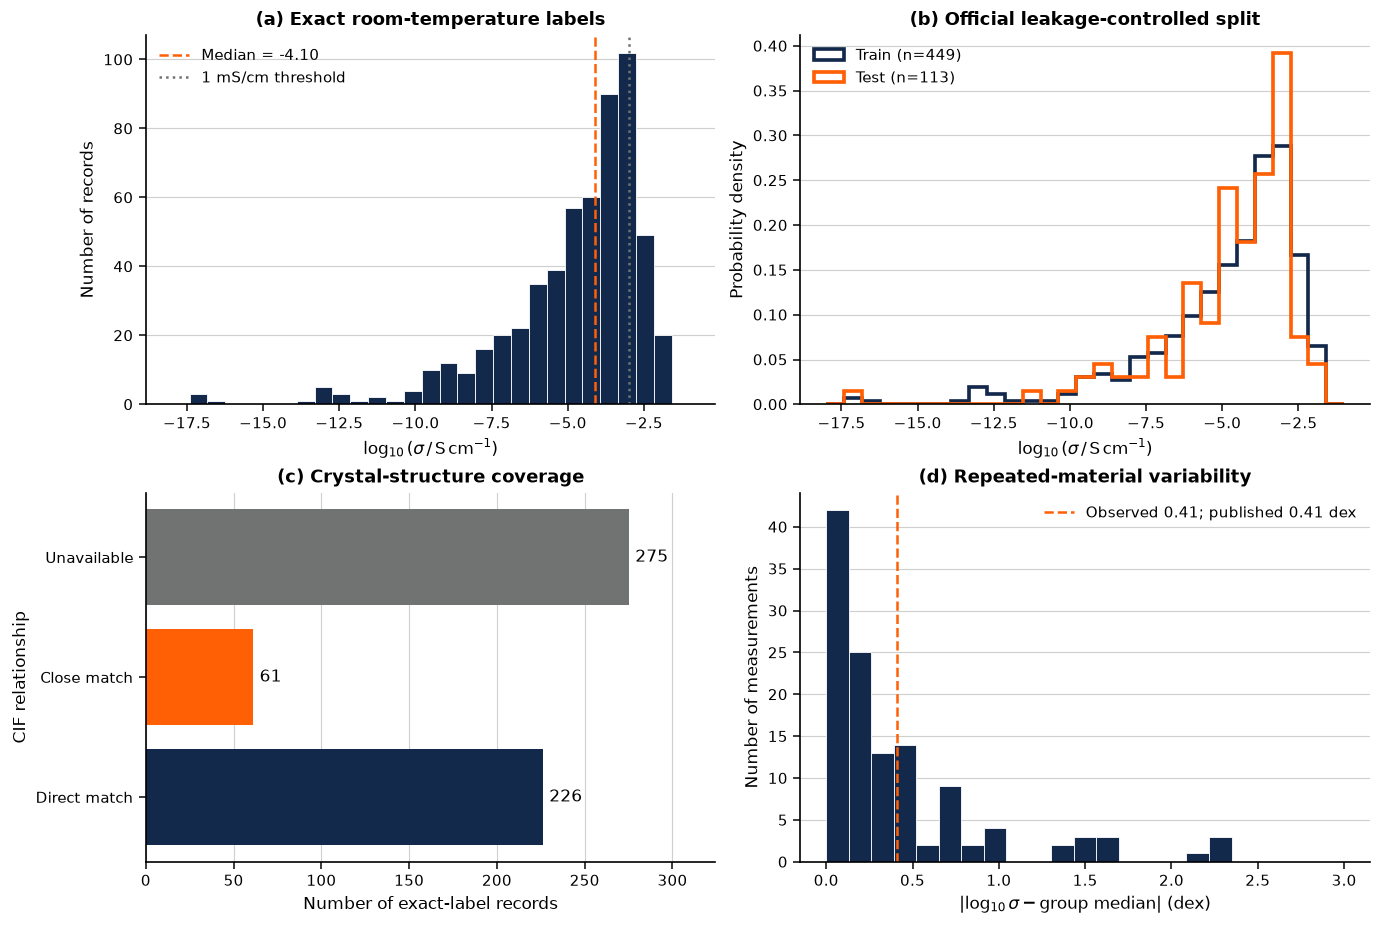

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(11.4, 7.6), constrained_layout=True)

# (a) Exact target distribution
target_values = clean_obelix[TARGET_COLUMN]
bins = np.linspace(np.floor(target_values.min()), np.ceil(target_values.max()), 30)
axes[0, 0].hist(target_values, bins=bins, color=ILLINI_BLUE, edgecolor="white", linewidth=0.5)
axes[0, 0].axvline(target_values.median(), color=ILLINI_ORANGE, linestyle="--",
                   label=f"Median = {target_values.median():.2f}")
axes[0, 0].axvline(-3, color=ILLINI_STORM, linestyle=":", label="1 mS/cm threshold")
axes[0, 0].set_title("(a) Exact room-temperature labels")
axes[0, 0].set_xlabel(r"$\log_{10}(\sigma\,/\,\mathrm{S\,cm^{-1}})$")
axes[0, 0].set_ylabel("Number of records")
axes[0, 0].legend(loc="upper left")
finish_axis(axes[0, 0], "y")

# (b) Official split distribution check
for split, color in [("train", ILLINI_BLUE), ("test", ILLINI_ORANGE)]:
    values = clean_obelix.loc[clean_obelix["source_split"].eq(split), TARGET_COLUMN]
    axes[0, 1].hist(values, bins=bins, density=True, histtype="step", linewidth=2.2,
                    color=color, label=f"{split.title()} (n={len(values)})")
axes[0, 1].set_title("(b) Official leakage-controlled split")
axes[0, 1].set_xlabel(r"$\log_{10}(\sigma\,/\,\mathrm{S\,cm^{-1}})$")
axes[0, 1].set_ylabel("Probability density")
axes[0, 1].legend(loc="upper left")
finish_axis(axes[0, 1], "y")

# (c) Structure coverage for exact labels
structure_order = ["matched CIF", "close-match CIF", "no CIF"]
structure_counts = clean_obelix["structure_match"].value_counts().reindex(structure_order)
bars = axes[1, 0].barh(
    ["Direct match", "Close match", "Unavailable"], structure_counts,
    color=[ILLINI_BLUE, ILLINI_ORANGE, ILLINI_STORM],
)
axes[1, 0].bar_label(bars, padding=4)
axes[1, 0].set_xlim(0, structure_counts.max() * 1.18)
axes[1, 0].set_title("(c) Crystal-structure coverage")
axes[1, 0].set_xlabel("Number of exact-label records")
axes[1, 0].set_ylabel("CIF relationship")
finish_axis(axes[1, 0], "x")

# (d) Experimental repeatability
repeat_bins = np.linspace(0, max(3.0, repeat_abs_deviation.max()), 24)
axes[1, 1].hist(repeat_abs_deviation, bins=repeat_bins, color=ILLINI_BLUE,
                edgecolor="white", linewidth=0.5)
axes[1, 1].axvline(repeat_abs_deviation.mean(), color=ILLINI_ORANGE, linestyle="--",
                   label=f"Observed {repeat_abs_deviation.mean():.2f}; published 0.41 dex")
axes[1, 1].set_title("(d) Repeated-material variability")
axes[1, 1].set_xlabel(r"$|\log_{10}\sigma-\mathrm{group\ median}|$ (dex)")
axes[1, 1].set_ylabel("Number of measurements")
axes[1, 1].legend(loc="upper right")
finish_axis(axes[1, 1], "y")

save_report_figure(fig, "figure_02_obelix_data_audit.png")
plt.show()


**Figure 2.** OBELiX ingestion and quality audit. (a) Distribution of 562 exact experimental room-temperature conductivity labels; the gray reference denotes the commonly used 1 mS/cm fast-conductor threshold. (b) The authors' official train (449) and test (113) subsets retain similar target distributions while preventing shared-composition or shared-publication leakage. (c) Only 287 exact-label entries have a CIF, including 61 close matches. (d) After canonicalizing equivalent formula strings, the current source snapshot contains 123 exact measurements in 48 repeated material groups; their mean absolute deviation from the group median is 0.41 dex, consistent with the published experimental floor.


## 9. Identifiability gate for the physics-informed model

OBELiX provides one nominal room-temperature target per record. At a single temperature $T_0$,

$$
y(T_0)=\log_{10}\sigma_0-\frac{E_a}{k_{\mathrm B}T_0\ln 10},
$$

so infinitely many $(\sigma_0,E_a)$ pairs produce the same $y(T_0)$. Separate activation-energy and prefactor heads are therefore **not identifiable from OBELiX alone**. Fitting them now would add physical-looking parameters without experimental support.

The defensible sequence is:

1. Predict $\log_{10}\sigma_{\mathrm{RT}}$ with a composition MLP and transfer-learned crystal GNN.
2. Calibrate uncertainty against the held-out OBELiX test set and the repeated-measurement noise scale.
3. Add multi-temperature conductivity series with material identities and measurement conditions.
4. Only then fit the Arrhenius layer and test whether its constraints improve extrapolation.


In [10]:
MODEL_READINESS = pd.DataFrame([
    {
        "model stage": "Composition-only MLP",
        "usable exact labels": len(clean_obelix),
        "status": "ready for grouped baseline",
        "decision": "train first",
    },
    {
        "model stage": "Room-temperature crystal GNN",
        "usable exact labels": int(clean_obelix["structure_match"].ne("no CIF").sum()),
        "status": "small-data transfer learning only",
        "decision": "freeze encoder initially",
    },
    {
        "model stage": "Direct-match crystal GNN sensitivity check",
        "usable exact labels": int(clean_obelix["structure_match"].eq("matched CIF").sum()),
        "status": "higher-confidence structure subset",
        "decision": "compare with all-CIF subset",
    },
    {
        "model stage": "Arrhenius PI-ACGNN",
        "usable exact labels": 0,
        "status": "not identifiable from room-temperature-only data",
        "decision": "wait for multi-temperature labels",
    },
])
display(MODEL_READINESS)


,model stage,usable exact labels,status,decision
0,Composition-only MLP,562,ready for grouped baseline,train first
1,Room-temperature crystal GNN,287,small-data transfer learning only,freeze encoder initially
2,Direct-match crystal GNN sensitivity check,226,higher-confidence structure subset,compare with all-CIF subset
3,Arrhenius PI-ACGNN,0,not identifiable from room-temperature-only data,wait for multi-temperature labels


## 10. Neural-baseline decision rule

The first trainable model is a composition-only MLP on the official OBELiX split, with linked material/DOI groups retained during cross-validation. The model must beat a training-median reference on the untouched test set before it is allowed to rank Materials Project candidates. This gate prevents a complex-looking neural network from being used when it has not demonstrated predictive value.


## 11. Composition-only neural baseline

The OBELiX study found that small-data neural and graph models can overfit and that cross-validation performance may not transfer to its carefully constructed test split. Our baseline therefore adds four safeguards:

1. Element vocabulary is learned from the training set only, with an explicit unknown-element fraction.
2. Both inputs and the log-conductivity target are scaled inside each training fold.
3. Cross-validation groups all records connected by composition or source DOI.
4. Predictions average multiple neural-network initializations and must beat a training-median reference before Materials Project screening is permitted.

The MLP uses atom fractions plus compact stoichiometric and elemental-property summaries. These are composition descriptors—not structural or simulation-derived inputs—so this model is a conservative first neural baseline rather than the final PI-ACGNN.


In [11]:
import warnings

from pymatgen.core import Element
from sklearn.compose import TransformedTargetRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold
from sklearn.neighbors import NearestNeighbors
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 432
MODEL_TARGET = TARGET_COLUMN

model_data = clean_obelix.copy()
model_train = model_data.loc[model_data["source_split"].eq("train")].copy()
model_test = model_data.loc[model_data["source_split"].eq("test")].copy()


def parse_composition(formula):
    return Composition(str(formula).replace("*", ""))


train_compositions = model_train["formula"].map(parse_composition)
ELEMENT_VOCAB = sorted({str(element) for composition in train_compositions for element in composition.elements})


def safe_element_property(element, name):
    value = getattr(element, name, None)
    try:
        return float(value) if value is not None else np.nan
    except (TypeError, ValueError):
        return np.nan


def composition_features(formulas: pd.Series, vocabulary=None) -> pd.DataFrame:
    vocabulary = ELEMENT_VOCAB if vocabulary is None else vocabulary
    rows = []
    for formula in formulas:
        composition = parse_composition(formula)
        fractions = composition.fractional_composition.get_el_amt_dict()
        fraction_values = np.array(list(fractions.values()), dtype=float)
        row = {
            f"frac_{element}": fractions.get(element, 0.0)
            for element in vocabulary
        }
        row["unknown_element_fraction"] = sum(
            fraction for element, fraction in fractions.items()
            if element not in vocabulary
        )
        row["n_elements"] = len(fractions)
        row["li_fraction"] = fractions.get("Li", 0.0)
        row["composition_entropy"] = float(
            -(fraction_values * np.log(fraction_values)).sum()
        )
        row["max_element_fraction"] = float(fraction_values.max())
        row["min_element_fraction"] = float(fraction_values.min())

        for property_name, output_name in [
            ("Z", "mean_atomic_number"),
            ("atomic_mass", "mean_atomic_mass"),
            ("X", "mean_electronegativity"),
            ("row", "mean_periodic_row"),
            ("group", "mean_periodic_group"),
        ]:
            numerator = denominator = 0.0
            property_values = []
            for symbol, fraction in fractions.items():
                value = safe_element_property(Element(symbol), property_name)
                if np.isfinite(value):
                    numerator += fraction * value
                    denominator += fraction
                    property_values.append(value)
            row[output_name] = numerator / denominator if denominator else 0.0
            if property_name == "X":
                row["electronegativity_range"] = (
                    max(property_values) - min(property_values)
                    if property_values else 0.0
                )
        rows.append(row)
    return pd.DataFrame(rows, index=formulas.index)


X_train = composition_features(model_train["formula"])
X_test = composition_features(model_test["formula"])
y_train = model_train[MODEL_TARGET]
y_test = model_test[MODEL_TARGET]
cv_groups = model_train["group_linked"]

print(
    f"Training rows: {len(X_train)} | test rows: {len(X_test)} | "
    f"features: {X_train.shape[1]} | training elements: {len(ELEMENT_VOCAB)}"
)


Training rows: 449 | test rows: 113 | features: 64 | training elements: 52


In [12]:
MLP_CONFIGS = [
    {"hidden_layer_sizes": (16,), "alpha": 1.0},
    {"hidden_layer_sizes": (32,), "alpha": 1.0},
    {"hidden_layer_sizes": (64, 32), "alpha": 1.0},
    {"hidden_layer_sizes": (32,), "alpha": 10.0},
    {"hidden_layer_sizes": (64, 32), "alpha": 10.0},
    {"hidden_layer_sizes": (64, 32), "alpha": 100.0},
]
TUNING_SEEDS = [17, 43]


def config_label(config):
    layers = "×".join(str(width) for width in config["hidden_layer_sizes"])
    return f"{layers}; α={config['alpha']:g}"


def build_mlp(config, seed):
    feature_model = Pipeline([
        ("scale", StandardScaler()),
        ("mlp", MLPRegressor(
            hidden_layer_sizes=config["hidden_layer_sizes"],
            alpha=config["alpha"],
            solver="lbfgs",
            activation="relu",
            max_iter=2000,
            tol=1e-5,
            random_state=seed,
        )),
    ])
    return TransformedTargetRegressor(
        regressor=feature_model,
        transformer=StandardScaler(),
    )


warnings.filterwarnings("ignore", category=ConvergenceWarning)
grouped_cv = GroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_splits = list(grouped_cv.split(X_train, y_train, cv_groups))

cv_rows = []
for config_index, config in enumerate(MLP_CONFIGS):
    for fold, (fit_index, validation_index) in enumerate(cv_splits, start=1):
        fold_predictions = []
        for seed in TUNING_SEEDS:
            fold_model = build_mlp(config, seed)
            fold_model.fit(X_train.iloc[fit_index], y_train.iloc[fit_index])
            fold_predictions.append(fold_model.predict(X_train.iloc[validation_index]))
        prediction = np.mean(fold_predictions, axis=0)
        truth = y_train.iloc[validation_index]
        cv_rows.append({
            "config_index": config_index,
            "config": config_label(config),
            "fold": fold,
            "validation_rows": len(validation_index),
            "validation_groups": cv_groups.iloc[validation_index].nunique(),
            "MAE_dex": mean_absolute_error(truth, prediction),
            "RMSE_dex": np.sqrt(mean_squared_error(truth, prediction)),
            "R2": r2_score(truth, prediction),
        })

mlp_cv_results = pd.DataFrame(cv_rows)
mlp_cv_summary = mlp_cv_results.groupby(["config_index", "config"]).agg(
    mean_MAE_dex=("MAE_dex", "mean"),
    std_MAE_dex=("MAE_dex", "std"),
    mean_RMSE_dex=("RMSE_dex", "mean"),
    mean_R2=("R2", "mean"),
).reset_index()

BEST_CONFIG_INDEX = int(mlp_cv_summary.loc[mlp_cv_summary["mean_MAE_dex"].idxmin(), "config_index"])
BEST_MLP_CONFIG = MLP_CONFIGS[BEST_CONFIG_INDEX]
mlp_cv_summary["selected"] = mlp_cv_summary["config_index"].eq(BEST_CONFIG_INDEX)

MLP_CV_PATH = ROOT / "data/processed/obelix_mlp_cv_results.csv"
mlp_cv_results.to_csv(MLP_CV_PATH, index=False)
display(mlp_cv_summary.style.format({
    "mean_MAE_dex": "{:.3f}", "std_MAE_dex": "{:.3f}",
    "mean_RMSE_dex": "{:.3f}", "mean_R2": "{:.3f}",
}))
print("Selected configuration:", config_label(BEST_MLP_CONFIG))


,config_index,config,mean_MAE_dex,std_MAE_dex,mean_RMSE_dex,mean_R2,selected
0,0,16; α=1,1.512,0.487,2.323,-0.047,False
1,1,32; α=1,1.501,0.556,2.275,-0.003,False
2,2,64×32; α=1,1.538,0.569,2.290,-0.010,False
3,3,32; α=10,1.467,0.606,2.095,0.153,True
4,4,64×32; α=10,1.478,0.539,2.102,0.147,False
5,5,64×32; α=100,1.729,0.466,2.358,-0.080,False


Selected configuration: 32; α=10


In [13]:
FINAL_ENSEMBLE_SEEDS = [11, 23, 37, 53, 71, 89, 107, 131, 149, 173]
final_models = []
test_prediction_members = []
for seed in FINAL_ENSEMBLE_SEEDS:
    model = build_mlp(BEST_MLP_CONFIG, seed)
    model.fit(X_train, y_train)
    final_models.append(model)
    test_prediction_members.append(model.predict(X_test))

test_prediction_matrix = np.vstack(test_prediction_members)
test_prediction = test_prediction_matrix.mean(axis=0)
test_model_std = test_prediction_matrix.std(axis=0, ddof=1)
test_absolute_error = np.abs(y_test.to_numpy() - test_prediction)

# Grouped out-of-fold residuals calibrate a train-only 90% error interval.
oof_prediction = np.full(len(X_train), np.nan)
for fit_index, validation_index in cv_splits:
    fold_members = []
    for seed in TUNING_SEEDS:
        fold_model = build_mlp(BEST_MLP_CONFIG, seed)
        fold_model.fit(X_train.iloc[fit_index], y_train.iloc[fit_index])
        fold_members.append(fold_model.predict(X_train.iloc[validation_index]))
    oof_prediction[validation_index] = np.mean(fold_members, axis=0)

oof_absolute_error = np.abs(y_train.to_numpy() - oof_prediction)
interval_half_width = float(np.quantile(oof_absolute_error, 0.90, method="higher"))
interval_lower = test_prediction - interval_half_width
interval_upper = test_prediction + interval_half_width
interval_coverage = np.mean(
    (y_test.to_numpy() >= interval_lower) & (y_test.to_numpy() <= interval_upper)
)

# Resample complete linked groups for a chemistry-aware MAE interval.
rng = np.random.default_rng(RANDOM_STATE)
test_group_values = model_test["group_linked"].unique()
group_to_positions = {
    group: np.flatnonzero(model_test["group_linked"].to_numpy() == group)
    for group in test_group_values
}
bootstrap_mae = []
for _ in range(2000):
    sampled_groups = rng.choice(test_group_values, size=len(test_group_values), replace=True)
    positions = np.concatenate([group_to_positions[group] for group in sampled_groups])
    bootstrap_mae.append(mean_absolute_error(
        y_test.to_numpy()[positions], test_prediction[positions]
    ))

mlp_test_mae = mean_absolute_error(y_test, test_prediction)
median_reference_prediction = np.repeat(y_train.median(), len(y_test))
median_reference_mae = mean_absolute_error(y_test, median_reference_prediction)
MODEL_PASSES_SCREENING_GATE = bool(mlp_test_mae < median_reference_mae)

mlp_test_metrics = pd.Series({
    "grouped_CV_MAE_dex": mlp_cv_summary.loc[
        mlp_cv_summary["selected"], "mean_MAE_dex"
    ].iloc[0],
    "test_MAE_dex": mlp_test_mae,
    "test_MAE_group_bootstrap_95pct_low": np.quantile(bootstrap_mae, 0.025),
    "test_MAE_group_bootstrap_95pct_high": np.quantile(bootstrap_mae, 0.975),
    "test_RMSE_dex": np.sqrt(mean_squared_error(y_test, test_prediction)),
    "test_R2": r2_score(y_test, test_prediction),
    "multiplicative_error_factor": 10 ** mlp_test_mae,
    "training_median_reference_MAE_dex": median_reference_mae,
    "mean_ensemble_std_dex": test_model_std.mean(),
    "uncertainty_absolute_error_Spearman": pd.Series(test_model_std).corr(
        pd.Series(test_absolute_error), method="spearman"
    ),
    "train_only_90pct_interval_half_width_dex": interval_half_width,
    "test_interval_coverage": interval_coverage,
    "passes_MP_screening_gate": MODEL_PASSES_SCREENING_GATE,
}, name="value")

mlp_test_predictions = model_test[[
    "record_id", "formula", "chemsys", "group_material", "group_linked",
    "structure_match", MODEL_TARGET,
]].copy()
mlp_test_predictions["predicted_log10_sigma_S_cm"] = test_prediction
mlp_test_predictions["ensemble_std_dex"] = test_model_std
mlp_test_predictions["absolute_error_dex"] = test_absolute_error
mlp_test_predictions["interval90_lower"] = interval_lower
mlp_test_predictions["interval90_upper"] = interval_upper
mlp_test_predictions["interval90_contains_observation"] = (
    (y_test.to_numpy() >= interval_lower) & (y_test.to_numpy() <= interval_upper)
)

MLP_TEST_PATH = ROOT / "data/processed/obelix_mlp_test_predictions.csv"
mlp_test_predictions.to_csv(MLP_TEST_PATH, index=False)
display(mlp_test_metrics.to_frame())
print(
    "Screening decision:",
    "PASS" if MODEL_PASSES_SCREENING_GATE else "FAIL — do not rank MP candidates",
)


,value
grouped_CV_MAE_dex,1.466696
test_MAE_dex,1.661093
test_MAE_group_bootstrap_95pct_low,1.144748
test_MAE_group_bootstrap_95pct_high,2.378701
test_RMSE_dex,2.608982
test_R2,-0.341303
multiplicative_error_factor,45.823959
training_median_reference_MAE_dex,1.550263
mean_ensemble_std_dex,0.262441
uncertainty_absolute_error_Spearman,0.535668


Screening decision: FAIL — do not rank MP candidates


### Baseline result and decision

The selected neural network uses one 32-unit hidden layer with strong $L_2$ regularization ($\alpha=10$). Its linked-group cross-validation MAE is substantially better than the initial unscaled model, but the official held-out test result remains worse than predicting the training median. The negative $R^2$ confirms that this composition-only network has not learned a sufficiently transferable conductivity relation.

This is a useful result, not a failed project step: the performance gate prevents thousands of Materials Project entries from receiving unjustified conductivity rankings. The next model must add information or transfer learning and demonstrate improvement on the same untouched test set.


## 12. Materials Project candidate consultation

Materials Project is used here as an **unlabeled inference and structure source**. Following hierarchical solid-electrolyte screening studies, the broad query retains Li-containing, nonmetallic compounds with 3–6 elements, band gap $\geq1$ eV, and energy above hull $\leq0.05$ eV/atom. These are prescreening criteria, not proof of ionic conduction, electrochemical stability, or synthesizability.

The query uses the official summary endpoint and caches the response. Model applicability is then checked from training-element coverage and standardized nearest-composition distance. Because the neural baseline fails its predictive gate, no MP conductivity ranking is generated even for candidates that fall inside this approximate domain.

Screening references: [holistic Li-conductor screening](https://doi.org/10.1039/C6EE02697D), [ML-assisted solid-conductor discovery](https://doi.org/10.1021/acs.chemmater.8b03272), and the [Materials Project summary API](https://materialsproject.github.io/api/_autosummary/mp_api.client.routes.materials.summary.SummaryRester.html).


In [14]:
MP_CANDIDATE_PATH = ROOT / "data/processed/mp_li_solid_electrolyte_candidates.csv"
REFRESH_MP_CANDIDATES = False


def load_mp_candidate_pool(force_refresh=False):
    if force_refresh:
        api_key = os.getenv("MP_API_KEY")
        if not api_key:
            raise RuntimeError("Add MP_API_KEY to .env before refreshing MP candidates.")
        from mp_api.client import MPRester

        fields = [
            "material_id", "formula_pretty", "chemsys", "elements", "nelements",
            "nsites", "volume", "density", "band_gap", "energy_above_hull",
            "formation_energy_per_atom", "is_metal", "is_stable", "theoretical",
            "deprecated", "symmetry",
        ]
        with MPRester(api_key, use_document_model=False, mute_progress_bars=True) as mpr:
            documents = mpr.materials.summary.search(
                elements=["Li"], num_elements=(3, 6),
                energy_above_hull=(0.0, 0.05), band_gap=(1.0, 20.0),
                is_metal=False, deprecated=False, include_gnome=False,
                all_fields=False, fields=fields, chunk_size=1000,
            )
            database_version = mpr.db_version
        rows = []
        for document in documents:
            symmetry = document.get("symmetry") or {}
            rows.append({
                "material_id": str(document.get("material_id")),
                "formula_pretty": document.get("formula_pretty"),
                "chemsys": document.get("chemsys"),
                "elements": "-".join(sorted(str(e) for e in document.get("elements") or [])),
                "nelements": document.get("nelements"),
                "nsites": document.get("nsites"),
                "volume_A3": document.get("volume"),
                "density_g_cm3": document.get("density"),
                "band_gap_eV": document.get("band_gap"),
                "energy_above_hull_eV_atom": document.get("energy_above_hull"),
                "formation_energy_eV_atom": document.get("formation_energy_per_atom"),
                "is_metal": document.get("is_metal"),
                "is_stable": document.get("is_stable"),
                "theoretical": document.get("theoretical"),
                "deprecated": document.get("deprecated"),
                "crystal_system": symmetry.get("crystal_system"),
                "space_group_symbol": symmetry.get("symbol"),
                "space_group_number": symmetry.get("number"),
                "mp_database_version": database_version,
                "query_energy_above_hull_max_eV_atom": 0.05,
                "query_band_gap_min_eV": 1.0,
            })
        frame = pd.DataFrame(rows).sort_values(
            ["energy_above_hull_eV_atom", "band_gap_eV", "material_id"],
            ascending=[True, False, True],
        ).reset_index(drop=True)
        frame.to_csv(MP_CANDIDATE_PATH, index=False)
        return frame

    if not MP_CANDIDATE_PATH.exists():
        raise FileNotFoundError(
            "MP candidate cache is missing. Configure MP_API_KEY and set "
            "REFRESH_MP_CANDIDATES=True once."
        )
    return pd.read_csv(MP_CANDIDATE_PATH)


mp_candidates = load_mp_candidate_pool(REFRESH_MP_CANDIDATES)
assert mp_candidates["material_id"].is_unique
assert mp_candidates["energy_above_hull_eV_atom"].le(0.05 + 1e-12).all()
assert mp_candidates["band_gap_eV"].ge(1.0 - 1e-12).all()

candidate_features = composition_features(mp_candidates["formula_pretty"])
domain_scaler = StandardScaler().fit(X_train)
scaled_train = domain_scaler.transform(X_train)
scaled_candidates = domain_scaler.transform(candidate_features)

train_neighbor_model = NearestNeighbors(n_neighbors=2).fit(scaled_train)
train_neighbor_distances = train_neighbor_model.kneighbors(scaled_train)[0][:, 1]
DOMAIN_DISTANCE_THRESHOLD = float(np.quantile(train_neighbor_distances, 0.95))

candidate_neighbor_model = NearestNeighbors(n_neighbors=1).fit(scaled_train)
candidate_distances = candidate_neighbor_model.kneighbors(scaled_candidates)[0][:, 0]

mp_domain_audit = mp_candidates.copy()
mp_domain_audit["unknown_element_fraction"] = candidate_features[
    "unknown_element_fraction"
].to_numpy()
mp_domain_audit["nearest_training_distance"] = candidate_distances
mp_domain_audit["domain_distance_threshold"] = DOMAIN_DISTANCE_THRESHOLD
mp_domain_audit["all_elements_seen_in_training"] = mp_domain_audit[
    "unknown_element_fraction"
].le(1e-12)
mp_domain_audit["near_training_composition"] = mp_domain_audit[
    "nearest_training_distance"
].le(DOMAIN_DISTANCE_THRESHOLD)
mp_domain_audit["in_approximate_composition_domain"] = (
    mp_domain_audit["all_elements_seen_in_training"]
    & mp_domain_audit["near_training_composition"]
)
mp_domain_audit["chemical_system_seen_in_training"] = mp_domain_audit[
    "chemsys"
].isin(set(model_train["chemsys"]))
mp_domain_audit["model_performance_gate_passed"] = MODEL_PASSES_SCREENING_GATE
mp_domain_audit["eligible_for_conductivity_ranking"] = (
    mp_domain_audit["in_approximate_composition_domain"]
    & MODEL_PASSES_SCREENING_GATE
)

MP_DOMAIN_PATH = ROOT / "data/processed/mp_li_solid_electrolyte_domain_audit.csv"
mp_domain_audit.to_csv(MP_DOMAIN_PATH, index=False)

mp_funnel = pd.Series({
    "MP prescreen query": len(mp_domain_audit),
    "all elements represented in training": int(mp_domain_audit["all_elements_seen_in_training"].sum()),
    "near training compositions": int(mp_domain_audit["near_training_composition"].sum()),
    "approximate composition domain": int(mp_domain_audit["in_approximate_composition_domain"].sum()),
    "chemical system already seen": int(mp_domain_audit["chemical_system_seen_in_training"].sum()),
    "eligible after model-performance gate": int(mp_domain_audit["eligible_for_conductivity_ranking"].sum()),
}, name="candidate count")
display(mp_funnel.to_frame())
print("MP database version:", mp_domain_audit["mp_database_version"].iloc[0])
print("Saved MP domain audit:", MP_DOMAIN_PATH)


,candidate count
MP prescreen query,5068
all elements represented in training,4341
near training compositions,2531
approximate composition domain,2038
chemical system already seen,534
eligible after model-performance gate,0


MP database version: 2026.09.28
Saved MP domain audit: /Users/zhy/Downloads/battery_ml_starter/data/processed/mp_li_solid_electrolyte_domain_audit.csv


Saved figure: /Users/zhy/Downloads/battery_ml_starter/figures/figure_03_mlp_and_mp_screening_gate.png


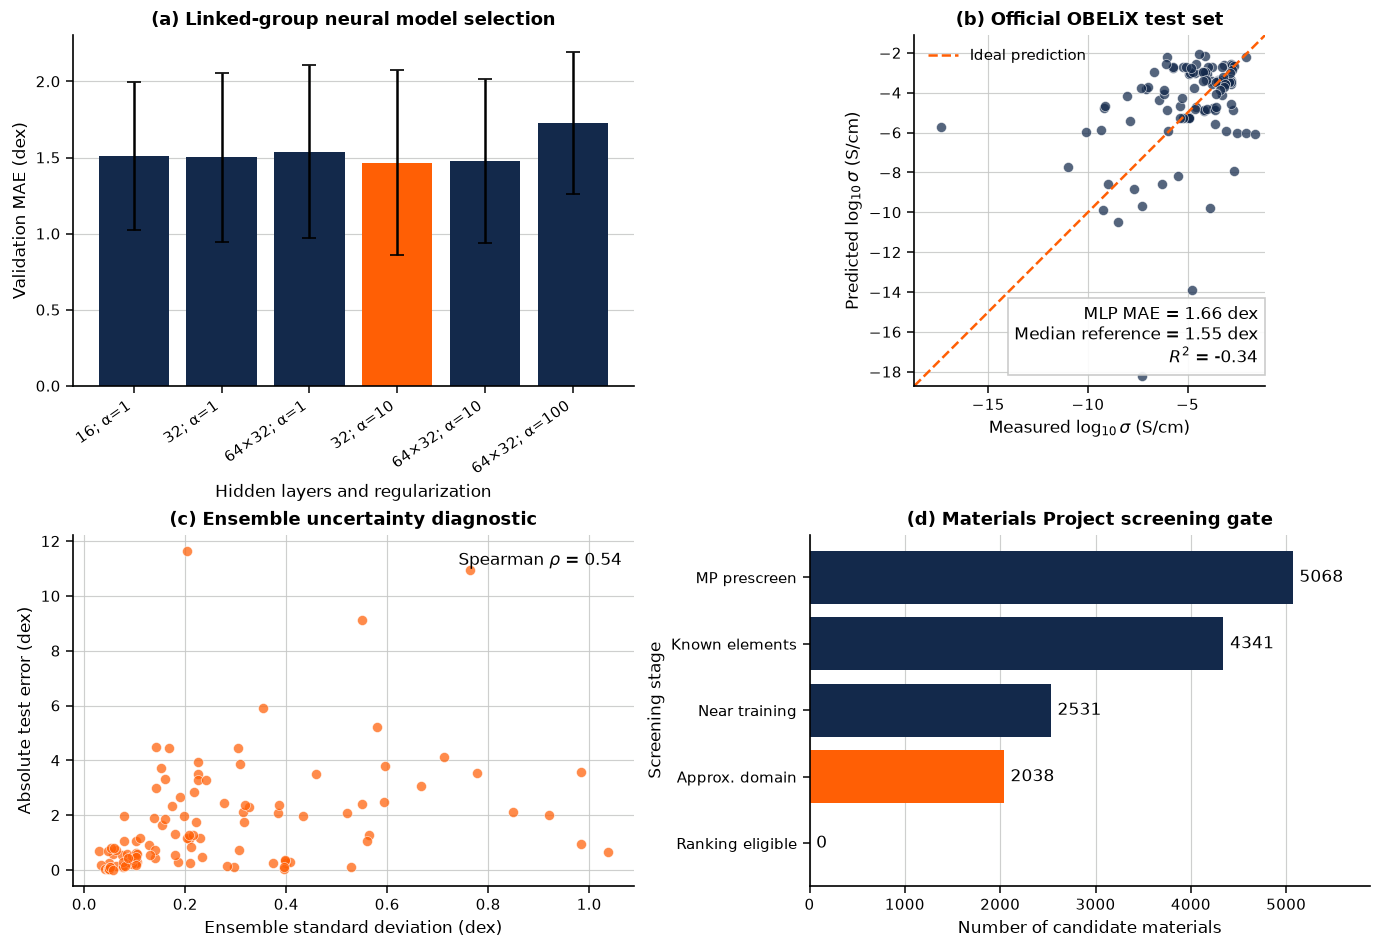

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(11.4, 7.8), constrained_layout=True)

# (a) Grouped CV model selection
cv_plot = mlp_cv_summary.sort_values("config_index")
colors = [ILLINI_ORANGE if selected else ILLINI_BLUE for selected in cv_plot["selected"]]
bars = axes[0, 0].bar(
    np.arange(len(cv_plot)), cv_plot["mean_MAE_dex"],
    yerr=cv_plot["std_MAE_dex"], capsize=4, color=colors,
)
axes[0, 0].set_xticks(np.arange(len(cv_plot)), cv_plot["config"], rotation=35, ha="right")
axes[0, 0].set_title("(a) Linked-group neural model selection")
axes[0, 0].set_ylabel("Validation MAE (dex)")
axes[0, 0].set_xlabel("Hidden layers and regularization")
finish_axis(axes[0, 0], "y")

# (b) Official test-set parity
plot_min = min(y_test.min(), test_prediction.min()) - 0.5
plot_max = max(y_test.max(), test_prediction.max()) + 0.5
axes[0, 1].scatter(y_test, test_prediction, color=ILLINI_BLUE, alpha=0.72,
                   edgecolor="white", linewidth=0.4)
axes[0, 1].plot([plot_min, plot_max], [plot_min, plot_max], color=ILLINI_ORANGE,
                linestyle="--", label="Ideal prediction")
axes[0, 1].set_xlim(plot_min, plot_max)
axes[0, 1].set_ylim(plot_min, plot_max)
axes[0, 1].set_aspect("equal", adjustable="box")
axes[0, 1].set_title("(b) Official OBELiX test set")
axes[0, 1].set_xlabel(r"Measured $\log_{10}\sigma$ (S/cm)")
axes[0, 1].set_ylabel(r"Predicted $\log_{10}\sigma$ (S/cm)")
axes[0, 1].legend(loc="upper left")
axes[0, 1].text(
    0.98, 0.05,
    f"MLP MAE = {mlp_test_mae:.2f} dex\nMedian reference = {median_reference_mae:.2f} dex\n"
    f"$R^2$ = {r2_score(y_test, test_prediction):.2f}",
    transform=axes[0, 1].transAxes, ha="right", va="bottom",
    bbox={"facecolor": "white", "edgecolor": ILLINI_STORM_LIGHT, "alpha": 0.9},
)
finish_axis(axes[0, 1], "both")

# (c) Ensemble uncertainty diagnostic
axes[1, 0].scatter(test_model_std, test_absolute_error, color=ILLINI_ORANGE,
                   alpha=0.72, edgecolor="white", linewidth=0.4)
axes[1, 0].set_title("(c) Ensemble uncertainty diagnostic")
axes[1, 0].set_xlabel("Ensemble standard deviation (dex)")
axes[1, 0].set_ylabel("Absolute test error (dex)")
axes[1, 0].text(
    0.98, 0.95,
    fr"Spearman $\rho$ = {mlp_test_metrics['uncertainty_absolute_error_Spearman']:.2f}",
    transform=axes[1, 0].transAxes, ha="right", va="top",
)
finish_axis(axes[1, 0], "both")

# (d) MP applicability and performance gate
funnel_order = [
    "MP prescreen query",
    "all elements represented in training",
    "near training compositions",
    "approximate composition domain",
    "eligible after model-performance gate",
]
funnel_values = mp_funnel.reindex(funnel_order)
funnel_labels = [
    "MP prescreen", "Known elements", "Near training", "Approx. domain", "Ranking eligible"
]
funnel_colors = [ILLINI_BLUE, ILLINI_BLUE, ILLINI_BLUE, ILLINI_ORANGE, ILLINI_STORM]
bars = axes[1, 1].barh(funnel_labels, funnel_values, color=funnel_colors)
axes[1, 1].bar_label(bars, padding=4)
axes[1, 1].set_xlim(0, max(funnel_values) * 1.16)
axes[1, 1].invert_yaxis()
axes[1, 1].set_title("(d) Materials Project screening gate")
axes[1, 1].set_xlabel("Number of candidate materials")
axes[1, 1].set_ylabel("Screening stage")
finish_axis(axes[1, 1], "x")

save_report_figure(fig, "figure_03_mlp_and_mp_screening_gate.png")
plt.show()


**Figure 3.** Neural-baseline validation and Materials Project consultation. (a) Five-fold linked-group cross-validation selects a strongly regularized 32-unit MLP, with error bars showing fold-to-fold variability. (b) On the untouched official OBELiX test set, the ensemble does not beat the training-median reference and has negative $R^2$. (c) Ensemble spread is evaluated as a relative uncertainty signal but does not substitute for experimental noise. (d) The current Materials Project query yields a broad prescreened candidate pool, which is reduced by composition-domain checks; the final ranking count remains zero because the neural model fails its predefined performance gate.


## 13. Decision and next advancement

The composition-only MLP is now a frozen negative baseline. It demonstrates that element fractions and simple periodic-property summaries are insufficient for reliable transfer to the official OBELiX test set. Consequently, Materials Project candidates are **not** assigned conductivity predictions in this milestone.

The next justified advancement is a pretrained structure representation with restricted fine-tuning:

1. Match the higher-confidence OBELiX CIF subset to Materials Project or openly distributed structures.
2. Extract frozen CHGNet embeddings and train only a small conductivity/uncertainty head.
3. Compare that model against this exact MLP and median reference on common held-out records.
4. Permit MP ranking only if the structure-aware model passes the same performance and applicability-domain gates.

This advances beyond copying prior benchmarks: the project combines literature-derived data discipline with a stricter linked-group validation scheme, explicit uncertainty checks, and a hard safeguard against using an underperforming neural model for materials claims.


## 14. Structure manifest before graph learning

The structure-aware model begins with provenance and validation, not graph training. The official OBELiX release contains 321 public CIF files and distinguishes structures taken from the conductivity publication from **close structural analogues**. We retain that distinction: direct-source CIFs define the primary cohort, while close analogues are reserved for sensitivity analysis.

Each public CIF is checked without using the conductivity value. The audit records file identity, parsing warnings, composition agreement, recovered space group, lattice consistency, and partial occupancy. A 0.02 threshold on the $L_1$ distance between normalized elemental fractions is used only as a conservative review flag; it does not establish crystallographic identity.

This step follows the [official OBELiX release](https://github.com/NRC-Mila/OBELiX), uses [pymatgen symmetry analysis](https://pymatgen.org/pymatgen.symmetry.html), and prepares inputs for the [CHGNet crystal-graph representation](https://doi.org/10.1038/s42256-023-00716-3). The archive is pinned to the same OBELiX revision as the conductivity tables and verified by SHA-256.


In [16]:
import io
import urllib.request
import warnings
import zipfile

from pymatgen.core import Structure
from pymatgen.symmetry.analyzer import SpacegroupAnalyzer

OBELIX_CIF_REVISION = OBELIX_SOURCE_REVISION
OBELIX_CIF_ARCHIVE_URL = (
    "https://raw.githubusercontent.com/NRC-Mila/OBELiX/"
    f"{OBELIX_CIF_REVISION}/data/downloads/all_cifs.zip"
)
OBELIX_CIF_ARCHIVE_SHA256 = "90f54f781fe6c4ba014636046556ec66c3bfa909b617e7258ff50ac3dcfa027c"
OBELIX_CIF_DIR = ROOT / "data/raw/obelix_cifs"
STRUCTURE_MANIFEST_PATH = ROOT / "data/processed/obelix_structure_manifest.csv"
REBUILD_STRUCTURE_MANIFEST = False


def ensure_official_obelix_cifs(force_download=False):
    """Download the pinned public CIF archive only when the local cache is incomplete."""
    existing = sorted(OBELIX_CIF_DIR.glob("*.cif"))
    if len(existing) == 321 and not force_download:
        return existing

    with urllib.request.urlopen(OBELIX_CIF_ARCHIVE_URL, timeout=60) as response:
        payload = response.read()
    observed_hash = sha256(payload).hexdigest()
    if observed_hash != OBELIX_CIF_ARCHIVE_SHA256:
        raise ValueError("OBELiX CIF archive SHA-256 mismatch.")

    OBELIX_CIF_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(io.BytesIO(payload)) as archive:
        cif_members = [name for name in archive.namelist() if name.lower().endswith(".cif")]
        if len(cif_members) != 321:
            raise ValueError(f"Expected 321 CIFs, found {len(cif_members)}.")
        for member in cif_members:
            destination = OBELIX_CIF_DIR / Path(member).name
            destination.write_bytes(archive.read(member))
    return sorted(OBELIX_CIF_DIR.glob("*.cif"))


def fractional_composition_l1(first, second):
    first_fractions = first.fractional_composition.get_el_amt_dict()
    second_fractions = second.fractional_composition.get_el_amt_dict()
    elements = set(first_fractions) | set(second_fractions)
    return float(sum(
        abs(first_fractions.get(element, 0.0) - second_fractions.get(element, 0.0))
        for element in elements
    ))


def build_obelix_structure_manifest(source_table):
    ensure_official_obelix_cifs()
    source_table = source_table.copy()
    source_label = source_table["Ionic conductivity (S cm-1)"].astype("string").str.strip()
    source_numeric = pd.to_numeric(source_label.str.replace("<", "", regex=False), errors="coerce")
    has_exact_label = (~source_label.str.startswith("<", na=False)) & source_numeric.gt(0)
    train_id_set = set(train_ids)
    rows = []

    for source_index, source_row in source_table.iterrows():
        obelix_id = str(source_row["ID"])
        source_composition = parse_composition(source_row["Reduced Composition"])
        cif_path = OBELIX_CIF_DIR / f"{obelix_id}.cif"
        file_present = cif_path.exists()
        close_analogue = str(source_row["close match"]).strip().lower() == "yes"
        cif_status = str(source_row["Cif ID"]).strip().lower()

        if file_present and close_analogue:
            structure_relation = "close_analogue_cif"
        elif file_present:
            structure_relation = "direct_source_cif"
        elif cif_status == "available":
            structure_relation = "external_reference_only"
        else:
            structure_relation = "no_structure"

        row = {
            "record_id": f"OBELIX:{obelix_id}",
            "obelix_id": obelix_id,
            "source_split": "train" if obelix_id in train_id_set else "test",
            "formula": source_row["Reduced Composition"],
            "normalized_formula": source_composition.alphabetical_formula.replace(" ", ""),
            "chemsys": source_composition.chemical_system,
            "has_exact_conductivity_label": bool(has_exact_label.loc[source_index]),
            "source_publication_doi": source_row["DOI"],
            "source_space_group_symbol": source_row["Space group"],
            "source_space_group_number": source_row["Space group #"],
            "source_a_A": source_row["a"],
            "source_b_A": source_row["b"],
            "source_c_A": source_row["c"],
            "source_alpha_deg": source_row["alpha"],
            "source_beta_deg": source_row["beta"],
            "source_gamma_deg": source_row["gamma"],
            "obelix_cif_status": source_row["Cif ID"],
            "structure_relation": structure_relation,
            "structure_reference_doi": (
                source_row["close match DOI"] if close_analogue
                else source_row["DOI"]
            ),
            "icsd_id": source_row["ICSD ID"],
            "cif_relative_path": (
                str(cif_path.relative_to(ROOT)) if file_present else pd.NA
            ),
            "cif_file_present": file_present,
            "cif_revision": OBELIX_CIF_REVISION if file_present else pd.NA,
            "cif_archive_sha256": OBELIX_CIF_ARCHIVE_SHA256 if file_present else pd.NA,
            "cif_file_sha256": file_sha256(cif_path) if file_present else pd.NA,
            "structure_parse_status": "not_available",
            "parse_warning_count": 0,
            "parse_warning_messages": pd.NA,
            "parse_error": pd.NA,
            "cif_formula": pd.NA,
            "cif_reduced_formula": pd.NA,
            "cif_chemsys": pd.NA,
            "cif_n_sites": pd.NA,
            "cif_volume_A3": pd.NA,
            "cif_density_g_cm3": pd.NA,
            "cif_is_ordered": pd.NA,
            "partial_or_mixed_site_count": pd.NA,
            "mixed_species_site_count": pd.NA,
            "vacancy_site_count": pd.NA,
            "min_total_site_occupancy": pd.NA,
            "composition_fraction_l1": pd.NA,
            "same_chemical_system": pd.NA,
            "tight_composition_flag": pd.NA,
            "detected_space_group_number": pd.NA,
            "space_group_matches_source": pd.NA,
            "symmetry_error": pd.NA,
            "max_relative_lattice_length_difference": pd.NA,
            "max_absolute_lattice_angle_difference_deg": pd.NA,
            "metadata_validation_pass": False,
            "review_reason": pd.NA,
            "requires_occupancy_resolution": False,
            "primary_structure_cohort_now": False,
            "structure_model_role": "not_assigned",
            "mp_material_id": pd.NA,
            "mp_match_status": "not_attempted_step_1",
        }

        if file_present:
            try:
                with warnings.catch_warnings(record=True) as caught_warnings:
                    warnings.simplefilter("always")
                    structure = Structure.from_file(cif_path, primitive=False, sort=False)
                row["structure_parse_status"] = "parsed"
                row["parse_warning_count"] = len(caught_warnings)
                if caught_warnings:
                    row["parse_warning_messages"] = " | ".join(sorted({
                        str(warning.message) for warning in caught_warnings
                    }))

                site_occupancies = np.array([
                    float(sum(site.species.values())) for site in structure
                ])
                partial_or_mixed = [not site.is_ordered for site in structure]
                mixed_species = [len(site.species) > 1 for site in structure]
                vacancy_sites = [occupancy < 1.0 - 1e-6 for occupancy in site_occupancies]
                composition_distance = fractional_composition_l1(
                    source_composition, structure.composition
                )
                same_system = source_composition.chemical_system == structure.composition.chemical_system

                row.update({
                    "cif_formula": structure.composition.formula,
                    "cif_reduced_formula": structure.composition.reduced_formula,
                    "cif_chemsys": structure.composition.chemical_system,
                    "cif_n_sites": len(structure),
                    "cif_volume_A3": structure.volume,
                    "cif_density_g_cm3": structure.density,
                    "cif_is_ordered": structure.is_ordered,
                    "partial_or_mixed_site_count": int(sum(partial_or_mixed)),
                    "mixed_species_site_count": int(sum(mixed_species)),
                    "vacancy_site_count": int(sum(vacancy_sites)),
                    "min_total_site_occupancy": float(site_occupancies.min()),
                    "composition_fraction_l1": composition_distance,
                    "same_chemical_system": same_system,
                    "tight_composition_flag": composition_distance <= 0.02,
                    "requires_occupancy_resolution": not structure.is_ordered,
                })

                source_lengths = source_row[["a", "b", "c"]].astype(float).to_numpy()
                source_angles = source_row[["alpha", "beta", "gamma"]].astype(float).to_numpy()
                if np.isfinite(source_lengths).all() and np.all(source_lengths > 0):
                    row["max_relative_lattice_length_difference"] = float(np.max(
                        np.abs(np.array(structure.lattice.abc) - source_lengths) / source_lengths
                    ))
                if np.isfinite(source_angles).all():
                    row["max_absolute_lattice_angle_difference_deg"] = float(np.max(
                        np.abs(np.array(structure.lattice.angles) - source_angles)
                    ))

                try:
                    analyzer = SpacegroupAnalyzer(
                        structure, symprec=0.1, angle_tolerance=5
                    )
                    detected_space_group = analyzer.get_space_group_number()
                    row["detected_space_group_number"] = detected_space_group
                    row["space_group_matches_source"] = bool(
                        detected_space_group == source_row["Space group #"]
                    )
                except Exception as error:
                    row["symmetry_error"] = f"{type(error).__name__}: {error}"

                row["metadata_validation_pass"] = bool(
                    row["same_chemical_system"]
                    and row["tight_composition_flag"]
                    and row["space_group_matches_source"] is True
                )
            except Exception as error:
                row["structure_parse_status"] = "parse_failed"
                row["parse_error"] = f"{type(error).__name__}: {error}"

        review_reasons = []
        if not file_present:
            review_reasons.append("no_local_cif")
        elif row["structure_parse_status"] != "parsed":
            review_reasons.append("parse_failed")
        else:
            if row["same_chemical_system"] is not True:
                review_reasons.append("chemical_system_mismatch")
            if row["tight_composition_flag"] is not True:
                review_reasons.append("composition_difference_gt_0.02")
            if pd.isna(row["detected_space_group_number"]):
                review_reasons.append("symmetry_not_resolved")
            elif row["space_group_matches_source"] is not True:
                review_reasons.append("space_group_mismatch")
        row["review_reason"] = ";".join(review_reasons) if review_reasons else pd.NA

        row["primary_structure_cohort_now"] = bool(
            row["has_exact_conductivity_label"]
            and structure_relation == "direct_source_cif"
            and row["metadata_validation_pass"]
            and row["cif_is_ordered"] is True
        )

        if not row["has_exact_conductivity_label"]:
            row["structure_model_role"] = "not_labeled_for_regression"
        elif structure_relation in {"no_structure", "external_reference_only"}:
            row["structure_model_role"] = "no_local_structure"
        elif not row["metadata_validation_pass"]:
            row["structure_model_role"] = "metadata_manual_review"
        elif structure_relation == "close_analogue_cif":
            row["structure_model_role"] = "analogue_sensitivity_only"
        elif row["requires_occupancy_resolution"]:
            row["structure_model_role"] = "direct_requires_occupancy_resolution"
        else:
            row["structure_model_role"] = "ordered_direct_primary_ready"

        rows.append(row)

    manifest = pd.DataFrame(rows)
    assert len(manifest) == len(source_table)
    assert manifest["record_id"].is_unique
    assert manifest["cif_file_present"].sum() == 321
    assert manifest["structure_parse_status"].eq("parsed").sum() == 321
    return manifest


In [17]:
if STRUCTURE_MANIFEST_PATH.exists() and not REBUILD_STRUCTURE_MANIFEST:
    structure_manifest = pd.read_csv(STRUCTURE_MANIFEST_PATH)
    structure_manifest_source = "cached audited manifest"
else:
    structure_manifest = build_obelix_structure_manifest(obelix)
    structure_manifest.to_csv(STRUCTURE_MANIFEST_PATH, index=False)
    structure_manifest_source = "rebuilt from pinned official CIF archive"

assert len(structure_manifest) == 599
assert structure_manifest["record_id"].is_unique
assert structure_manifest["cif_file_present"].sum() == 321
assert structure_manifest["structure_parse_status"].eq("parsed").sum() == 321
assert not any(
    column in structure_manifest.columns
    for column in [MODEL_TARGET, "conductivity_value", "predicted_log10_sigma_S_cm"]
)

official_cifs = structure_manifest.loc[structure_manifest["cif_file_present"]].copy()
exact_structure_manifest = structure_manifest.loc[
    structure_manifest["has_exact_conductivity_label"]
].copy()

structure_audit_summary = pd.Series({
    "OBELiX records": len(structure_manifest),
    "official public CIFs": int(structure_manifest["cif_file_present"].sum()),
    "successfully parsed CIFs": int(official_cifs["structure_parse_status"].eq("parsed").sum()),
    "direct-source CIFs": int(official_cifs["structure_relation"].eq("direct_source_cif").sum()),
    "close-analogue CIFs": int(official_cifs["structure_relation"].eq("close_analogue_cif").sum()),
    "CIFs passing metadata audit": int(official_cifs["metadata_validation_pass"].sum()),
    "CIFs requiring occupancy resolution": int(official_cifs["requires_occupancy_resolution"].sum()),
    "exact-label direct ordered primary cohort": int(structure_manifest["primary_structure_cohort_now"].sum()),
}, name="count")

display(structure_audit_summary.to_frame())
display(
    exact_structure_manifest["structure_model_role"]
    .value_counts()
    .rename_axis("model role")
    .to_frame("records")
)
print("Manifest source:", structure_manifest_source)
print("Saved structure manifest:", STRUCTURE_MANIFEST_PATH)


,count
OBELiX records,599
official public CIFs,321
successfully parsed CIFs,321
direct-source CIFs,260
close-analogue CIFs,61
CIFs passing metadata audit,288
CIFs requiring occupancy resolution,249
exact-label direct ordered primary cohort,41


,records
model role,
no_local_structure,277
direct_requires_occupancy_resolution,161
analogue_sensitivity_only,54
ordered_direct_primary_ready,41
metadata_manual_review,29


Manifest source: cached audited manifest
Saved structure manifest: /Users/zhy/Downloads/battery_ml_starter/data/processed/obelix_structure_manifest.csv


Saved figure: /Users/zhy/Downloads/battery_ml_starter/figures/figure_04_obelix_structure_manifest.png


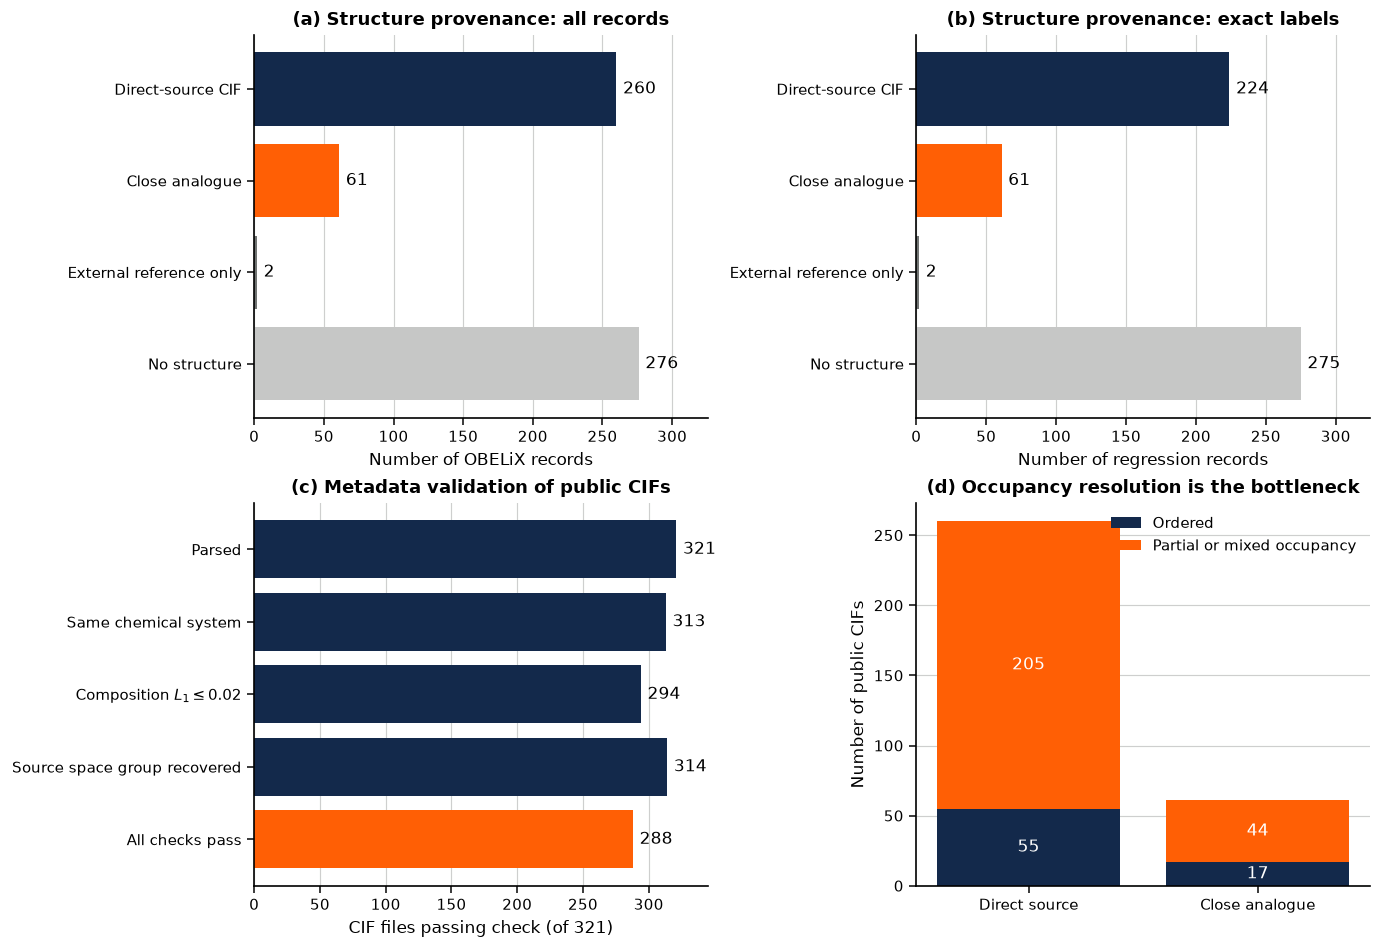

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(11.4, 7.8), constrained_layout=True)

relation_order = [
    "direct_source_cif", "close_analogue_cif", "external_reference_only", "no_structure"
]
relation_labels = ["Direct-source CIF", "Close analogue", "External reference only", "No structure"]
relation_colors = [ILLINI_BLUE, ILLINI_ORANGE, ILLINI_STORM, ILLINI_STORM_LIGHT]

# (a) Coverage over all 599 records
all_coverage = structure_manifest["structure_relation"].value_counts().reindex(
    relation_order, fill_value=0
)
bars = axes[0, 0].barh(relation_labels, all_coverage, color=relation_colors)
axes[0, 0].bar_label(bars, padding=4)
axes[0, 0].set_xlim(0, max(all_coverage) * 1.18)
axes[0, 0].invert_yaxis()
axes[0, 0].set_title("(a) Structure provenance: all records")
axes[0, 0].set_xlabel("Number of OBELiX records")
finish_axis(axes[0, 0], "x")

# (b) Coverage for exact conductivity labels
exact_coverage = exact_structure_manifest["structure_relation"].value_counts().reindex(
    relation_order, fill_value=0
)
bars = axes[0, 1].barh(relation_labels, exact_coverage, color=relation_colors)
axes[0, 1].bar_label(bars, padding=4)
axes[0, 1].set_xlim(0, max(exact_coverage) * 1.18)
axes[0, 1].invert_yaxis()
axes[0, 1].set_title("(b) Structure provenance: exact labels")
axes[0, 1].set_xlabel("Number of regression records")
finish_axis(axes[0, 1], "x")

# (c) Independent checks on the 321 public CIFs
validation_counts = pd.Series({
    "Parsed": official_cifs["structure_parse_status"].eq("parsed").sum(),
    "Same chemical system": official_cifs["same_chemical_system"].eq(True).sum(),
    r"Composition $L_1\leq0.02$": official_cifs["tight_composition_flag"].eq(True).sum(),
    "Source space group recovered": official_cifs["space_group_matches_source"].eq(True).sum(),
    "All checks pass": official_cifs["metadata_validation_pass"].sum(),
})
validation_colors = [ILLINI_BLUE] * 4 + [ILLINI_ORANGE]
bars = axes[1, 0].barh(validation_counts.index, validation_counts, color=validation_colors)
axes[1, 0].bar_label(bars, padding=4)
axes[1, 0].set_xlim(0, 345)
axes[1, 0].invert_yaxis()
axes[1, 0].set_title("(c) Metadata validation of public CIFs")
axes[1, 0].set_xlabel("CIF files passing check (of 321)")
finish_axis(axes[1, 0], "x")

# (d) Disorder burden by provenance
occupancy_table = pd.crosstab(
    official_cifs["structure_relation"],
    official_cifs["requires_occupancy_resolution"],
).reindex(["direct_source_cif", "close_analogue_cif"], fill_value=0)
ordered_counts = occupancy_table.get(False, pd.Series(0, index=occupancy_table.index))
disordered_counts = occupancy_table.get(True, pd.Series(0, index=occupancy_table.index))
x_positions = np.arange(2)
axes[1, 1].bar(x_positions, ordered_counts, color=ILLINI_BLUE, label="Ordered")
axes[1, 1].bar(
    x_positions, disordered_counts, bottom=ordered_counts,
    color=ILLINI_ORANGE, label="Partial or mixed occupancy",
)
for index, (ordered, disordered) in enumerate(zip(ordered_counts, disordered_counts)):
    axes[1, 1].text(index, ordered / 2, str(int(ordered)), ha="center", va="center", color="white")
    axes[1, 1].text(
        index, ordered + disordered / 2, str(int(disordered)),
        ha="center", va="center", color="white",
    )
axes[1, 1].set_xticks(x_positions, ["Direct source", "Close analogue"])
axes[1, 1].set_title("(d) Occupancy resolution is the bottleneck")
axes[1, 1].set_ylabel("Number of public CIFs")
axes[1, 1].legend(loc="upper right")
finish_axis(axes[1, 1], "y")

save_report_figure(fig, "figure_04_obelix_structure_manifest.png")
plt.show()


**Figure 4.** Structure provenance and validation before graph learning. Direct-source and close-analogue structures remain separate for both the complete dataset and the exact-label regression subset. All 321 public CIFs parse, while independent composition and symmetry checks identify records requiring manual review. Partial or mixed occupancy is the dominant preprocessing issue and must be resolved transparently before CHGNet embedding.

### Step-1 decision

The structure inventory is now frozen, but graph learning has not started. Only the small set marked `ordered_direct_primary_ready` can enter CHGNet unchanged. Direct-source structures with partial occupancy require a documented representation policy, and close analogues will not be mixed into the primary training cohort.

The next step is Materials Project structure matching. Candidate MP structures will first be restricted by chemical system, composition, and space group, then compared using pymatgen `StructureMatcher` when both structures are available. Matching will remain blind to conductivity, and every accepted MP identifier will retain its matching diagnostics and database version.


## 15. Materials Project structure matching: screened first pass

The existing Materials Project candidate cache is a **screened subset** (Li-containing, nonmetallic, band gap at least 1 eV, and energy above hull at most 0.05 eV/atom). Matching against this cache is useful for planning an inference cohort, but a missing match here does not mean Materials Project lacks the material.

We first compare chemical system, source space-group number, and elemental-fraction distance $d_1=\sum_e|x_e^{\mathrm{OBELiX}}-x_e^{\mathrm{MP}}|\leq0.02$. We then fetch only shortlisted MP structures and compare atomic geometry with pymatgen `StructureMatcher` (`ltol=0.2`, `stol=0.3`, `angle_tol=5°`, primitive-cell and volume scaling enabled). These tolerances define a **candidate structural analogue**, not proof that the experimental and relaxed computational phases are identical. The public OBELiX CIF may have partial occupancies; an ordered MP representation of such a record remains a proxy requiring separate sensitivity analysis.

The Materials Project [summary endpoint](https://docs.materialsproject.org/downloading-data/using-the-api/querying-data) supplies the structures. [pymatgen structure matching](https://pymatgen.org/pymatgen.analysis.html) implements geometric comparison. Conductivity is excluded from all matching decisions.


In [19]:
import json
from pymatgen.analysis.structure_matcher import StructureMatcher

MP_MATCH_STRUCTURES_PATH = ROOT / "data/raw/mp_obelix_match_structures.json"
MP_MATCH_PAIRS_PATH = ROOT / "data/processed/obelix_mp_structure_match_pairs.csv"
MP_MATCH_SUMMARY_PATH = ROOT / "data/processed/obelix_mp_structure_match_summary.csv"
REFRESH_MP_MATCH_STRUCTURES = False


def elemental_fraction_distance(formula_a, formula_b):
    return fractional_composition_l1(
        parse_composition(formula_a), parse_composition(formula_b)
    )


screened_mp = mp_candidates.copy()
screened_mp["space_group_number"] = pd.to_numeric(
    screened_mp["space_group_number"], errors="coerce"
)
matchable_obelix = structure_manifest.loc[
    structure_manifest["has_exact_conductivity_label"]
    & structure_manifest["cif_file_present"]
    & structure_manifest["metadata_validation_pass"]
].copy()

match_pairs = matchable_obelix[[
    "record_id", "obelix_id", "formula", "chemsys", "source_split",
    "structure_relation", "source_space_group_number", "cif_relative_path",
    "cif_file_sha256", "cif_is_ordered", "requires_occupancy_resolution",
]].merge(
    screened_mp[[
        "material_id", "formula_pretty", "chemsys", "space_group_number",
        "mp_database_version", "energy_above_hull_eV_atom", "band_gap_eV",
    ]], on="chemsys", how="inner",
)
match_pairs = match_pairs.loc[
    match_pairs["source_space_group_number"].eq(match_pairs["space_group_number"])
].copy()
match_pairs["composition_fraction_l1"] = [
    elemental_fraction_distance(first, second)
    for first, second in zip(match_pairs["formula"], match_pairs["formula_pretty"])
]
match_pairs = match_pairs.loc[
    match_pairs["composition_fraction_l1"].le(0.02)
].sort_values(
    ["record_id", "composition_fraction_l1", "material_id"]
).reset_index(drop=True)

assert match_pairs[["record_id", "material_id"]].duplicated().sum() == 0
print(
    f"Shortlist: {len(match_pairs)} pairs; "
    f"{match_pairs['record_id'].nunique()} OBELiX records; "
    f"{match_pairs['material_id'].nunique()} MP material IDs"
)


Shortlist: 57 pairs; 54 OBELiX records; 51 MP material IDs


In [20]:
def load_mp_match_structures(material_ids, force_refresh=False):
    """Cache only structures needed for the screened first-pass match."""
    wanted = sorted(set(material_ids))
    cached = {}
    if MP_MATCH_STRUCTURES_PATH.exists() and not force_refresh:
        cached = json.loads(MP_MATCH_STRUCTURES_PATH.read_text())
    missing = sorted(set(wanted) - set(cached.get("structures", {})))
    if missing:
        api_key = os.getenv("MP_API_KEY")
        if not api_key:
            raise RuntimeError("Set MP_API_KEY in .env to retrieve missing MP structures.")
        from mp_api.client import MPRester

        structures = dict(cached.get("structures", {}))
        with MPRester(api_key, use_document_model=False, mute_progress_bars=True) as mpr:
            db_version = mpr.db_version
            for start in range(0, len(missing), 25):
                docs = mpr.materials.summary.search(
                    material_ids=missing[start:start + 25],
                    fields=["material_id", "structure"], all_fields=False,
                    chunk_size=100,
                )
                for doc in docs:
                    structures[str(doc["material_id"])] = doc["structure"]
        cached = {
            "source": "Materials Project materials.summary.search",
            "database_version": db_version,
            "requested_material_ids": wanted,
            "structures": structures,
        }
        MP_MATCH_STRUCTURES_PATH.parent.mkdir(parents=True, exist_ok=True)
        MP_MATCH_STRUCTURES_PATH.write_text(json.dumps(cached, sort_keys=True))
    return cached


mp_structure_cache = load_mp_match_structures(
    match_pairs["material_id"], REFRESH_MP_MATCH_STRUCTURES
)
assert set(match_pairs["material_id"]).issubset(mp_structure_cache["structures"])
print("MP structure database version:", mp_structure_cache["database_version"])
print("Cached structure count:", len(mp_structure_cache["structures"]))


MP structure database version:

 2026.09.28
Cached structure count: 51


In [21]:
matcher = StructureMatcher(
    ltol=0.2, stol=0.3, angle_tol=5,
    primitive_cell=True, scale=True, attempt_supercell=False,
)
mp_structures = {
    material_id: Structure.from_dict(structure_dict)
    for material_id, structure_dict in mp_structure_cache["structures"].items()
}
obelix_structures = {
    obelix_id: Structure.from_file(
        ROOT / path, primitive=False, sort=False
    )
    for obelix_id, path in structure_manifest.loc[
        structure_manifest["obelix_id"].isin(match_pairs["obelix_id"]),
        ["obelix_id", "cif_relative_path"],
    ].drop_duplicates("obelix_id").itertuples(index=False, name=None)
}

geometry_rows = []
for pair in match_pairs.itertuples(index=False):
    source = obelix_structures[pair.obelix_id]
    target = mp_structures[pair.material_id]
    result = {
        "record_id": pair.record_id,
        "material_id": pair.material_id,
        "mp_structure_is_ordered": target.is_ordered,
        "mp_structure_n_sites": len(target),
        "mp_structure_volume_A3": target.volume,
        "mp_structure_composition_l1": fractional_composition_l1(
            parse_composition(pair.formula), target.composition
        ),
        "structure_matcher_fit": False,
        "matcher_error": pd.NA,
    }
    try:
        result["structure_matcher_fit"] = bool(matcher.fit(source, target))
    except Exception as error:
        result["matcher_error"] = f"{type(error).__name__}: {error}"
    geometry_rows.append(result)

geometry = pd.DataFrame(geometry_rows)
match_pairs = match_pairs.merge(
    geometry, on=["record_id", "material_id"], validate="one_to_one"
)
match_pairs["match_decision"] = np.select(
    [
        match_pairs["matcher_error"].notna(),
        ~match_pairs["structure_matcher_fit"],
        ~match_pairs["mp_structure_is_ordered"],
        match_pairs["requires_occupancy_resolution"],
        match_pairs["structure_relation"].eq("close_analogue_cif"),
    ],
    [
        "geometry_error", "geometry_rejected", "mp_structure_disordered",
        "ordered_mp_proxy_requires_occupancy_study",
        "close_analogue_sensitivity_only",
    ],
    default="ordered_direct_geometric_match",
)
match_pairs["accepted_for_primary_structure_cohort"] = match_pairs[
    "match_decision"
].eq("ordered_direct_geometric_match")
match_pairs.to_csv(MP_MATCH_PAIRS_PATH, index=False)

best_match = match_pairs.sort_values(
    ["record_id", "accepted_for_primary_structure_cohort",
     "structure_matcher_fit", "composition_fraction_l1", "material_id"],
    ascending=[True, False, False, True, True],
).drop_duplicates("record_id")
match_summary = structure_manifest[[
    "record_id", "source_split", "formula", "structure_relation",
    "has_exact_conductivity_label", "cif_file_present",
    "metadata_validation_pass", "requires_occupancy_resolution",
]].merge(
    best_match[[
        "record_id", "material_id", "composition_fraction_l1",
        "structure_matcher_fit", "mp_structure_is_ordered", "match_decision",
        "accepted_for_primary_structure_cohort", "mp_database_version",
    ]], on="record_id", how="left", validate="one_to_one",
)
match_summary["screened_mp_match_status"] = np.select(
    [
        ~match_summary["has_exact_conductivity_label"],
        ~match_summary["cif_file_present"],
        ~match_summary["metadata_validation_pass"],
        match_summary["material_id"].notna(),
    ],
    ["no_exact_label", "no_public_cif", "cif_metadata_review", "candidate_evaluated"],
    default="no_shortlisted_screened_mp_candidate",
)
match_summary.to_csv(MP_MATCH_SUMMARY_PATH, index=False)

assert len(match_summary) == 599
assert match_summary["record_id"].is_unique
assert not any(col in match_pairs for col in [MODEL_TARGET, "conductivity_value"])
display(match_pairs["match_decision"].value_counts().to_frame("pairs"))
print("Primary geometric matches:", int(match_pairs["accepted_for_primary_structure_cohort"].sum()))
print("Matched OBELiX records:", int(match_pairs.loc[
    match_pairs["structure_matcher_fit"], "record_id"
].nunique()))


,pairs
match_decision,
ordered_direct_geometric_match,31
geometry_rejected,15
close_analogue_sensitivity_only,11


Primary geometric matches: 31
Matched OBELiX records: 42


Saved figure: /Users/zhy/Downloads/battery_ml_starter/figures/figure_05_obelix_mp_structure_matching.png


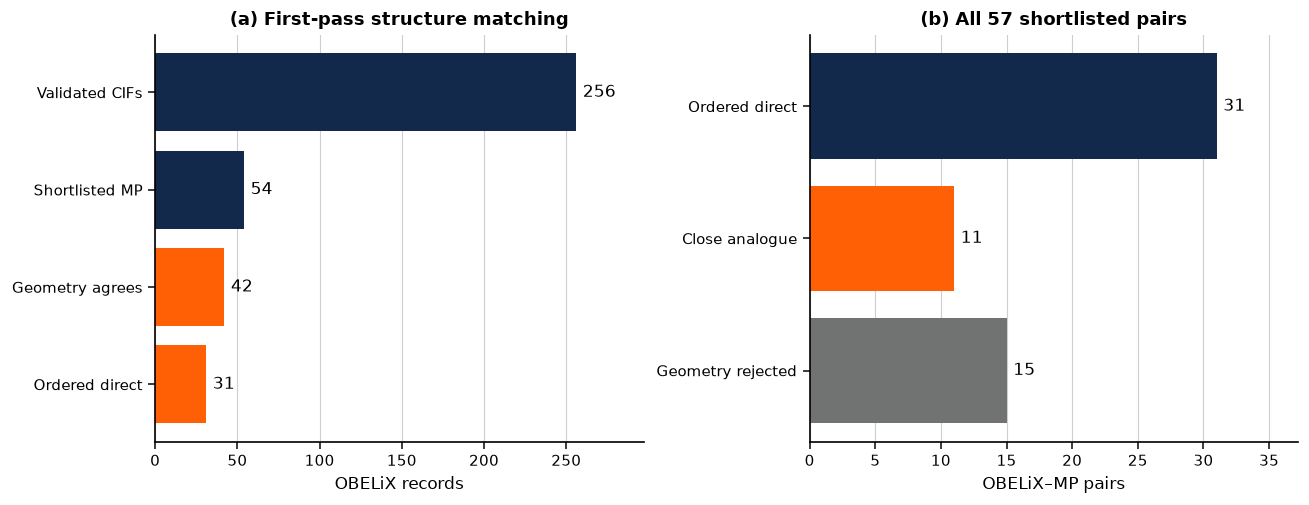

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(10.8, 4.1), constrained_layout=True)

screen_counts = pd.Series({
    "Exact-label CIFs passing audit": len(matchable_obelix),
    "Shortlisted in screened MP pool": match_pairs["record_id"].nunique(),
    "Geometric match": match_pairs.loc[
        match_pairs["structure_matcher_fit"], "record_id"
    ].nunique(),
    "Ordered direct match": match_pairs.loc[
        match_pairs["accepted_for_primary_structure_cohort"], "record_id"
    ].nunique(),
})
bars = axes[0].barh(
    ["Validated CIFs", "Shortlisted MP", "Geometry agrees", "Ordered direct"],
    screen_counts, color=[ILLINI_BLUE, ILLINI_BLUE, ILLINI_ORANGE, ILLINI_ORANGE],
)
axes[0].bar_label(bars, padding=4)
axes[0].invert_yaxis()
axes[0].set_xlim(0, max(screen_counts) * 1.16)
axes[0].set_title("(a) First-pass structure matching")
axes[0].set_xlabel("OBELiX records")
finish_axis(axes[0], "x")

outcome_counts = match_pairs["match_decision"].value_counts().reindex([
    "ordered_direct_geometric_match", "close_analogue_sensitivity_only",
    "geometry_rejected",
], fill_value=0)
bars = axes[1].barh(
    ["Ordered direct", "Close analogue", "Geometry rejected"],
    outcome_counts, color=[ILLINI_BLUE, ILLINI_ORANGE, ILLINI_STORM],
)
axes[1].bar_label(bars, padding=4)
axes[1].invert_yaxis()
axes[1].set_xlim(0, max(outcome_counts) * 1.20)
axes[1].set_title("(b) All 57 shortlisted pairs")
axes[1].set_xlabel("OBELiX–MP pairs")
finish_axis(axes[1], "x")

save_report_figure(fig, "figure_05_obelix_mp_structure_matching.png")
plt.show()


**Figure 5.** A first pass against the existing screened Materials Project pool. Of 256 exact-label OBELiX records with validated public CIFs, 54 have at least one shortlisted MP entry. Geometric comparison agrees for 42 record–MP pairs: 31 ordered direct-source pairs and 11 close-analogue pairs. The other 15 pairs fail the geometry test. These counts reflect the screened pool and the stated matching tolerances.


### Step-2 decision

The pair table records every shortlisted structure and its geometry outcome; the record summary also includes OBELiX entries with no screened MP candidate. A failed or absent match in this **screened subset** is not evidence that no MP structure exists. Before graph learning, we will compare any accepted ordered direct matches with the original CIFs and document how partial occupancies are represented. We will then evaluate frozen CHGNet embeddings against the existing median and composition MLP baselines on identical records and splits.


## 16. Wider Materials Project search

The previous match table covered only the 5,068 compounds that passed the project's screening criteria. Here we query the [Materials Project summary API](https://docs.materialsproject.org/downloading-data/using-the-api/querying-data) by the formulas of all 256 exact-label OBELiX records with validated public CIFs, without band-gap or stability filters. This is a broader **formula-based search**, although it can still miss materials represented by different formulas, occupancies, or historical IDs. We retain every returned MP phase in an audit table, then compare only pairs with the same chemical system, space-group number, and elemental-fraction distance at most 0.02. The geometry comparison uses the same `StructureMatcher` tolerances as Section 15. Conductivity values do not enter the query or matching decision.


In [23]:
MP_WIDE_METADATA_PATH = ROOT / "data/processed/mp_obelix_formula_search_metadata.csv"
MP_WIDE_PAIRS_PATH = ROOT / "data/processed/obelix_mp_wide_match_pairs.csv"
MP_WIDE_SUMMARY_PATH = ROOT / "data/processed/obelix_mp_wide_match_summary.csv"
MP_WIDE_STRUCTURES_PATH = ROOT / "data/raw/mp_obelix_wide_structures.json"
REFRESH_MP_WIDE_SEARCH = False

wide_source = structure_manifest.loc[
    structure_manifest["has_exact_conductivity_label"]
    & structure_manifest["cif_file_present"]
    & structure_manifest["metadata_validation_pass"]
].copy()
wide_source["query_formula"] = wide_source["formula"].map(
    lambda f: parse_composition(f).reduced_formula
)
query_formulas = sorted(wide_source["query_formula"].unique())


def load_wide_mp_metadata(force_refresh=False):
    if MP_WIDE_METADATA_PATH.exists() and not force_refresh:
        return pd.read_csv(MP_WIDE_METADATA_PATH)
    api_key = os.getenv("MP_API_KEY")
    if not api_key:
        raise RuntimeError("MP_API_KEY is required to refresh the wider formula query.")
    from mp_api.client import MPRester

    docs = []
    with MPRester(api_key, use_document_model=False, mute_progress_bars=True) as mpr:
        db_version = mpr.db_version
        for start in range(0, len(query_formulas), 25):
            docs.extend(mpr.materials.summary.search(
                formula=query_formulas[start:start + 25],
                fields=["material_id", "formula_pretty", "chemsys", "symmetry",
                        "band_gap", "energy_above_hull", "is_metal", "deprecated"],
                all_fields=False, chunk_size=1000,
            ))
    rows = []
    for doc in docs:
        symmetry = doc.get("symmetry") or {}
        rows.append({
            "material_id": str(doc["material_id"]),
            "formula_pretty": doc["formula_pretty"],
            "chemsys": doc["chemsys"],
            "space_group_number": symmetry.get("number"),
            "band_gap_eV": doc.get("band_gap"),
            "energy_above_hull_eV_atom": doc.get("energy_above_hull"),
            "is_metal": doc.get("is_metal"),
            "deprecated": doc.get("deprecated"),
            "mp_database_version": db_version,
        })
    frame = pd.DataFrame(rows).drop_duplicates("material_id")
    frame.sort_values("material_id").to_csv(MP_WIDE_METADATA_PATH,index=False)
    return frame


wide_mp = load_wide_mp_metadata(REFRESH_MP_WIDE_SEARCH)
wide_pairs = wide_source[[
    "record_id", "obelix_id", "formula", "chemsys", "source_split",
    "query_formula", "source_space_group_number", "structure_relation",
    "cif_relative_path", "cif_is_ordered", "requires_occupancy_resolution",
]].merge(wide_mp,on="chemsys",validate="many_to_many")
wide_pairs = wide_pairs.loc[
    wide_pairs["source_space_group_number"].eq(wide_pairs["space_group_number"])
].copy()
wide_pairs["composition_fraction_l1"] = [
    elemental_fraction_distance(a,b)
    for a,b in zip(wide_pairs["formula"],wide_pairs["formula_pretty"])
]
wide_pairs = wide_pairs.loc[
    wide_pairs["composition_fraction_l1"].le(0.02)
].sort_values(["record_id","composition_fraction_l1","material_id"]).reset_index(drop=True)
assert not wide_pairs[["record_id","material_id"]].duplicated().any()
print("Queried formulas:",len(query_formulas))
print("MP phases returned:",len(wide_mp))
print("Plausible structural pairs:",len(wide_pairs),"for",wide_pairs.record_id.nunique(),"OBELiX records")


Queried formulas: 225
MP phases returned: 158
Plausible structural pairs: 76 for 71 OBELiX records


In [24]:
def load_wide_mp_structures(material_ids,force_refresh=False):
    wanted=sorted(set(material_ids))
    cache={}
    if MP_WIDE_STRUCTURES_PATH.exists() and not force_refresh:
        cache=json.loads(MP_WIDE_STRUCTURES_PATH.read_text())
    structures=dict(cache.get("structures",{}))
    # Reuse already audited structures from the first-pass search.
    structures.update({
        material_id: structure_dict
        for material_id,structure_dict in mp_structure_cache["structures"].items()
        if material_id in wanted
    })
    missing=sorted(set(wanted)-set(structures))
    if missing:
        api_key=os.getenv("MP_API_KEY")
        if not api_key:
            raise RuntimeError("MP_API_KEY is required to fetch missing MP structures.")
        from mp_api.client import MPRester
        with MPRester(api_key,use_document_model=False,mute_progress_bars=True) as mpr:
            db_version=mpr.db_version
            for start in range(0,len(missing),25):
                docs=mpr.materials.summary.search(
                    material_ids=missing[start:start+25],
                    fields=["material_id","structure"],all_fields=False,chunk_size=100,
                )
                for doc in docs:
                    structures[str(doc["material_id"])]=doc["structure"]
        cache={"database_version":db_version,"structures":structures}
        MP_WIDE_STRUCTURES_PATH.write_text(json.dumps(cache,sort_keys=True))
    return structures


wide_structure_dicts=load_wide_mp_structures(wide_pairs.material_id,REFRESH_MP_WIDE_SEARCH)
assert set(wide_pairs.material_id).issubset(wide_structure_dicts)
wide_mp_structures={material_id:Structure.from_dict(value)
                    for material_id,value in wide_structure_dicts.items()}
wide_source_structures={rid:Structure.from_file(ROOT/path,primitive=False,sort=False)
    for rid,path in wide_pairs[["obelix_id","cif_relative_path"]]
        .drop_duplicates("obelix_id").itertuples(index=False,name=None)}

wide_results=[]
for pair in wide_pairs.itertuples(index=False):
    source=wide_source_structures[pair.obelix_id]
    target=wide_mp_structures[pair.material_id]
    result={"record_id":pair.record_id,"material_id":pair.material_id,
            "mp_structure_is_ordered":target.is_ordered,
            "structure_matcher_fit":False,"matcher_error":pd.NA}
    try:
        result["structure_matcher_fit"]=bool(matcher.fit(source,target))
    except Exception as error:
        result["matcher_error"]=f"{type(error).__name__}: {error}"
    wide_results.append(result)
wide_pairs=wide_pairs.merge(pd.DataFrame(wide_results),on=["record_id","material_id"],validate="one_to_one")
wide_pairs["match_decision"]=np.select([
    wide_pairs["matcher_error"].notna(),
    ~wide_pairs["structure_matcher_fit"],
    ~wide_pairs["mp_structure_is_ordered"],
    wide_pairs["requires_occupancy_resolution"],
    wide_pairs["structure_relation"].eq("close_analogue_cif"),
], ["geometry_error","geometry_rejected","mp_structure_disordered",
    "ordered_mp_proxy_requires_occupancy_study","close_analogue_sensitivity_only"],
    default="ordered_direct_geometric_match")
wide_pairs["accepted_for_primary_structure_cohort"]=wide_pairs.match_decision.eq(
    "ordered_direct_geometric_match")
wide_pairs.to_csv(MP_WIDE_PAIRS_PATH,index=False)

best=wide_pairs.sort_values(
    ["record_id","accepted_for_primary_structure_cohort","structure_matcher_fit",
     "composition_fraction_l1","material_id"],
    ascending=[True,False,False,True,True]
).drop_duplicates("record_id")
wide_summary=structure_manifest[["record_id","source_split","formula",
    "structure_relation","has_exact_conductivity_label","cif_file_present",
    "metadata_validation_pass","requires_occupancy_resolution"]].merge(
    best[["record_id","material_id","composition_fraction_l1",
          "structure_matcher_fit","match_decision",
          "accepted_for_primary_structure_cohort"]],
    on="record_id",how="left",validate="one_to_one")
wide_summary["search_status"]=np.select([
    ~wide_summary.has_exact_conductivity_label,
    ~wide_summary.cif_file_present,
    ~wide_summary.metadata_validation_pass,
    wide_summary.material_id.notna(),
],["no_exact_label","no_public_cif","cif_metadata_review","pair_evaluated"],
 default="no_shortlisted_formula_match")
wide_summary.to_csv(MP_WIDE_SUMMARY_PATH,index=False)

prior=set(match_pairs.loc[match_pairs.accepted_for_primary_structure_cohort,"record_id"])
current=set(wide_pairs.loc[wide_pairs.accepted_for_primary_structure_cohort,"record_id"])
assert prior.issubset(current),"Wider search should retain first-pass primary matches."
print("Ordered direct geometric matches:",len(current),"(additional",len(current-prior),")")
print("Geometric matches including analogues:",wide_pairs.loc[
    wide_pairs.structure_matcher_fit,"record_id"].nunique())
display(wide_pairs.match_decision.value_counts().to_frame("pairs"))


/Users/zhy/Downloads/battery_ml_starter/.venv/lib/python3.12/site-packages/pymatgen/core/structure.py:3172: UserWarning: Issues encountered while parsing CIF: 4 fractional coordinates rounded to ideal values to avoid issues with finite precision.
  struct = parser.parse_structures(primitive=primitive)[0]
/Users/zhy/Downloads/battery_ml_starter/.venv/lib/python3.12/site-packages/pymatgen/core/structure.py:3172: UserWarning: Issues encountered while parsing CIF: 2 fractional coordinates rounded to ideal values to avoid issues with finite precision.
  struct = parser.parse_structures(primitive=primitive)[0]


Ordered direct geometric matches: 35 (additional 4 )
Geometric matches including analogues: 49


,pairs
match_decision,
ordered_direct_geometric_match,35
geometry_rejected,27
close_analogue_sensitivity_only,14


## 17. Partial-occupancy representation sensitivity

CHGNet's crystal graph expects a definite atomic species at each retained site. The [OBELiX reference implementation](https://github.com/NRC-Mila/OBELiX/blob/main/obelix/utils.py) rounds site occupancies to create ordered structures. We quantify how sensitive the resulting graph input is to that choice. For each audited exact-label direct-source CIF with disorder, two **diagnostic** policies keep the most occupied species at a site when its occupancy is at least 0.50 or 0.70, and remove the site otherwise. These are proxies, not physically validated vacancy configurations. We record changes in site count, lithium count, and normalized composition. A material whose representation changes between policies requires a more careful ordering or an explicitly disorder-aware model before training.


In [25]:
OCCUPANCY_AUDIT_PATH=ROOT/"data/processed/obelix_occupancy_sensitivity.csv"


def resolve_occupancy_by_threshold(structure,threshold):
    resolved=structure.copy()
    remove=[]
    changed=0
    for index,site in enumerate(resolved):
        if site.is_ordered:
            continue
        changed+=1
        ranked=sorted(site.species.items(),key=lambda item:(-float(item[1]),str(item[0])))
        specie,occupancy=ranked[0]
        if float(occupancy)>=threshold:
            resolved.replace(index,specie)
        else:
            remove.append(index)
    if remove:
        resolved.remove_sites(remove)
    return resolved,changed,len(remove)


disordered_direct=structure_manifest.loc[
    structure_manifest.has_exact_conductivity_label
    & structure_manifest.metadata_validation_pass
    & structure_manifest.structure_relation.eq("direct_source_cif")
    & structure_manifest.requires_occupancy_resolution
].copy()
occupancy_rows=[]
for row in disordered_direct.itertuples(index=False):
    original=Structure.from_file(ROOT/row.cif_relative_path,primitive=False,sort=False)
    variants={}
    for threshold in (0.50,0.70):
        variant,changed,removed=resolve_occupancy_by_threshold(original,threshold)
        variants[threshold]=variant
        original_li=float(original.composition.get("Li",0))
        variant_li=float(variant.composition.get("Li",0))
        occupancy_rows.append({
            "record_id":row.record_id,"source_split":row.source_split,
            "formula":row.formula,"policy_threshold":threshold,
            "original_n_sites":len(original),"partial_site_count":changed,
            "sites_removed":removed,"resolved_n_sites":len(variant),
            "original_li_atoms_per_cell":original_li,
            "resolved_li_atoms_per_cell":variant_li,
            "li_atoms_changed":variant_li-original_li,
            "fractional_composition_l1":fractional_composition_l1(
                original.composition,variant.composition) if len(variant) else np.nan,
            "resolved_is_ordered":variant.is_ordered,
            "resolved_has_li":variant_li>0,
        })
    # Compare the graph-level atom list and overall composition across policies.
    low,high=variants[0.50],variants[0.70]
    policy_changed=(len(low)!=len(high) or
        low.composition!=high.composition)
    occupancy_rows[-2]["policy_changes_representation"]=policy_changed
    occupancy_rows[-1]["policy_changes_representation"]=policy_changed

occupancy_audit=pd.DataFrame(occupancy_rows)
occupancy_audit.to_csv(OCCUPANCY_AUDIT_PATH,index=False)
assert len(occupancy_audit)==2*len(disordered_direct)
print("Audited disordered direct-source records:",len(disordered_direct))
print("Policy-sensitive records:",int(occupancy_audit.loc[
    occupancy_audit.policy_threshold.eq(0.50),"policy_changes_representation"].sum()))
display(occupancy_audit.groupby("policy_threshold").agg(
    median_composition_l1=("fractional_composition_l1","median"),
    median_sites_removed=("sites_removed","median"),
    records_losing_all_li=("resolved_has_li",lambda x:(~x).sum()),
))


/Users/zhy/Downloads/battery_ml_starter/.venv/lib/python3.12/site-packages/pymatgen/core/structure.py:3172: UserWarning: Issues encountered while parsing CIF: 6 fractional coordinates rounded to ideal values to avoid issues with finite precision.
  struct = parser.parse_structures(primitive=primitive)[0]
/Users/zhy/Downloads/battery_ml_starter/.venv/lib/python3.12/site-packages/pymatgen/core/structure.py:3172: UserWarning: Issues encountered while parsing CIF: 4 fractional coordinates rounded to ideal values to avoid issues with finite precision.
  struct = parser.parse_structures(primitive=primitive)[0]


Audited disordered direct-source records: 161
Policy-sensitive records: 100


,median_composition_l1,median_sites_removed,records_losing_all_li
policy_threshold,,,
0.5,0.194444,16.0,52
0.7,0.333333,40.0,83


Saved figure: /Users/zhy/Downloads/battery_ml_starter/figures/figure_06_mp_wide_and_occupancy.png


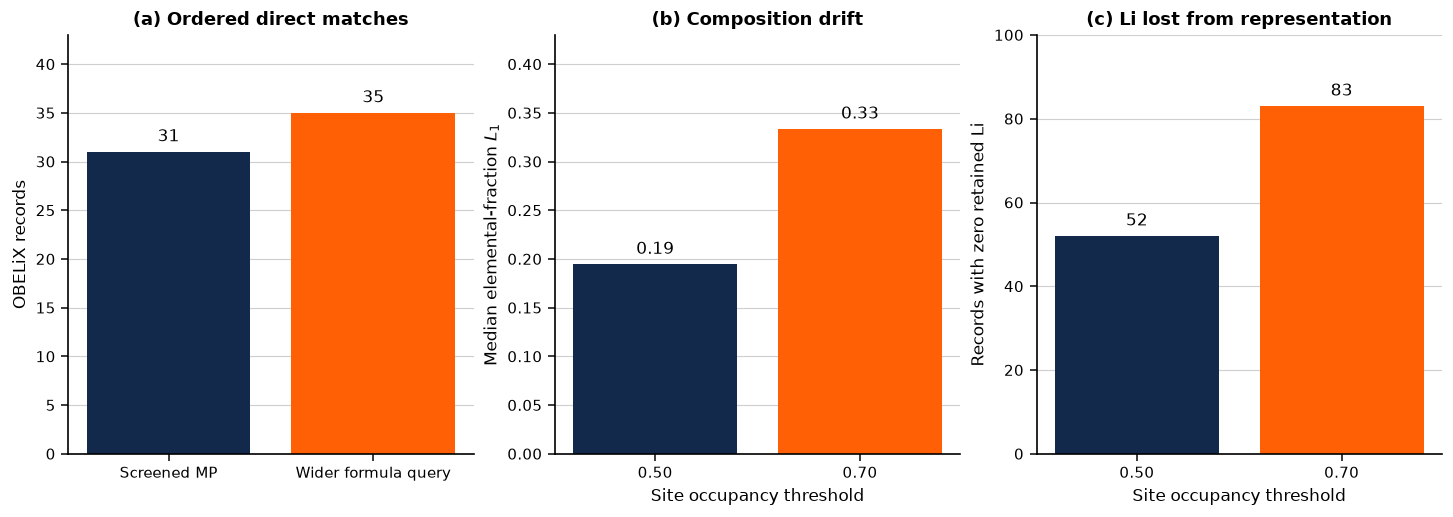

In [26]:
fig,axes=plt.subplots(1,3,figsize=(12.0,4.2),constrained_layout=True)

bars=axes[0].bar(["Screened MP","Wider formula query"],[len(prior),len(current)],
                 color=[ILLINI_BLUE,ILLINI_ORANGE])
axes[0].bar_label(bars,padding=4)
axes[0].set_ylim(0,43)
axes[0].set_title("(a) Ordered direct matches")
axes[0].set_ylabel("OBELiX records")
finish_axis(axes[0],"y")

policy_summary=occupancy_audit.groupby("policy_threshold").agg(
    median_l1=("fractional_composition_l1","median"),
    lose_li=("resolved_has_li",lambda x:(~x).sum()),
)
bars=axes[1].bar(["0.50","0.70"],policy_summary.median_l1,
                 color=[ILLINI_BLUE,ILLINI_ORANGE])
axes[1].bar_label(bars,fmt="%.2f",padding=4)
axes[1].set_ylim(0,.43)
axes[1].set_title("(b) Composition drift")
axes[1].set_xlabel("Site occupancy threshold")
axes[1].set_ylabel(r"Median elemental-fraction $L_1$")
finish_axis(axes[1],"y")

bars=axes[2].bar(["0.50","0.70"],policy_summary.lose_li,
                 color=[ILLINI_BLUE,ILLINI_ORANGE])
axes[2].bar_label(bars,padding=4)
axes[2].set_ylim(0,100)
axes[2].set_title("(c) Li lost from representation")
axes[2].set_xlabel("Site occupancy threshold")
axes[2].set_ylabel("Records with zero retained Li")
finish_axis(axes[2],"y")

save_report_figure(fig,"figure_06_mp_wide_and_occupancy.png")
plt.show()


**Figure 6.** The formula-based Materials Project search adds four ordered direct-source geometric matches. Simple site-threshold resolution produces substantial changes in normalized composition; in 52 and 83 of 161 disordered direct-source CIFs, respectively, the 0.50 and 0.70 policies remove every Li site. The policies are diagnostics and are unsuitable as universal graph preprocessing.


### Decision before graph features

The wider search raises the ordered direct-source MP-matched cohort from 31 to 35. The threshold experiment changes the representation for 100 of 161 disordered direct-source records, with median normalized-composition drift of 0.19 at 0.50 and 0.33 at 0.70. These large changes rule out either threshold as a universal preprocessing rule. The next model should first use the ordered direct-source cohort for a controlled frozen-CHGNet feature comparison, using the same held-out records and training groups for every baseline. Disordered structures require a separate physically justified ordering or disorder-aware representation; no conductivity ranking is generated at this stage.


## 18. Frozen CHGNet pilot on ordered experimental CIFs

The [CHGNet model](https://doi.org/10.1038/s42256-023-00716-3) was pretrained on Materials Project structural calculations. Its documented `predict_structure(..., task="e", return_crystal_feas=True)` interface returns a crystal feature vector; the pretrained weights remain frozen. We use the **41 exact-label, direct-source, metadata-validated, ordered OBELiX CIFs**. This cohort has 33 official training records and 8 official test records. The 35 geometrically matched MP entries remain useful for a later experimental-versus-relaxed-structure sensitivity study; this first pilot uses the publicly released direct-source CIFs throughout. The [OBELiX paper](https://doi.org/10.1039/d5dd00441a) reports that 291 of the 321 released CIFs have added positional noise; ordered sites do not imply unmodified experimental coordinates. Its supplementary benchmark found no significant effect of this noise for the geometric models it tested, so we do not attribute this pilot's error to noise.

For a fair small-data comparison, the same 33 records train a compact neural head on either the frozen CHGNet features or the composition features already defined above. Both approaches tune only on five folds grouped by connected material and publication, then average ten initializations. The median of those same 33 labels is the reference. The official 8-record test cohort is evaluated once, with group bootstrap intervals and a paired bootstrap difference to show its limited precision. All features and labels are scaled within each training fold. The composition vocabulary is defined only from the 33 pilot training records.


In [27]:
from chgnet.model import CHGNet
import chgnet
import torch

CHGNET_FEATURE_PATH=ROOT/"data/processed/obelix_chgnet_frozen_features.csv"
CHGNET_CV_PATH=ROOT/"data/processed/obelix_chgnet_pilot_cv.csv"
CHGNET_TEST_PATH=ROOT/"data/processed/obelix_chgnet_pilot_test.csv"
CHGNET_MODEL_NAME="0.3.0"

ordered_manifest=structure_manifest.loc[
    structure_manifest.primary_structure_cohort_now
].sort_values("record_id").copy()
assert len(ordered_manifest)==41
assert ordered_manifest.source_split.value_counts().to_dict()=={"train":33,"test":8}
assert ordered_manifest.cif_is_ordered.all()

feature_columns=[f"chgnet_{index:02d}" for index in range(64)]
if CHGNET_FEATURE_PATH.exists():
    cached_features=pd.read_csv(CHGNET_FEATURE_PATH)
else:
    cached_features=pd.DataFrame(columns=["record_id","cif_file_sha256",
        "chgnet_package_version","chgnet_checkpoint"]+feature_columns)

feature_rows=cached_features.to_dict("records")
valid_cache={(row["record_id"],row["cif_file_sha256"])
             for row in feature_rows
             if row.get("chgnet_checkpoint")==CHGNET_MODEL_NAME
             and row.get("chgnet_package_version")==chgnet.__version__}
missing_rows=[row for row in ordered_manifest.itertuples(index=False)
              if (row.record_id,row.cif_file_sha256) not in valid_cache]
if missing_rows:
    encoder=CHGNet.load(model_name=CHGNET_MODEL_NAME,use_device="cpu",verbose=False)
    encoder.eval()
    torch.set_num_threads(min(4,torch.get_num_threads()))
    for row in missing_rows:
        crystal=Structure.from_file(ROOT/row.cif_relative_path,primitive=False,sort=False)
        assert crystal.is_ordered
        with torch.no_grad():
            prediction=encoder.predict_structure(
                crystal,task="e",return_crystal_feas=True
            )
        vector=np.asarray(prediction["crystal_fea"],dtype=float).reshape(-1)
        if vector.shape!=(64,) or not np.isfinite(vector).all():
            raise ValueError(f"Invalid CHGNet feature vector: {row.record_id}")
        feature_rows.append({
            "record_id":row.record_id,"cif_file_sha256":row.cif_file_sha256,
            "chgnet_package_version":chgnet.__version__,
            "chgnet_checkpoint":CHGNET_MODEL_NAME,
            **dict(zip(feature_columns,vector)),
        })
        pd.DataFrame(feature_rows).drop_duplicates("record_id",keep="last").to_csv(
            CHGNET_FEATURE_PATH,index=False
        )

frozen_features=pd.read_csv(CHGNET_FEATURE_PATH)
frozen_features=frozen_features.loc[
    frozen_features.record_id.isin(ordered_manifest.record_id)
].drop_duplicates("record_id",keep="last")
assert len(frozen_features)==len(ordered_manifest)
assert np.isfinite(frozen_features[feature_columns].to_numpy()).all()
print(f"Frozen feature matrix: {len(frozen_features)} records × {len(feature_columns)} features")
print("Checkpoint:",CHGNET_MODEL_NAME,"| package:",chgnet.__version__)


Frozen feature matrix: 41 records × 64 features
Checkpoint: 0.3.0 | package: 0.4.2


In [28]:
pilot=ordered_manifest[["record_id","formula","source_split",
    "cif_file_sha256","cif_n_sites"]].merge(
    clean_obelix[["record_id","group_linked",MODEL_TARGET]],
    on="record_id",validate="one_to_one"
).merge(frozen_features[["record_id"]+feature_columns],
        on="record_id",validate="one_to_one")
pilot=pilot.sort_values("record_id").reset_index(drop=True)
pilot_train=pilot.loc[pilot.source_split.eq("train")].reset_index(drop=True)
pilot_test=pilot.loc[pilot.source_split.eq("test")].reset_index(drop=True)

pilot_vocab=sorted({str(element) for formula in pilot_train.formula for element in parse_composition(formula).elements})
feature_sets={
    "Frozen CHGNet":(
        pilot_train[feature_columns].copy(),pilot_test[feature_columns].copy()
    ),
    "Composition MLP":(
        composition_features(pilot_train.formula,pilot_vocab),
        composition_features(pilot_test.formula,pilot_vocab),
    ),
}
head_configs=[
    {"hidden_layer_sizes":(8,),"alpha":1.0},
    {"hidden_layer_sizes":(8,),"alpha":10.0},
    {"hidden_layer_sizes":(16,),"alpha":10.0},
]
pilot_splits=list(GroupKFold(n_splits=5,shuffle=True,random_state=RANDOM_STATE).split(
    pilot_train,pilot_train[MODEL_TARGET],pilot_train.group_linked
))
pilot_cv_rows=[]
for representation,(fit_features,test_features) in feature_sets.items():
    for config_id,config in enumerate(head_configs):
        for fold,(train_index,val_index) in enumerate(pilot_splits,start=1):
            predictions=[]
            for seed in (17,43):
                neural_head=build_mlp(config,seed)
                neural_head.fit(fit_features.iloc[train_index],
                                pilot_train[MODEL_TARGET].iloc[train_index])
                predictions.append(neural_head.predict(
                    fit_features.iloc[val_index]))
            mean_prediction=np.mean(predictions,axis=0)
            pilot_cv_rows.append({
                "representation":representation,"config_id":config_id,
                "config":config_label(config),"fold":fold,
                "validation_rows":len(val_index),
                "validation_groups":pilot_train.group_linked.iloc[val_index].nunique(),
                "MAE_dex":mean_absolute_error(
                    pilot_train[MODEL_TARGET].iloc[val_index],mean_prediction),
            })

pilot_cv=pd.DataFrame(pilot_cv_rows)
pilot_cv.to_csv(CHGNET_CV_PATH,index=False)
pilot_selected=(pilot_cv.groupby(["representation","config_id"],as_index=False)
                .MAE_dex.mean().sort_values(
                    ["representation","MAE_dex","config_id"]
                ).drop_duplicates("representation"))
display(pilot_selected)


,representation,config_id,MAE_dex
1,Composition MLP,1,2.551397
5,Frozen CHGNet,2,3.215208


In [29]:
pilot_test_predictions=pilot_test[["record_id","formula","group_linked",
    MODEL_TARGET]].copy()
pilot_metrics=[]
y_pilot_train=pilot_train[MODEL_TARGET]
y_pilot_test=pilot_test[MODEL_TARGET]
pilot_test_predictions["training_median_prediction"]=float(y_pilot_train.median())

for representation,(fit_features,test_features) in feature_sets.items():
    config_id=int(pilot_selected.loc[
        pilot_selected.representation.eq(representation),"config_id"
    ].iloc[0])
    config=head_configs[config_id]
    members=[]
    for seed in FINAL_ENSEMBLE_SEEDS:
        neural_head=build_mlp(config,seed)
        neural_head.fit(fit_features,y_pilot_train)
        members.append(neural_head.predict(test_features))
    prediction=np.mean(members,axis=0)
    spread=np.std(members,axis=0,ddof=1)
    key="chgnet" if representation=="Frozen CHGNet" else "composition"
    pilot_test_predictions[f"{key}_prediction"]=prediction
    pilot_test_predictions[f"{key}_ensemble_std"]=spread
    pilot_metrics.append({"model":representation,"selected_config":config_label(config),
        "grouped_CV_MAE_dex":float(pilot_selected.loc[
            pilot_selected.representation.eq(representation),"MAE_dex"].iloc[0]),
        "official_test_MAE_dex":mean_absolute_error(y_pilot_test,prediction),
        "official_test_RMSE_dex":np.sqrt(mean_squared_error(y_pilot_test,prediction)),
        "official_test_R2":r2_score(y_pilot_test,prediction)})

median_mae=mean_absolute_error(y_pilot_test,
    pilot_test_predictions.training_median_prediction)
pilot_metrics.append({"model":"Training median","selected_config":"none",
    "grouped_CV_MAE_dex":np.nan,
    "official_test_MAE_dex":median_mae,
    "official_test_RMSE_dex":np.sqrt(mean_squared_error(
        y_pilot_test,pilot_test_predictions.training_median_prediction)),
    "official_test_R2":r2_score(
        y_pilot_test,pilot_test_predictions.training_median_prediction)})

# Resample the eight held-out connected groups together; the interval is descriptive.
rng=np.random.default_rng(RANDOM_STATE)
groups=pilot_test.group_linked.unique()
positions={g:np.flatnonzero(pilot_test.group_linked.to_numpy()==g) for g in groups}
for metric in pilot_metrics:
    column={"Frozen CHGNet":"chgnet_prediction",
            "Composition MLP":"composition_prediction",
            "Training median":"training_median_prediction"}[metric["model"]]
    prediction=pilot_test_predictions[column].to_numpy()
    sampled_maes=[]
    for _ in range(2000):
        draw=rng.choice(groups,size=len(groups),replace=True)
        idx=np.concatenate([positions[g] for g in draw])
        sampled_maes.append(mean_absolute_error(y_pilot_test.iloc[idx],prediction[idx]))
    metric["bootstrap_MAE_95pct_low"]=np.quantile(sampled_maes,.025)
    metric["bootstrap_MAE_95pct_high"]=np.quantile(sampled_maes,.975)

pilot_metric_table=pd.DataFrame(pilot_metrics)
pilot_test_predictions.to_csv(CHGNET_TEST_PATH,index=False)
display(pilot_metric_table)
assert len(pilot_test_predictions)==8
print("Screening gate: closed; eight test records are insufficient for broad MP ranking.")

# Paired resampling preserves each material's two predictions and the official split.
truth=pilot_test_predictions[MODEL_TARGET].to_numpy()
composition_error=np.abs(truth-pilot_test_predictions.composition_prediction.to_numpy())
chgnet_error=np.abs(truth-pilot_test_predictions.chgnet_prediction.to_numpy())
pilot_test_predictions["composition_abs_error_dex"]=composition_error
pilot_test_predictions["chgnet_abs_error_dex"]=chgnet_error
pilot_test_predictions["chgnet_minus_composition_error_dex"]=chgnet_error-composition_error
pilot_test_predictions.to_csv(CHGNET_TEST_PATH,index=False)

paired_differences=[]
rng_paired=np.random.default_rng(RANDOM_STATE)
for _ in range(10000):
    draw=rng_paired.choice(groups,size=len(groups),replace=True)
    idx=np.concatenate([positions[g] for g in draw])
    paired_differences.append(float((chgnet_error[idx]-composition_error[idx]).mean()))
paired_interval=np.quantile(paired_differences,[.025,.975])
paired_delta=float((chgnet_error-composition_error).mean())
print(f"CHGNet minus composition test MAE: {paired_delta:+.2f} dex "
      f"(paired group-bootstrap 95% interval {paired_interval[0]:+.2f} "
      f"to {paired_interval[1]:+.2f}; n={len(groups)} test groups)")

largest=pilot_test_predictions.assign(
    largest_error=np.maximum(composition_error,chgnet_error)
).nlargest(2,"largest_error")
print("Two largest-error source labels:")
display(largest[["record_id","formula",MODEL_TARGET,
    "composition_abs_error_dex","chgnet_abs_error_dex"]])
print(f"Their share of total absolute error: "
      f"composition {composition_error[largest.index].sum()/composition_error.sum():.0%}; "
      f"CHGNet {chgnet_error[largest.index].sum()/chgnet_error.sum():.0%}")


,model,selected_config,grouped_CV_MAE_dex,official_test_MAE_dex,official_test_RMSE_dex,official_test_R2,bootstrap_MAE_95pct_low,bootstrap_MAE_95pct_high
0,Frozen CHGNet,16; α=10,3.215208,2.958298,3.796680,0.233117,1.539774,4.734625
1,Composition MLP,8; α=10,2.551397,2.589806,3.429782,0.374173,1.237424,4.234297
2,Training median,none,NaN,3.535225,4.344205,-0.004019,2.053333,5.372166


Screening gate: closed; eight test records are insufficient for broad MP ranking.
CHGNet minus composition test MAE: +0.37 dex (paired group-bootstrap 95% interval -0.06 to +0.81; n=8 test groups)
Two largest-error source labels:


,record_id,formula,log10_sigma_S_cm,composition_abs_error_dex,chgnet_abs_error_dex
1,OBELIX:7cr,Li2NaBP2O8,-17.356547,7.168784,8.244301
5,OBELIX:mdp,Li7P3S11,-2.494850,5.201037,5.150049


Their share of total absolute error: composition 60%; CHGNet 57%


Saved figure: /Users/zhy/Downloads/battery_ml_starter/figures/figure_07_frozen_chgnet_pilot.png


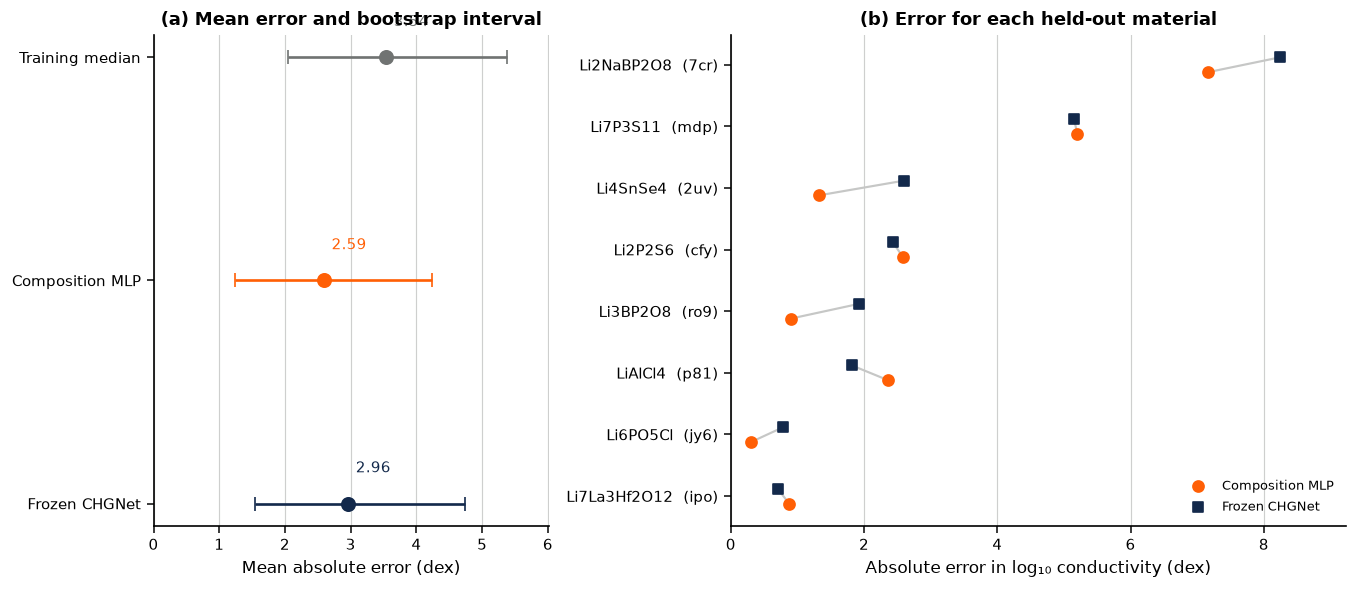

In [30]:
fig,axes=plt.subplots(1,2,figsize=(11.2,4.8),
    gridspec_kw={"width_ratios":[.9,1.4]},constrained_layout=True)
order=["Training median","Composition MLP","Frozen CHGNet"]
plot_metrics=pilot_metric_table.set_index("model").loc[order]
point_colors=[ILLINI_STORM,ILLINI_ORANGE,ILLINI_BLUE]
for row,(name,color) in enumerate(zip(order,point_colors)):
    result=plot_metrics.loc[name]
    estimate=result.official_test_MAE_dex
    interval=[[estimate-result.bootstrap_MAE_95pct_low],
              [result.bootstrap_MAE_95pct_high-estimate]]
    axes[0].errorbar(estimate,row,xerr=interval,fmt="o",markersize=8,
        color=color,ecolor=color,capsize=4,lw=1.6)
    axes[0].text(estimate+.12,row-.14,f"{estimate:.2f}",color=color,fontsize=9)
axes[0].set_yticks(range(3),order)
axes[0].invert_yaxis()
axes[0].set_xlim(0,max(plot_metrics.bootstrap_MAE_95pct_high)*1.12)
axes[0].set_title("(a) Mean error and bootstrap interval")
axes[0].set_xlabel("Mean absolute error (dex)")
finish_axis(axes[0],"x")

record_order=pilot_test_predictions.sort_values(
    "chgnet_abs_error_dex",ascending=True).reset_index(drop=True)
labels=record_order.formula+"  ("+record_order.record_id.str.split(":").str[-1]+")"
positions_y=np.arange(len(record_order))
axes[1].scatter(record_order.composition_abs_error_dex,positions_y-.12,
    color=ILLINI_ORANGE,label="Composition MLP",s=44,zorder=3)
axes[1].scatter(record_order.chgnet_abs_error_dex,positions_y+.12,
    color=ILLINI_BLUE,label="Frozen CHGNet",marker="s",s=42,zorder=3)
for row in positions_y:
    axes[1].plot([record_order.composition_abs_error_dex.iloc[row],
                  record_order.chgnet_abs_error_dex.iloc[row]],
                 [row-.12,row+.12],color=ILLINI_STORM_LIGHT,lw=1.3,zorder=1)
axes[1].set_yticks(positions_y,labels)
axes[1].set_xlim(0,max(record_order.chgnet_abs_error_dex.max(),
                     record_order.composition_abs_error_dex.max())*1.12)
axes[1].set_title("(b) Error for each held-out material")
axes[1].set_xlabel("Absolute error in log₁₀ conductivity (dex)")
axes[1].legend(loc="lower right",fontsize=8)
finish_axis(axes[1],"x")
save_report_figure(fig,"figure_07_frozen_chgnet_pilot.png")
plt.show()

**Figure 7.** Same eight official test records for all three models. The left panel gives test MAE with descriptive 95% group-bootstrap intervals. The right panel shows paired errors for every material. OBELIX:7cr (Li₂NaBP₂O₈, 4.4 × 10⁻¹⁸ S/cm) and OBELIX:mdp (Li₇P₃S₁₁, 3.2 × 10⁻³ S/cm) are source-reported conductivity extremes and dominate the total error. The paired CHGNet-minus-composition interval above crosses zero, so the apparent model ranking is uncertain on eight test groups. Ensemble spread across random initializations is not a calibrated prediction interval.

### Next decision

The pilot is a diagnostic, not a validated conductivity predictor. Keep the Materials Project screening gate closed. Expand the trustworthy labeled structure cohort and verify that graph features improve grouped validation before revisiting disordered CIFs or issuing material rankings. [OBELiX supplementary information](https://www.rsc.org/suppdata/d5/dd/d5dd00441a/d5dd00441a1.pdf) found no significant performance effect of added positional noise in its benchmark models; the limitation here is primarily the tiny labeled pilot and uncertain transfer from an energy-pretrained encoder to conductivity.

## 19. Occupancy-aware structure descriptors: larger labeled cohort

The 35 accepted Materials Project geometry matches are already among the 41 ordered direct-source records, so they add **no new conductivity labels**. The next comparison instead uses all **202 exact-label, direct-source, metadata-validated OBELiX CIFs**: 159 official training and 43 official test records. Of these, 161 have partial or mixed occupancy. We retain each crystallographic occupancy rather than choosing an arbitrary atom at a disordered site.

The descriptors follow the physical questions used by [Sendek et al.](https://doi.org/10.1021/acs.chemmater.8b03272): how many Li sites are nearby, how far apart are Li sites, and what is the local anion environment? Li-site occupancies also matter for transport, as described in [this structural-descriptor study](https://doi.org/10.1080/14686996.2020.1824985). For a Li site $i$ with occupancy $p_i$, the mean descriptor is $\langle d\rangle_{\mathrm{Li}}=\sum_i p_i d_i/\sum_i p_i$. A nearby site's contribution to a coordination count is its occupancy. We add expected Li number density $\sum_i p_i/V$, vacancy fraction, and mass density. The 4.0, 3.2, and 6.0 Å radii are declared analysis cutoffs, not migration barriers or a proven conduction network. Li–Li pairs closer than 1.5 Å are excluded from neighbor counts and nearest-distance features because the released disordered CIFs frequently represent nearby alternative Li positions; treating both as simultaneously occupied would be misleading. This exclusion is a preprocessing rule, not a physical hopping threshold. Missing neighbor distances are imputed using only the training fold.

We compare a composition-only neural head with the same head given these structural descriptors. Both models use identical connected-group folds, the official test records, and train-only feature scaling. Because the test set contains multiple measurements from some connected families, we report both record-weighted and equal-weight-per-group MAE. This tests whether interpretable structural information adds value without claiming that a static CIF predicts ion motion directly.

In [31]:
from sklearn.impute import SimpleImputer

DESCRIPTOR_VERSION="v2_exclude_split_li_sites_below_1p5A"
STRUCTURE_FEATURE_PATH=ROOT/"data/processed/obelix_occupancy_structural_features.csv"
STRUCTURE_CV_PATH=ROOT/"data/processed/obelix_structural_mlp_cv.csv"
STRUCTURE_TEST_PATH=ROOT/"data/processed/obelix_structural_mlp_test.csv"
ANION_SYMBOLS={"O","S","F","Cl","Br","I","N","Se"}
STRUCTURE_COLUMNS=[
    "expected_li_density_A_minus3","expected_atom_density_A_minus3",
    "volume_per_expected_atom_A3","density_g_cm3",
    "mean_li_site_occupancy","li_fraction_on_partial_sites",
    "mean_li_neighbors_4A","mean_nearest_li_li_A",
    "mean_anion_neighbors_3p2A","mean_nearest_li_anion_A",
    "overall_vacancy_fraction",
]

def site_occupancy(site,symbols):
    return sum(float(occupancy) for species,occupancy in site.species.items()
               if species.symbol in symbols)

def occupancy_structure_descriptors(crystal):
    li_sites=[site for site in crystal if site_occupancy(site,{"Li"})>0]
    li_weights=np.array([site_occupancy(site,{"Li"}) for site in li_sites])
    if not len(li_sites) or li_weights.sum()<=0:
        raise ValueError("No Li sites in validated structure")
    neighbors=crystal.get_all_neighbors(6.0,sites=li_sites)
    li_counts=[];anion_counts=[];nearest_li=[];nearest_anion=[]
    for local_neighbors in neighbors:
        li_pairs=[(n.nn_distance,site_occupancy(n,{"Li"})) for n in local_neighbors
                  if n.nn_distance>=1.5 and site_occupancy(n,{"Li"})>0]
        anion_pairs=[(n.nn_distance,site_occupancy(n,ANION_SYMBOLS))
                     for n in local_neighbors
                     if n.nn_distance>0.1 and site_occupancy(n,ANION_SYMBOLS)>0]
        li_counts.append(sum(p for d,p in li_pairs if d<=4.0))
        anion_counts.append(sum(p for d,p in anion_pairs if d<=3.2))
        nearest_li.append(min((d for d,p in li_pairs),default=np.nan))
        nearest_anion.append(min((d for d,p in anion_pairs),default=np.nan))

    def weighted_mean(values):
        values=np.asarray(values,dtype=float)
        valid=np.isfinite(values)
        return float(np.average(values[valid],weights=li_weights[valid])) if valid.any() else np.nan

    expected_atoms=float(crystal.composition.num_atoms)
    total_site_occupancy=sum(sum(float(p) for p in site.species.values())
                             for site in crystal)
    return {
        "expected_li_density_A_minus3":float(li_weights.sum()/crystal.volume),
        "expected_atom_density_A_minus3":expected_atoms/crystal.volume,
        "volume_per_expected_atom_A3":crystal.volume/expected_atoms,
        "density_g_cm3":float(crystal.density),
        "mean_li_site_occupancy":weighted_mean(li_weights),
        "li_fraction_on_partial_sites":float(li_weights[li_weights<0.999].sum()/li_weights.sum()),
        "mean_li_neighbors_4A":weighted_mean(li_counts),
        "mean_nearest_li_li_A":weighted_mean(nearest_li),
        "mean_anion_neighbors_3p2A":weighted_mean(anion_counts),
        "mean_nearest_li_anion_A":weighted_mean(nearest_anion),
        "overall_vacancy_fraction":1.0-total_site_occupancy/len(crystal),
    }

descriptor_manifest=structure_manifest.loc[
    structure_manifest.has_exact_conductivity_label
    & structure_manifest.structure_relation.eq("direct_source_cif")
    & structure_manifest.metadata_validation_pass
].sort_values("record_id").copy()
assert len(descriptor_manifest)==202
assert descriptor_manifest.source_split.value_counts().to_dict()=={"train":159,"test":43}
cached=pd.read_csv(STRUCTURE_FEATURE_PATH) if STRUCTURE_FEATURE_PATH.exists() else pd.DataFrame()
feature_rows=cached.to_dict("records")
valid_cache={(row["record_id"],row["cif_file_sha256"]) for row in feature_rows
             if row.get("descriptor_version")==DESCRIPTOR_VERSION}
missing=[row for row in descriptor_manifest.itertuples(index=False)
         if (row.record_id,row.cif_file_sha256) not in valid_cache]
for row in missing:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        crystal=Structure.from_file(ROOT/row.cif_relative_path,primitive=False,sort=False)
    feature_rows.append({"descriptor_version":DESCRIPTOR_VERSION,
        "record_id":row.record_id,
        "cif_file_sha256":row.cif_file_sha256,
        **occupancy_structure_descriptors(crystal)})
if missing:
    pd.DataFrame(feature_rows).drop_duplicates("record_id",keep="last").to_csv(
        STRUCTURE_FEATURE_PATH,index=False)
structure_features=pd.read_csv(STRUCTURE_FEATURE_PATH)
assert len(structure_features)==202
assert structure_features.descriptor_version.eq(DESCRIPTOR_VERSION).all()
assert set(structure_features.record_id)==set(descriptor_manifest.record_id)
assert np.isfinite(structure_features[STRUCTURE_COLUMNS].dropna().to_numpy()).all()
print(f"Occupancy-aware descriptors: {len(structure_features)} records, "
      f"{len(STRUCTURE_COLUMNS)} features, {len(missing)} newly extracted")
display(structure_features[STRUCTURE_COLUMNS].describe().T[["count","min","50%","max"]])

Occupancy-aware descriptors: 202 records, 11 features, 0 newly extracted


,count,min,50%,max
expected_li_density_A_minus3,202.0,0.000166,0.021104,0.087011
expected_atom_density_A_minus3,202.0,0.030057,0.076121,0.116015
volume_per_expected_atom_A3,202.0,8.619553,13.137796,33.270384
density_g_cm3,202.0,0.916070,3.021949,6.663108
mean_li_site_occupancy,202.0,0.020000,0.567072,1.000000
li_fraction_on_partial_sites,202.0,0.000000,1.000000,1.000000
mean_li_neighbors_4A,202.0,0.000000,4.825646,21.333333
mean_nearest_li_li_A,198.0,1.625154,2.544683,5.868126
mean_anion_neighbors_3p2A,202.0,0.000000,5.000000,12.000000
mean_nearest_li_anion_A,196.0,1.492100,2.265651,2.860166


In [32]:
descriptor_cohort=descriptor_manifest[["record_id","formula","source_split",
    "cif_is_ordered"]].merge(
    clean_obelix[["record_id","group_linked",MODEL_TARGET]],
    on="record_id",validate="one_to_one").merge(
    structure_features[["record_id"]+STRUCTURE_COLUMNS],
    on="record_id",validate="one_to_one")
descriptor_train=descriptor_cohort.loc[descriptor_cohort.source_split.eq("train")].reset_index(drop=True)
descriptor_test=descriptor_cohort.loc[descriptor_cohort.source_split.eq("test")].reset_index(drop=True)
assert set(descriptor_train.group_linked).isdisjoint(descriptor_test.group_linked)
descriptor_vocab=sorted({str(element) for formula in descriptor_train.formula
                         for element in parse_composition(formula).elements})
composition_train=composition_features(descriptor_train.formula,descriptor_vocab)
composition_test=composition_features(descriptor_test.formula,descriptor_vocab)
descriptor_inputs={
    "Composition MLP":(composition_train,composition_test),
    "Composition + structure MLP":(
        pd.concat([composition_train,descriptor_train[STRUCTURE_COLUMNS]],axis=1),
        pd.concat([composition_test,descriptor_test[STRUCTURE_COLUMNS]],axis=1)),
}

def build_descriptor_mlp(config,seed):
    return TransformedTargetRegressor(regressor=Pipeline([
        ("impute",SimpleImputer(strategy="median")),
        ("scale",StandardScaler()),
        ("mlp",MLPRegressor(hidden_layer_sizes=config["hidden_layer_sizes"],
            alpha=config["alpha"],solver="lbfgs",activation="relu",
            max_iter=1200,tol=1e-5,random_state=seed)),
    ]),transformer=StandardScaler())

descriptor_configs=[
    {"hidden_layer_sizes":(16,),"alpha":1.0},
    {"hidden_layer_sizes":(16,),"alpha":10.0},
    {"hidden_layer_sizes":(32,),"alpha":10.0},
]
descriptor_folds=list(GroupKFold(n_splits=5,shuffle=True,
    random_state=RANDOM_STATE).split(descriptor_train,
    descriptor_train[MODEL_TARGET],descriptor_train.group_linked))
cv_entries=[]
for representation,(fit_features,_) in descriptor_inputs.items():
    for config_id,config in enumerate(descriptor_configs):
        for fold,(fit_idx,val_idx) in enumerate(descriptor_folds,start=1):
            members=[]
            for seed in TUNING_SEEDS:
                model=build_descriptor_mlp(config,seed)
                model.fit(fit_features.iloc[fit_idx],
                          descriptor_train[MODEL_TARGET].iloc[fit_idx])
                members.append(model.predict(fit_features.iloc[val_idx]))
            prediction=np.mean(members,axis=0)
            cv_entries.append({"representation":representation,"config_id":config_id,
                "config":config_label(config),"fold":fold,
                "validation_rows":len(val_idx),
                "validation_groups":descriptor_train.group_linked.iloc[val_idx].nunique(),
                "MAE_dex":mean_absolute_error(
                    descriptor_train[MODEL_TARGET].iloc[val_idx],prediction)})
median_fold_maes=[mean_absolute_error(
    descriptor_train[MODEL_TARGET].iloc[val_idx],
    np.full(len(val_idx),descriptor_train[MODEL_TARGET].iloc[fit_idx].median())
) for fit_idx,val_idx in descriptor_folds]
descriptor_cv=pd.DataFrame(cv_entries)
descriptor_cv.to_csv(STRUCTURE_CV_PATH,index=False)
descriptor_selected=(descriptor_cv.groupby(["representation","config_id"],as_index=False)
    .MAE_dex.mean().sort_values(["representation","MAE_dex","config_id"])
    .drop_duplicates("representation"))
display(descriptor_selected)

,representation,config_id,MAE_dex
0,Composition + structure MLP,0,1.581767
5,Composition MLP,2,2.163934


In [33]:
descriptor_predictions=descriptor_test[["record_id","formula","group_linked",
    "cif_is_ordered",MODEL_TARGET]].copy()
descriptor_predictions["training_median_prediction"]=float(
    descriptor_train[MODEL_TARGET].median())
descriptor_results=[]
for representation,(fit_features,test_features) in descriptor_inputs.items():
    config_id=int(descriptor_selected.loc[
        descriptor_selected.representation.eq(representation),"config_id"].iloc[0])
    config=descriptor_configs[config_id]
    members=[]
    for seed in FINAL_ENSEMBLE_SEEDS:
        model=build_descriptor_mlp(config,seed)
        model.fit(fit_features,descriptor_train[MODEL_TARGET])
        members.append(model.predict(test_features))
    prediction=np.mean(members,axis=0)
    column="composition_prediction" if representation=="Composition MLP" else "structure_prediction"
    descriptor_predictions[column]=prediction
    descriptor_predictions[column.replace("prediction","ensemble_std")]=np.std(members,axis=0,ddof=1)
    descriptor_results.append({"model":representation,"selected_config":config_label(config),
        "grouped_CV_MAE_dex":float(descriptor_selected.loc[
            descriptor_selected.representation.eq(representation),"MAE_dex"].iloc[0]),
        "official_test_MAE_dex":mean_absolute_error(
            descriptor_test[MODEL_TARGET],prediction)})
descriptor_results.append({"model":"Training median","selected_config":"none",
    "grouped_CV_MAE_dex":float(np.mean(median_fold_maes)),
    "official_test_MAE_dex":mean_absolute_error(
        descriptor_test[MODEL_TARGET],descriptor_predictions.training_median_prediction)})

truth=descriptor_predictions[MODEL_TARGET].to_numpy()
descriptor_predictions["composition_abs_error_dex"]=abs(
    truth-descriptor_predictions.composition_prediction.to_numpy())
descriptor_predictions["structure_abs_error_dex"]=abs(
    truth-descriptor_predictions.structure_prediction.to_numpy())
descriptor_predictions.to_csv(STRUCTURE_TEST_PATH,index=False)
descriptor_result_table=pd.DataFrame(descriptor_results)
test_groups=descriptor_test.group_linked.unique()
group_rows={g:np.flatnonzero(descriptor_test.group_linked.to_numpy()==g) for g in test_groups}
rng=np.random.default_rng(RANDOM_STATE)
bootstrap_draws=[np.concatenate([group_rows[g] for g in rng.choice(
    test_groups,size=len(test_groups),replace=True)]) for _ in range(5000)]
for row in descriptor_results:
    column={"Composition MLP":"composition_prediction",
        "Composition + structure MLP":"structure_prediction",
        "Training median":"training_median_prediction"}[row["model"]]
    error=abs(truth-descriptor_predictions[column].to_numpy())
    interval=np.quantile([error[idx].mean() for idx in bootstrap_draws],[.025,.975])
    row["bootstrap_MAE_low"],row["bootstrap_MAE_high"]=interval
delta=(descriptor_predictions.structure_abs_error_dex-
       descriptor_predictions.composition_abs_error_dex).to_numpy()
delta_interval=np.quantile([delta[idx].mean() for idx in bootstrap_draws],[.025,.975])
descriptor_result_table=pd.DataFrame(descriptor_results)
display(descriptor_result_table)
print(f"Structure minus composition MAE: {delta.mean():+.2f} dex; "
      f"paired group-bootstrap 95% interval {delta_interval[0]:+.2f} to "
      f"{delta_interval[1]:+.2f}; {len(test_groups)} test groups")
print("Screening gate remains closed until structural improvement is replicated.")

# Each connected material/publication family receives one vote in this audit.
descriptor_predictions["median_abs_error_dex"]=abs(
    truth-descriptor_predictions.training_median_prediction.to_numpy())
descriptor_predictions.to_csv(STRUCTURE_TEST_PATH,index=False)
group_audit=(descriptor_predictions.groupby("group_linked",as_index=False).agg(
    test_records=("record_id","size"),
    distinct_formulas=("formula","nunique"),
    composition_MAE_dex=("composition_abs_error_dex","mean"),
    structure_MAE_dex=("structure_abs_error_dex","mean"),
    median_MAE_dex=("median_abs_error_dex","mean")))
group_audit["structure_minus_composition_dex"]=(
    group_audit.structure_MAE_dex-group_audit.composition_MAE_dex)
GROUP_AUDIT_PATH=ROOT/"data/processed/obelix_structural_mlp_group_audit.csv"
group_audit.to_csv(GROUP_AUDIT_PATH,index=False)
group_bootstrap=rng.integers(0,len(group_audit),size=(10000,len(group_audit)))
group_metric_columns={
    "Training median":"median_MAE_dex",
    "Composition MLP":"composition_MAE_dex",
    "Composition + structure MLP":"structure_MAE_dex",
}
for row in descriptor_results:
    group_errors=group_audit[group_metric_columns[row["model"]]].to_numpy()
    row["group_balanced_MAE_dex"]=float(group_errors.mean())
    low,high=np.quantile(group_errors[group_bootstrap].mean(axis=1),[.025,.975])
    row["group_balanced_low"],row["group_balanced_high"]=low,high
group_delta=group_audit.structure_minus_composition_dex.to_numpy()
group_delta_interval=np.quantile(group_delta[group_bootstrap].mean(axis=1),[.025,.975])
descriptor_result_table=pd.DataFrame(descriptor_results)
display(descriptor_result_table[["model","grouped_CV_MAE_dex",
    "official_test_MAE_dex","group_balanced_MAE_dex"]])
print(f"Equal-weight group difference (structure minus composition): "
      f"{group_delta.mean():+.2f} dex; 95% bootstrap interval "
      f"{group_delta_interval[0]:+.2f} to {group_delta_interval[1]:+.2f}")
largest_group=group_audit.nlargest(1,"test_records").iloc[0]
print(f"Largest test family: {largest_group.group_linked}, "
      f"{int(largest_group.test_records)} records, "
      f"structure-minus-composition {largest_group.structure_minus_composition_dex:+.2f} dex")
print("Without that family, group-balanced MAEs:")
display(group_audit.loc[group_audit.group_linked.ne(largest_group.group_linked),
    ["median_MAE_dex","composition_MAE_dex","structure_MAE_dex"]].mean())


,model,selected_config,grouped_CV_MAE_dex,official_test_MAE_dex,bootstrap_MAE_low,bootstrap_MAE_high
0,Composition MLP,32; α=10,2.163934,2.432500,1.300286,3.541980
1,Composition + structure MLP,16; α=1,1.581767,1.839868,1.255648,2.930891
2,Training median,none,2.194261,1.823061,1.158314,3.101547


Structure minus composition MAE: -0.59 dex; paired group-bootstrap 95% interval -1.63 to +0.42; 20 test groups
Screening gate remains closed until structural improvement is replicated.


,model,grouped_CV_MAE_dex,official_test_MAE_dex,group_balanced_MAE_dex
0,Composition MLP,2.163934,2.432500,2.873032
1,Composition + structure MLP,1.581767,1.839868,2.729872
2,Training median,2.194261,1.823061,2.760385


Equal-weight group difference (structure minus composition): -0.14 dex; 95% bootstrap interval -0.67 to +0.30
Largest test family: linked_0149, 10 records, structure-minus-composition -3.06 dex
Without that family, group-balanced MAEs:


median_MAE_dex         2.869002
composition_MAE_dex    2.817649
structure_MAE_dex      2.828226
dtype: float64

Saved figure: /Users/zhy/Downloads/battery_ml_starter/figures/figure_08_occupancy_structural_pilot.png


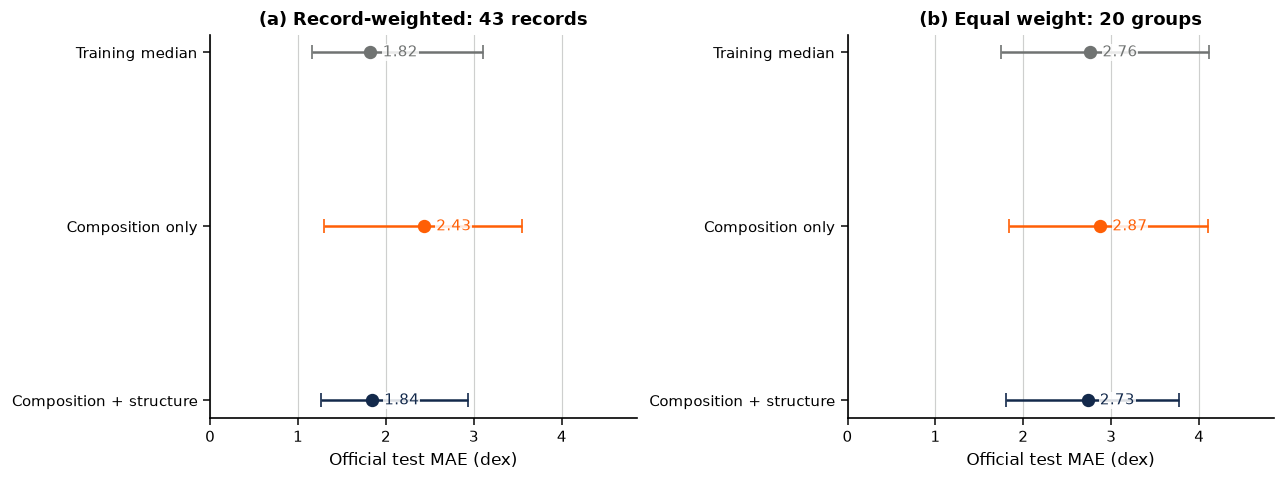

In [34]:
fig,axes=plt.subplots(1,2,figsize=(10.6,3.9),constrained_layout=True)
names=["Training median","Composition MLP","Composition + structure MLP"]
short_names=["Training median","Composition only","Composition + structure"]
colors=[ILLINI_STORM,ILLINI_ORANGE,ILLINI_BLUE]
results=descriptor_result_table.set_index("model").loc[names]
panel_specs=[
    ("official_test_MAE_dex","bootstrap_MAE_low","bootstrap_MAE_high",
     "(a) Record-weighted: 43 records"),
    ("group_balanced_MAE_dex","group_balanced_low","group_balanced_high",
     "(b) Equal weight: 20 groups"),
]
for axis,(estimate_col,low_col,high_col,title) in zip(axes,panel_specs):
    for y,(name,color) in enumerate(zip(names,colors)):
        result=results.loc[name]
        point=result[estimate_col]
        axis.errorbar(point,y,xerr=[[point-result[low_col]],
            [result[high_col]-point]],fmt="o",color=color,
            ecolor=color,capsize=4,markersize=7)
        axis.text(point+.14,y,f"{point:.2f}",va="center",color=color,fontsize=9,
            bbox={"facecolor":"white","edgecolor":"none","alpha":.85,"pad":.5})
    axis.set_yticks(range(3),short_names)
    axis.invert_yaxis()
    axis.set_xlim(0,max(results.bootstrap_MAE_high.max(),
                       results.group_balanced_high.max())*1.18)
    axis.set_xlabel("Official test MAE (dex)")
    axis.set_title(title)
    finish_axis(axis,"x")
save_report_figure(fig,"figure_08_occupancy_structural_pilot.png")
plt.show()

**Figure 8.** The same 43 official test records assess both neural heads. In (a), each record contributes equally; in (b), each connected material/publication group contributes equally. Whiskers are descriptive 95% bootstrap intervals. The apparent record-level improvement is concentrated in one ten-record test family. The group-balanced difference is small and uncertain, so the structural descriptors are useful to investigate but do not pass the screening gate. Li sites separated by less than 1.5 Å are excluded as alternative positions in the descriptors. A static CIF does not establish a migration pathway or validate the planned Arrhenius graph model.

## 20. Can this model select useful materials?

For material design, mean absolute error is secondary to **finding high-conductivity materials in unfamiliar families**. [Sendek et al.](https://doi.org/10.1021/acs.chemmater.8b03272) used 0.1 mS/cm, or $10^{-4}$ S/cm, as an illustrative fast-conductor threshold. We audit that target and a stricter $10^{-3}$ S/cm target on the official 43-record test set. A realistic small follow-up budget is five materials, with at most one top-scored material per connected test group. This is a retrospective diagnostic: these OBELiX conductivities are already known and no Materials Project candidate is ranked here.

The readiness question is whether the top-five selections consistently beat a random five-group choice and whether they recover known fast conductors from different chemistries. We report the exact random-choice tail probability only as a small-sample reference. This audit is exploratory and cannot serve as prospective validation.

In [35]:
from scipy.stats import hypergeom
from sklearn.metrics import average_precision_score, roc_auc_score

SELECTION_AUDIT_PATH=ROOT/"data/processed/obelix_retrospective_selection_audit.csv"
selection_rows=[]
selection_rankings={}
for method,score_column in [("Composition MLP","composition_prediction"),
                            ("Composition + structure MLP","structure_prediction")]:
    # The selected material is the highest-scored record in each connected family.
    ranked=(descriptor_predictions.sort_values(score_column,ascending=False)
            .drop_duplicates("group_linked").reset_index(drop=True).copy())
    ranked["selection_method"]=method
    ranked["group_diverse_rank"]=np.arange(1,len(ranked)+1)
    ranked["selection_score_log10_S_cm"]=ranked[score_column]
    selection_rankings[method]=ranked
    for threshold in [-4.0,-3.0]:
        high=ranked[MODEL_TARGET].ge(threshold).to_numpy()
        hits5=int(high[:5].sum())
        selection_rows.append({
            "method":method,"threshold_log10_S_cm":threshold,
            "test_groups":len(ranked),"positive_representative_groups":int(high.sum()),
            "top5_hits":hits5,"top5_precision":hits5/5,
            "top10_hits":int(high[:10].sum()),
            "average_precision":average_precision_score(high,ranked[score_column]),
            "AUROC":roc_auc_score(high,ranked[score_column]),
            "random_top5_P_at_least_observed":hypergeom.sf(
                hits5-1,len(ranked),int(high.sum()),5),
        })
selection_audit=pd.DataFrame(selection_rows)
selection_audit.to_csv(SELECTION_AUDIT_PATH,index=False)
display(selection_audit[["method","threshold_log10_S_cm",
    "positive_representative_groups","top5_hits","top5_precision",
    "top10_hits","random_top5_P_at_least_observed"]])

structure_shortlist=selection_rankings["Composition + structure MLP"].head(5)
print("Retrospective top five from distinct groups (measured labels shown for audit only):")
display(structure_shortlist[["group_diverse_rank","record_id","formula",
    "group_linked",MODEL_TARGET,"structure_prediction"]])
missed_fast=descriptor_predictions.loc[
    descriptor_predictions[MODEL_TARGET].ge(-3.0)
    & ~descriptor_predictions.record_id.isin(structure_shortlist.record_id)
].sort_values(MODEL_TARGET,ascending=False)
print("Fast conductors at ≥10⁻³ S/cm omitted from the top-five shortlist:")
display(missed_fast[["record_id","formula",MODEL_TARGET,
    "structure_prediction"]])
print("Decision: exploratory enrichment exists at 10⁻⁴ S/cm, but no MP ranking "
      "until independent-family recall and uncertainty are validated.")

,method,threshold_log10_S_cm,positive_representative_groups,top5_hits,top5_precision,top10_hits,random_top5_P_at_least_observed
0,Composition MLP,-4.0,7,3,0.6,4,0.206785
1,Composition MLP,-3.0,5,1,0.2,2,0.806308
2,Composition + structure MLP,-4.0,8,4,0.8,5,0.057792
3,Composition + structure MLP,-3.0,5,2,0.4,2,0.366099


Retrospective top five from distinct groups (measured labels shown for audit only):


,group_diverse_rank,record_id,formula,group_linked,log10_sigma_S_cm,structure_prediction
0,1,OBELIX:24k,Li7Ge3PS12,linked_0100,-3.958607,-2.333980
1,2,OBELIX:lk8,(La0.55Li0.45)(Ti0.9Al0.1)O3,linked_0110,-2.821023,-2.528383
2,3,OBELIX:wa3,Li51.2Al1.6La24Zr16O96,linked_0137,-3.595166,-3.331928
3,4,OBELIX:s2v,Fe0.19La2.95Li5.57Zr2O12,linked_0106,-2.860121,-3.455118
4,5,OBELIX:l2w,Li3.333Mg0.333P2S6,linked_0077,-7.086186,-3.532776


Fast conductors at ≥10⁻³ S/cm omitted from the top-five shortlist:


,record_id,formula,log10_sigma_S_cm,structure_prediction
26,OBELIX:mdp,Li7P3S11,-2.49485,-6.172995
12,OBELIX:de5,Li3InCl6,-2.69037,-8.985096
9,OBELIX:ard,LiTa2PO8,-2.79588,-5.672047


Decision: exploratory enrichment exists at 10⁻⁴ S/cm, but no MP ranking until independent-family recall and uncertainty are validated.


### Design-selection gate

The next ML iteration should optimize **group-diverse discovery**, not just log-conductivity MAE: select one candidate per chemical family, evaluate precision among the top five, and measure recall of high-conductivity families under leave-one-family-out validation. Report the stricter $10^{-3}$ S/cm threshold separately: among the 159 direct-source training records, only 14 connected groups contain a label at or above $10^{-4}$ S/cm and only 3 contain one at or above $10^{-3}$ S/cm. The latter target needs more independent positive structure-labeled families before it can support a reliable classifier. Compare every new model with simple composition and median baselines and audit false negatives such as known fast sulfides and halides. Only after a model survives those checks should the cached Materials Project pool be filtered for applicability and examined for **phase stability, electronic insulation, and electrode-interface compatibility**. Materials Project energy above hull and band gap are useful filters, not direct measurements of conductivity or interface stability ([MP definitions](https://docs.materialsproject.org/frequently-asked-questions/glossary-of-terms); [interface review](https://doi.org/10.1038/s41578-019-0157-5)).

The official test results have now been inspected during several project iterations. Further architecture, threshold, or feature choices must use only the official training partition with connected-family validation; a fresh external family holdout is needed for a final prospective claim.

## 21. Which Materials Project variables enter the neural model?

The model can only learn a feature reliably when the same physical quantity is available for its **OBELiX training phases** and its **MP inference phases**. The current MP summary cache contains composition and computed properties, but full structures must be fetched for future candidates. We will extract the same structural descriptors from source CIFs and MP structures, then check how much relaxation and disorder handling change them. The literature supports Li-site density and occupancy, Li–Li spacing, Li–anion environments, and framework geometry as transport descriptors ([Sendek et al.](https://doi.org/10.1021/acs.chemmater.8b03272); [Wang et al.](https://doi.org/10.1038/nmat4369); [coordination study](https://doi.org/10.1080/14686996.2020.1824985)). These associations are chemistry dependent; none is imposed as a universal monotonic rule.

| MP field or derived quantity | Decision | Use in this project |
|---|---|---|
| `formula_pretty`, `elements` | **Neural input** | Parse element fractions, Li fraction, and anion identity; use the same parser on OBELiX. |
| `structure`: species, occupancies, coordinates, lattice | **Neural input after phase verification** | Build periodic local environments, Li-site density, Li–Li spacing, Li–anion coordination, and vacancy/occupancy descriptors. The current 5,068-row summary cache does **not** contain these structures. |
| `volume_A3`, `density_g_cm3` | **Derived neural inputs** | Use volume per expected atom and density from each verified structure, with consistent units. Raw cell volume and `nsites` depend on cell choice. |
| `space_group_number`, `crystal_system` | **Optional ablation** | Symmetry proxy only after confirming that experimental and relaxed phase assignments agree. |
| `band_gap_eV`, `is_metal` | **Feasibility filters** | Screen electronic insulation; DFT gaps are approximate and are not Li-mobility labels. |
| `energy_above_hull_eV_atom`, `is_stable` | **Feasibility filters** | Prioritize thermodynamic plausibility; zero-temperature hull energy does not certify room-temperature synthesis or interface stability. |
| `theoretical` | **Evidence flag** | `False` indicates an experimentally indexed structure match, which still requires a synthesis paper and exact phase check. |
| `formation_energy_eV_atom` | **Context only** | Useful thermodynamic context, but unavailable for most labeled OBELiX phases and redundant with a hull-based gate here. |
| `material_id`, `chemsys`, `deprecated` | **Traceability and gates** | IDs are never predictors; chemical system defines family/domain checks; deprecated phases are excluded. |

Temperature is fixed at 298.15 K for the present label; it is not supplied by MP. Migration barriers, mobile-ion fraction, electrode compatibility, synthesis temperature, and moisture sensitivity are **not** in the MP summary cache and cannot be silently treated as model inputs. [MP documentation](https://docs.materialsproject.org/downloading-data/using-the-api/querying-data) distinguishes summary data from full structures, and its [glossary](https://docs.materialsproject.org/frequently-asked-questions/glossary-of-terms) describes the limits of hull energy.

In [36]:
MP_VARIABLE_CONTRACT_PATH=ROOT/"data/processed/mp_neural_input_contract.csv"
mp_variable_contract=pd.DataFrame([
    ("formula_pretty; elements","model_input","composition fractions, Li and anion identity","available; common with OBELiX"),
    ("structure species; occupancies; coordinates; lattice","model_input_after_phase_check","periodic geometry and disorder","fetch verified MP structures; compare with OBELiX CIFs"),
    ("volume_A3; density_g_cm3","derived_model_input","normalized volume and density","recompute from matched structures"),
    ("space_group_number; crystal_system","optional_ablation","symmetry proxy","verify experimental/relaxed agreement"),
    ("band_gap_eV; is_metal","feasibility_gate","electronic insulation proxy","computed; not a conductivity label"),
    ("energy_above_hull_eV_atom; is_stable","feasibility_gate","thermodynamic plausibility","0 K proxy; not synthesis proof"),
    ("theoretical","evidence_flag","experimental structure index","confirm source synthesis paper"),
    ("formation_energy_eV_atom","context_only","thermodynamic context","not available for all OBELiX training phases"),
    ("material_id; chemsys; deprecated","identifier_or_gate","traceability, family, lifecycle","do not feed IDs into model"),
],columns=["mp_fields","role","reason","condition"])
mp_variable_contract.to_csv(MP_VARIABLE_CONTRACT_PATH,index=False)
display(mp_variable_contract)

,mp_fields,role,reason,condition
0,formula_pretty; elements,model_input,"composition fractions, Li and anion identity",available; common with OBELiX
1,structure species; occupancies; coordinates; l...,model_input_after_phase_check,periodic geometry and disorder,fetch verified MP structures; compare with OBE...
2,volume_A3; density_g_cm3,derived_model_input,normalized volume and density,recompute from matched structures
3,space_group_number; crystal_system,optional_ablation,symmetry proxy,verify experimental/relaxed agreement
4,band_gap_eV; is_metal,feasibility_gate,electronic insulation proxy,computed; not a conductivity label
5,energy_above_hull_eV_atom; is_stable,feasibility_gate,thermodynamic plausibility,0 K proxy; not synthesis proof
6,theoretical,evidence_flag,experimental structure index,confirm source synthesis paper
7,formation_energy_eV_atom,context_only,thermodynamic context,not available for all OBELiX training phases
8,material_id; chemsys; deprecated,identifier_or_gate,"traceability, family, lifecycle",do not feed IDs into model


## 22. Exploratory associations before changing the network

The analysis uses **only the 159 official training records with validated direct-source CIFs**. We show three views of each structural variable: the record-level association, the association among 68 connected-family medians, and the within-family association after subtracting each family's median. Spearman correlation measures a rank trend, not a causal effect. A variable that appears useful only between families may describe chemistry or measurement practice rather than a tunable design lever. All plots and any feature pruning below remain exploratory; the official test set is not consulted.

The physical hypotheses are

$$n_{\rm Li}=\frac{\sum_i p_i}{V},\qquad
\sigma\approx\frac{q^2 n_{\rm Li}}{k_{\rm B}T}
\,\frac{a^2\nu}{6}\exp\!\left(-\frac{E_a}{k_{\rm B}T}\right),$$

where $p_i$ is Li-site occupancy, $a$ is a representative hop length, $\nu$ is an attempt frequency, and $E_a$ is a migration barrier. This is an illustrative independent-hop and Nernst–Einstein picture, **not** a fit to the present single-temperature labels; correlated motion and mobile-ion fraction can change it ([Li$_3$PS$_4$ transport study](https://doi.org/10.1021/acs.chemmater.3c02726)). Li density may affect carrier supply, while Li–Li spacing and Li–anion coordination may reflect pathway geometry. The sign of an observed correlation is not fixed by this equation because $E_a$, mobile fraction, and framework chemistry vary together. Computed hull energy enters a separate feasibility decision, not the transport equation.

In [37]:
from scipy.stats import spearmanr

EDA_PATH=ROOT/"data/processed/obelix_train_structural_eda.csv"
eda_columns=STRUCTURE_COLUMNS.copy()
eda_train=descriptor_train[["record_id","group_linked",MODEL_TARGET]+eda_columns].copy()
eda_group=eda_train.groupby("group_linked",as_index=False)[
    [MODEL_TARGET]+eda_columns].median(numeric_only=True)
multi_groups=eda_train.group_linked.value_counts()
eda_within=eda_train.loc[
    eda_train.group_linked.map(multi_groups).ge(2)].copy()
eda_within["target_centered"]=(eda_within[MODEL_TARGET]
    -eda_within.groupby("group_linked")[MODEL_TARGET].transform("median"))

def rank_correlation(frame,x_column,y_column):
    valid=frame[[x_column,y_column]].dropna()
    if len(valid)<4 or valid[x_column].nunique()<2 or valid[y_column].nunique()<2:
        return np.nan,len(valid)
    return float(spearmanr(valid[x_column],valid[y_column]).statistic),len(valid)

eda_rows=[]
for feature in eda_columns:
    row_rho,row_n=rank_correlation(eda_train,feature,MODEL_TARGET)
    family_rho,family_n=rank_correlation(eda_group,feature,MODEL_TARGET)
    centered=eda_within[["group_linked",feature,"target_centered"]].copy()
    centered["feature_centered"]=(centered[feature]
        -centered.groupby("group_linked")[feature].transform("median"))
    within_rho,within_n=rank_correlation(
        centered,"feature_centered","target_centered")
    eda_rows.append({"feature":feature,"record_spearman":row_rho,
        "record_n":row_n,"family_median_spearman":family_rho,
        "family_n":family_n,"within_family_spearman":within_rho,
        "within_family_n":within_n})
eda_table=pd.DataFrame(eda_rows).sort_values(
    "family_median_spearman",key=lambda s:s.abs(),ascending=False)
eda_table.to_csv(EDA_PATH,index=False)
display(eda_table)

feature_corr=eda_group[eda_columns].corr(method="spearman")
high_redundancy=[]
for i,left in enumerate(eda_columns):
    for right in eda_columns[i+1:]:
        value=float(feature_corr.loc[left,right])
        if abs(value)>=.8:
            high_redundancy.append((left,right,round(value,3)))
print("Highly correlated input pairs (absolute Spearman >= 0.8):")
display(pd.DataFrame(high_redundancy,columns=["feature_A","feature_B","rho"]))
print(f"EDA scope: {len(eda_train)} training records, {len(eda_group)} groups; "
      f"within-family view uses {len(eda_within)} records in "
      f"{eda_within.group_linked.nunique()} multi-record groups.")

,feature,record_spearman,record_n,family_median_spearman,family_n,within_family_spearman,within_family_n
10,overall_vacancy_fraction,0.647518,159,0.505605,68,0.048939,116
4,mean_li_site_occupancy,-0.451165,159,-0.444810,68,-0.044290,116
5,li_fraction_on_partial_sites,0.376351,159,0.374245,68,0.177062,116
7,mean_nearest_li_li_A,-0.419745,155,-0.338510,66,-0.000668,113
1,expected_atom_density_A_minus3,-0.537311,159,-0.263306,68,0.025471,116
2,volume_per_expected_atom_A3,0.537311,159,0.260787,68,-0.027882,116
9,mean_nearest_li_anion_A,0.421079,153,0.232989,65,0.000549,111
6,mean_li_neighbors_4A,0.000642,159,-0.112419,68,0.080803,116
0,expected_li_density_A_minus3,0.110154,159,-0.092744,68,0.151564,116
8,mean_anion_neighbors_3p2A,-0.388164,159,-0.059032,68,0.111823,116


Highly correlated input pairs (absolute Spearman >= 0.8):


,feature_A,feature_B,rho
0,expected_li_density_A_minus3,mean_li_neighbors_4A,0.930
1,expected_atom_density_A_minus3,volume_per_expected_atom_A3,-1.000
2,mean_li_site_occupancy,li_fraction_on_partial_sites,-0.939
3,mean_li_site_occupancy,overall_vacancy_fraction,-0.856
4,li_fraction_on_partial_sites,overall_vacancy_fraction,0.825


EDA scope: 159 training records, 68 groups; within-family view uses 116 records in 25 multi-record groups.


Saved figure: /Users/zhy/Downloads/battery_ml_starter/figures/figure_09_training_structural_eda.png


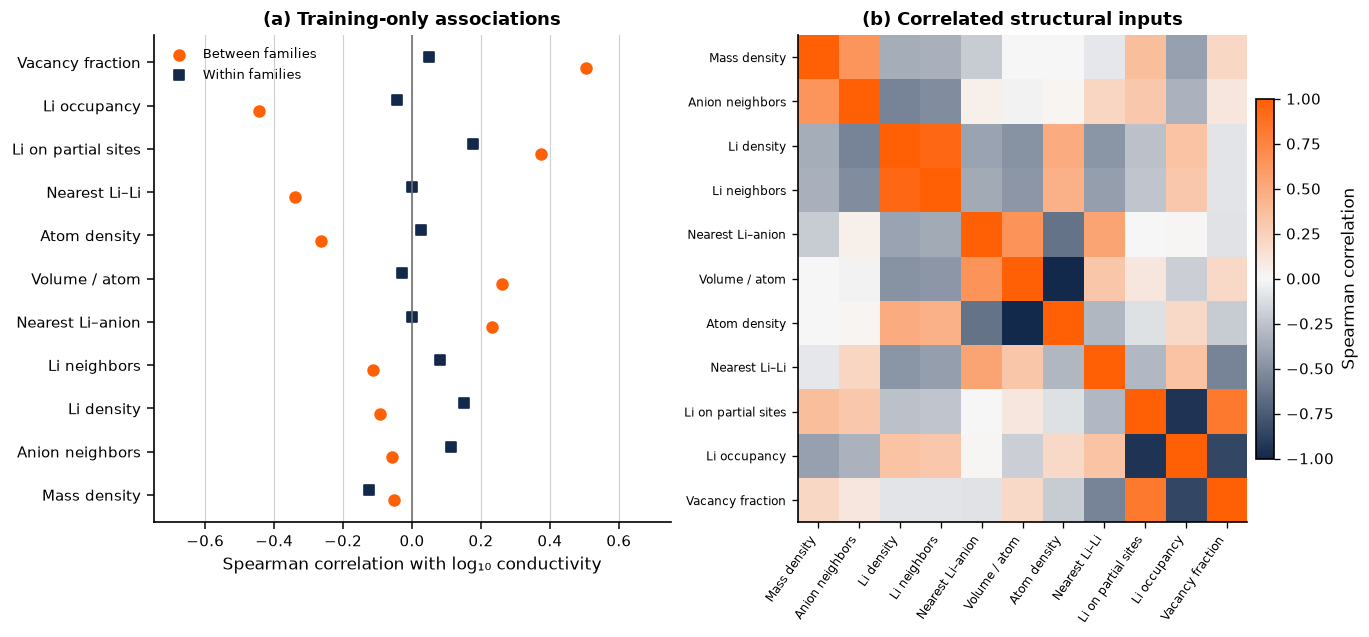

In [38]:
short_names={
    "expected_li_density_A_minus3":"Li density",
    "expected_atom_density_A_minus3":"Atom density",
    "volume_per_expected_atom_A3":"Volume / atom",
    "density_g_cm3":"Mass density",
    "mean_li_site_occupancy":"Li occupancy",
    "li_fraction_on_partial_sites":"Li on partial sites",
    "mean_li_neighbors_4A":"Li neighbors",
    "mean_nearest_li_li_A":"Nearest Li–Li",
    "mean_anion_neighbors_3p2A":"Anion neighbors",
    "mean_nearest_li_anion_A":"Nearest Li–anion",
    "overall_vacancy_fraction":"Vacancy fraction",
}
ordered_eda=eda_table.iloc[::-1]
fig,axes=plt.subplots(1,2,figsize=(11.3,5.2),
    gridspec_kw={"width_ratios":[1.15,1]},constrained_layout=True)
yy=np.arange(len(ordered_eda))
axes[0].scatter(ordered_eda.family_median_spearman,yy-.12,
    color=ILLINI_ORANGE,s=42,label="Between families")
axes[0].scatter(ordered_eda.within_family_spearman,yy+.12,
    color=ILLINI_BLUE,marker="s",s=35,label="Within families")
axes[0].axvline(0,color=ILLINI_STORM,lw=1)
axes[0].set_yticks(yy,[short_names[x] for x in ordered_eda.feature])
axes[0].set_xlim(-.75,.75)
axes[0].set_xlabel("Spearman correlation with log₁₀ conductivity")
axes[0].set_title("(a) Training-only associations")
axes[0].legend(loc="upper left",fontsize=8)
finish_axis(axes[0],"x")

matrix=feature_corr.loc[ordered_eda.feature,ordered_eda.feature]
from matplotlib.colors import LinearSegmentedColormap
uiuc_diverging=LinearSegmentedColormap.from_list(
    "uiuc_diverging",[ILLINI_BLUE,"#F7F7F7",ILLINI_ORANGE])
im=axes[1].imshow(matrix,vmin=-1,vmax=1,cmap=uiuc_diverging,aspect="auto")
axes[1].set_xticks(range(len(matrix)),[short_names[x] for x in matrix.columns],
    rotation=55,ha="right",fontsize=7)
axes[1].set_yticks(range(len(matrix)),[short_names[x] for x in matrix.index],fontsize=7)
axes[1].set_title("(b) Correlated structural inputs")
fig.colorbar(im,ax=axes[1],fraction=.04,pad=.02,label="Spearman correlation")
save_report_figure(fig,"figure_09_training_structural_eda.png")
plt.show()

**Figure 9.** Associations use only the 159 labeled training CIFs. Orange points compare connected-family medians; blue points compare deviations *within* the 25 families with at least two records. Strong between-family correlations do not imply that changing one variable within a phase will improve conductivity. The heat map exposes redundant inputs; for example, atom number density and volume per atom encode the same reciprocal quantity. This motivates a smaller neural input set and controlled within-family comparisons, rather than a monotonic vacancy or spacing rule.

### MP-to-experiment feature-transfer check

The 35 already accepted MP–OBELiX geometric matches provide paired experimental-CIF and MP-relaxed structures. We calculate the **same** descriptors on both sides before using MP structural features for inference. A small geometric match residual does not guarantee that every transport descriptor is unchanged; this check identifies descriptors needing source-aware treatment. It does not add new conductivity labels.

In [39]:
MP_SHIFT_PATH=ROOT/"data/processed/mp_obelix_descriptor_shift.csv"
wide_cache=json.loads((ROOT/"data/raw/mp_obelix_wide_structures.json").read_text())
mp_structures=wide_cache["structures"]
accepted_pairs=wide_pairs.loc[
    wide_pairs.accepted_for_primary_structure_cohort
].sort_values("record_id")
assert len(accepted_pairs)==35
exp_features=structure_features.set_index("record_id")
shift_rows=[]
for pair in accepted_pairs.itertuples(index=False):
    mp_crystal=Structure.from_dict(mp_structures[pair.material_id])
    mp_values=occupancy_structure_descriptors(mp_crystal)
    exp_values=exp_features.loc[pair.record_id,STRUCTURE_COLUMNS]
    shift_rows.append({"record_id":pair.record_id,"material_id":pair.material_id,
        **{f"exp_{key}":float(exp_values[key]) for key in STRUCTURE_COLUMNS},
        **{f"mp_{key}":float(mp_values[key]) for key in STRUCTURE_COLUMNS}})
descriptor_shift=pd.DataFrame(shift_rows)
for key in STRUCTURE_COLUMNS:
    descriptor_shift[f"abs_delta_{key}"]=abs(
        descriptor_shift[f"mp_{key}"]-descriptor_shift[f"exp_{key}"])
descriptor_shift.to_csv(MP_SHIFT_PATH,index=False)
shift_summary=pd.DataFrame({
    "descriptor":["expected_li_density_A_minus3","volume_per_expected_atom_A3",
        "mean_nearest_li_li_A","mean_nearest_li_anion_A",
        "mean_li_neighbors_4A"],
})
shift_summary["median_absolute_MP_minus_CIF"]=shift_summary.descriptor.map(
    lambda key:descriptor_shift[f"abs_delta_{key}"].median())
display(shift_summary)
print(f"Paired transfer check: {len(descriptor_shift)} already matched structures; "
      "no new labels or conductivity rankings.")

,descriptor,median_absolute_MP_minus_CIF
0,expected_li_density_A_minus3,0.000392
1,volume_per_expected_atom_A3,0.274807
2,mean_nearest_li_li_A,0.070139
3,mean_nearest_li_anion_A,0.075496
4,mean_li_neighbors_4A,0.000000


Paired transfer check: 35 already matched structures; no new labels or conductivity rankings.


## 23. Senior-design model: a physical transport layer

The four-week deliverable is a **neural selection model and three to five reviewable material-design cards**, not a claim that one network predicts every solid electrolyte. We start with a small set of experimentally indexed parent phases and plausible, charge-balanced composition changes within their crystal families. A design card will state the parent structure, proposed change, predicted room-temperature conductivity range, synthesis source, Materials Project stability evidence, uncertainty, and a specific experiment that could disprove the prediction. Simulation is a later phase.

At 298.15 K, a testable physical layer is

$$\widehat\sigma=\frac{q^2 n_{\mathrm{Li}}}{k_{\mathrm B}T}\,D_{\mathrm{eff}},\qquad
D_{\mathrm{eff}}=10^{g_\theta(x)}\ \mathrm{cm^2\,s^{-1}},\qquad
n_{\mathrm{Li}}=10^{24}\frac{\sum_i p_i}{V_{\!\mathrm{\mathring A}^3}}\ \mathrm{cm^{-3}}.$$

Here $p_i$ is crystallographic Li-site occupancy and $g_\theta$ is the neural head. The layer makes conductivity positive and explicitly includes Li-site density. Because Li density also enters the neural features, the head can compensate for that factor; the factorization alone does not prove a monotonic or causal effect. **$D_{\mathrm{eff}}$ is an effective learned transport factor**, absorbing the unknown mobile-ion fraction and correlation effects; it is not a measured self-diffusion coefficient. The [Nernst–Einstein approximation](https://doi.org/10.1021/acs.chemmater.3c02726) motivates the factorization but can miss correlated motion in solid electrolytes. Because the current labels are essentially single-temperature, we cannot fit separately identifiable activation-energy and prefactor heads yet. A direct conductivity head remains the ablation, and further architecture choices use training-only connected-family validation.

In [40]:
PHYSICS_CV_PATH=ROOT/"data/processed/obelix_physics_head_train_cv.csv"
Q_COULOMB=1.602176634e-19
KB_J_PER_K=1.380649e-23
T_ROOM_K=298.15

physics_inputs=descriptor_inputs["Composition + structure MLP"][0]
li_density=descriptor_train.expected_li_density_A_minus3.to_numpy()*1e24
assert np.isfinite(li_density).all() and (li_density>0).all()
log_transport_factor=np.log10(Q_COULOMB**2*li_density/(KB_J_PER_K*T_ROOM_K))
target_log_sigma=descriptor_train[MODEL_TARGET].to_numpy()
target_log_deff=target_log_sigma-log_transport_factor

# Fixed architecture from prior train-only group CV; do not inspect the official test.
fixed_config={"hidden_layer_sizes":(16,),"alpha":1.0}
oof_direct=np.full(len(descriptor_train),np.nan)
oof_physics=np.full(len(descriptor_train),np.nan)
for fit_idx,val_idx in descriptor_folds:
    direct_members=[];physics_members=[]
    for seed in TUNING_SEEDS:
        direct_head=build_descriptor_mlp(fixed_config,seed)
        direct_head.fit(physics_inputs.iloc[fit_idx],target_log_sigma[fit_idx])
        direct_members.append(direct_head.predict(physics_inputs.iloc[val_idx]))
        mobility_head=build_descriptor_mlp(fixed_config,seed)
        mobility_head.fit(physics_inputs.iloc[fit_idx],target_log_deff[fit_idx])
        physics_members.append(log_transport_factor[val_idx]
            + mobility_head.predict(physics_inputs.iloc[val_idx]))
    oof_direct[val_idx]=np.mean(direct_members,axis=0)
    oof_physics[val_idx]=np.mean(physics_members,axis=0)
assert np.isfinite(oof_direct).all() and np.isfinite(oof_physics).all()

physics_cv=descriptor_train[["record_id","formula","group_linked",
    MODEL_TARGET]].copy()
physics_cv["li_site_density_cm_minus3"]=li_density
physics_cv["direct_oof_prediction"]=oof_direct
physics_cv["physics_oof_prediction"]=oof_physics
physics_cv["direct_abs_error_dex"]=abs(target_log_sigma-oof_direct)
physics_cv["physics_abs_error_dex"]=abs(target_log_sigma-oof_physics)
physics_cv.to_csv(PHYSICS_CV_PATH,index=False)

physics_group=physics_cv.groupby("group_linked")[["direct_abs_error_dex",
    "physics_abs_error_dex"]].mean()
physics_summary=pd.DataFrame({
    "head":["Direct conductivity NN","Physical transport-layer NN"],
    "record_weighted_CV_MAE_dex":[physics_cv.direct_abs_error_dex.mean(),
        physics_cv.physics_abs_error_dex.mean()],
    "group_balanced_CV_MAE_dex":[physics_group.direct_abs_error_dex.mean(),
        physics_group.physics_abs_error_dex.mean()],
    "train_groups":[physics_cv.group_linked.nunique()]*2,
})
display(physics_summary)
print("Physical-layer ablation uses only 159 training records; "
      "the official test set was not queried.")

,head,record_weighted_CV_MAE_dex,group_balanced_CV_MAE_dex,train_groups
0,Direct conductivity NN,1.475511,1.847898,68
1,Physical transport-layer NN,1.482671,1.856098,68


Physical-layer ablation uses only 159 training records; the official test set was not queried.


### Experimental feasibility before candidate ranking

The existing Materials Project query supplies *computed* phase-hull and band-gap data, but neither guarantees synthesis, room-temperature stability, ionic conductivity, or interface compatibility. We use its `theoretical=False` flag only as evidence that a calculated phase matches an experimentally indexed structure; final design cards still need the actual synthesis paper and a feasible preparation route. The [Materials Project glossary](https://docs.materialsproject.org/frequently-asked-questions/glossary-of-terms) describes hull energy as a zero-temperature stability guide, and the [structure documentation](https://docs.materialsproject.org/methodology/materials-methodology/understanding-structures-and-properties-in-the-materials-project) notes the different origins of structures. Battery performance additionally requires interface assessment ([review](https://doi.org/10.1038/s41578-019-0157-5)).

The table below is a **metadata review funnel, not a conductivity ranking**. Its final rows remain candidates for literature review, not recommended compounds. A parent phase is eligible for a design card only after exact structure identity, experimental synthesis conditions, chemical handling, and electrode compatibility are checked. Variations must preserve charge balance and stay within a documented prototype family.

In [41]:
PRACTICAL_MP_PATH=ROOT/"data/processed/mp_senior_design_review_pool.csv"
review_mask=(mp_domain_audit.theoretical.eq(False)
    & mp_domain_audit.in_approximate_composition_domain
    & mp_domain_audit.chemical_system_seen_in_training)
practical_mp_pool=mp_domain_audit.loc[review_mask,[
    "material_id","formula_pretty","chemsys","elements",
    "space_group_symbol","space_group_number","band_gap_eV",
    "energy_above_hull_eV_atom","is_stable","theoretical",
    "nearest_training_distance","mp_database_version",
]].copy()
practical_mp_pool["hull_review_tier"]=(
    np.where(practical_mp_pool.energy_above_hull_eV_atom.le(0.025),
             "<=25 meV/atom","25-50 meV/atom"))
practical_mp_pool["synthesis_route_verified"]=False
practical_mp_pool["interface_compatibility_verified"]=False
practical_mp_pool["conductivity_prediction_status"]="not ranked"
practical_mp_pool.to_csv(PRACTICAL_MP_PATH,index=False)

feasibility_counts=pd.Series({
    "MP broad prescreen (Li, nonmetal, band gap, hull)":len(mp_domain_audit),
    "experimentally indexed structure flag":int((mp_domain_audit.theoretical.eq(False)).sum()),
    "also within approximate composition domain":int((mp_domain_audit.theoretical.eq(False)
        & mp_domain_audit.in_approximate_composition_domain).sum()),
    "also in training-observed chemical systems":len(practical_mp_pool),
    "review priority at <=25 meV/atom":int(
        practical_mp_pool.energy_above_hull_eV_atom.le(.025).sum()),
},name="records")
display(feasibility_counts.to_frame())
assert len(practical_mp_pool)==115
assert practical_mp_pool.conductivity_prediction_status.eq("not ranked").all()
print("Design-card target: 3-5 literature-verified parent phases and controlled variants; "
      "no claim of experimental stability from MP metadata alone.")

,records
"MP broad prescreen (Li, nonmetal, band gap, hull)",5068
experimentally indexed structure flag,1116
also within approximate composition domain,409
also in training-observed chemical systems,115
review priority at <=25 meV/atom,102


Design-card target: 3-5 literature-verified parent phases and controlled variants; no claim of experimental stability from MP metadata alone.


### Neural-network decision from this EDA

The immediate model remains a **small neural network with an explicit Li-density transport layer**. Its inputs are elemental fractions and a limited set of independently informative occupancy and geometry descriptors; a periodic graph encoder is a later ablation only if it improves connected-family validation on enough trustworthy structures. We will compare direct versus physical heads using equal-weight-per-family error and high-conductor retrieval. Correlated inputs will be reduced through train-fold ablations, and no universal monotonic constraint will be imposed on vacancy fraction or Li spacing. At one temperature, $E_a$ and the prefactor remain unidentifiable. The physical layer organizes the prediction; it does not prove a mechanism or stability. The final senior-design output is three to five **literature-verified, near-stable parent phases with one controlled substitution hypothesis each**, plus explicit uncertainty and a proposed experiment. No MP phase is called optimized until the model and feasibility checks support that claim.

**Next train-only architecture experiment.** Use a compact composition branch (element fractions) and a compact structure branch (Li-site density, volume per expected atom, one occupancy/vacancy descriptor, nearest Li–Li and Li–anion distances, and Li–anion coordination). Compare correlated alternatives in training-only ablations; do not enter both atom density and reciprocal volume per atom by default. Fuse the branches into a 16-unit neural layer with (i) the effective-transport output $g_\theta$ in the physical equation and (ii) a sigmoid probability that room-temperature conductivity exceeds $10^{-4}$ S/cm. A simple group-balanced objective is

$$\mathcal L=\frac{1}{G}\sum_{g=1}^{G}\frac{1}{n_g}\sum_{i\in g}
\left[\operatorname{Huber}(y_i,\hat y_i)+\lambda\,\operatorname{BCE}(\mathbf 1[y_i\ge-4],p_i)\right].$$

The binary label comes from the same conductivity measurement, so this is a decision-oriented auxiliary task, not independent physical evidence. Tune $\lambda$ and the feature subset within connected-family folds only; compare against the direct-head neural baseline and report group-diverse precision and missed high-conductivity families. The first transport-layer ablation is essentially tied with the direct head on 68 training groups, so the physical form is retained for interpretability and must earn its place through the next ablation. Explicit charge-balance and MP feasibility gates apply to proposed substitutions outside the conductivity loss.